In [1]:

!git clone https://github.com/SynergIA-Lab/pneumoniacnn.git

import os
import tensorflow as tf

ROOT = "/kaggle/working/pneumoniacnn"

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
print("Repository files:", os.listdir(ROOT))


Cloning into 'pneumoniacnn'...
remote: Enumerating objects: 18285, done.
remote: Counting objects: 100% (781/781), done.
remote: Compressing objects: 100% (440/440), done.
remote: Total 18285 (delta 368), reused 715 (delta 313), pack-reused 17504 (from 4)
Receiving objects: 100% (18285/18285), 2.92 GiB | 30.98 MiB/s, done.
Resolving deltas: 100% (402/402), done.
Updating files: 100% (17930/17930), done.


I0000 00:00:1794885837.164776      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794885858.694475      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.21.0
GPUs: []
Repository files: ['LICENSE', 'ExternalDataset', 'code', 'setup.py', 'Results', 'Images', 'requirements.txt', '.git', 'README.rst']


E0000 00:00:1794885864.119543      50 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [2]:

from pathlib import Path

DOWNLOAD_DIR = Path("/kaggle/working/checkpoint_downloads")
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

BASE_URL = "https://zenodo.org/records/21620538/files/"

files = [
    "MobileNetV2_trainedmodels.zip",
    "Training Dataset Splits.zip"
]

import subprocess

for filename in files:
    url = BASE_URL + filename.replace(" ", "%20") + "?download=1"
    destination = DOWNLOAD_DIR / filename

    if destination.exists() and destination.stat().st_size > 0:
        print("Already downloaded:", filename)
        continue

    print("Downloading:", filename)
    subprocess.run(
        ["wget", "-c", "--progress=bar:force",
         "-O", str(destination), url],
        check=True
    )

print("Downloads completed.")


Downloading: MobileNetV2_trainedmodels.zip


--2026-11-17 03:25:47--  https://zenodo.org/records/21620538/files/MobileNetV2_trainedmodels.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.42.113, 188.185.47.192, 188.185.51.60, ...
Connecting to zenodo.org (zenodo.org)|188.185.42.113|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 86700885 (83M) [application/octet-stream]
Saving to: ‘/kaggle/working/checkpoint_downloads/MobileNetV2_trainedmodels.zip’

/kaggle/working/che 100%[===================>]  82.68M  14.6MB/s    in 9.8s    

2026-11-17 03:25:57 (8.46 MB/s) - ‘/kaggle/working/checkpoint_downloads/MobileNetV2_trainedmodels.zip’ saved [86700885/86700885]

--2026-11-17 03:25:57--  https://zenodo.org/records/21620538/files/Training%20Dataset%20Splits.zip?download=1
Resolving zenodo.org (zenodo.org)... 137.138.121.78, 188.185.45.63, 188.185.42.113, ...
Connecting to zenodo.org (zenodo.org)|137.138.121.78|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 108406 (106K) [app

Downloading: Training Dataset Splits.zip
Downloads completed.


/kaggle/working/che 100%[===================>] 105.87K  --.-KB/s    in 0.08s   

2026-11-17 03:25:58 (1.28 MB/s) - ‘/kaggle/working/checkpoint_downloads/Training Dataset Splits.zip’ saved [108406/108406]



In [3]:

import zipfile

for archive in DOWNLOAD_DIR.glob("*.zip"):
    print("\nARCHIVE:", archive.name)
    print("Size:", round(archive.stat().st_size / 1024**2, 2), "MB")

    with zipfile.ZipFile(archive) as z:
        names = z.namelist()
        print("Total entries:", len(names))
        for name in names[:25]:
            print(" ", name)

        if len(names) > 25:
            print(" ... additional entries omitted")



ARCHIVE: MobileNetV2_trainedmodels.zip
Size: 82.68 MB
Total entries: 5
  final_fold2.keras
  final_fold1.keras
  final_fold3.keras
  final_fold4.keras
  final_fold5.keras

ARCHIVE: Training Dataset Splits.zip
Size: 0.1 MB
Total entries: 21
  Training Dataset Splits/
  Training Dataset Splits/train_split_fold3.csv
  __MACOSX/Training Dataset Splits/._train_split_fold3.csv
  Training Dataset Splits/train_split_fold2.csv
  __MACOSX/Training Dataset Splits/._train_split_fold2.csv
  Training Dataset Splits/train_split_fold1.csv
  __MACOSX/Training Dataset Splits/._train_split_fold1.csv
  Training Dataset Splits/train_split_fold5.csv
  __MACOSX/Training Dataset Splits/._train_split_fold5.csv
  Training Dataset Splits/train_split_fold4.csv
  __MACOSX/Training Dataset Splits/._train_split_fold4.csv
  Training Dataset Splits/test_split_fold5.csv
  __MACOSX/Training Dataset Splits/._test_split_fold5.csv
  Training Dataset Splits/test_split_fold4.csv
  __MACOSX/Training Dataset Splits/._test_spl

In [4]:

from pathlib import Path
import zipfile

BASE = Path("/kaggle/working")
DOWNLOAD_DIR = BASE / "checkpoint_downloads"

MODEL_DIR = BASE / "models" / "MobileNetV2"
SPLIT_DIR = BASE / "splits"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(
    DOWNLOAD_DIR / "MobileNetV2_trainedmodels.zip"
) as z:
    z.extractall(MODEL_DIR)

with zipfile.ZipFile(
    DOWNLOAD_DIR / "Training Dataset Splits.zip"
) as z:
    z.extractall(SPLIT_DIR)

print("MODEL FILES:")
for f in sorted(MODEL_DIR.rglob("*.keras")):
    print(f.name)

print("\nDATASET SPLITS:")
for f in sorted(SPLIT_DIR.rglob("*.csv")):
    print(f.name)


MODEL FILES:
final_fold1.keras
final_fold2.keras
final_fold3.keras
final_fold4.keras
final_fold5.keras

DATASET SPLITS:
test_split_fold1.csv
test_split_fold2.csv
test_split_fold3.csv
test_split_fold4.csv
test_split_fold5.csv
train_split_fold1.csv
train_split_fold2.csv
train_split_fold3.csv
train_split_fold4.csv
train_split_fold5.csv
._test_split_fold1.csv
._test_split_fold2.csv
._test_split_fold3.csv
._test_split_fold4.csv
._test_split_fold5.csv
._train_split_fold1.csv
._train_split_fold2.csv
._train_split_fold3.csv
._train_split_fold4.csv
._train_split_fold5.csv


In [5]:

import pandas as pd

csv_path = (
    SPLIT_DIR
    / "Training Dataset Splits"
    / "test_split_fold1.csv"
)

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst 5 rows:")
print(df.head().to_string(index=False))

print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (1172, 5)

Columns: ['filepath', 'label_id', 'fold', 'seed', 'split']

First 5 rows:
                              filepath  label_id  fold  seed split
     /Dataset/NORMAL/IM-0529-0001.jpeg         0     1    42  test
     /Dataset/NORMAL/IM-0534-0001.jpeg         0     1    42  test
/Dataset/NORMAL/IM-0533-0001-0002.jpeg         0     1    42  test
/Dataset/NORMAL/IM-0525-0001-0001.jpeg         0     1    42  test
     /Dataset/NORMAL/IM-0536-0001.jpeg         0     1    42  test

Missing values:
filepath    0
label_id    0
fold        0
seed        0
split       0
dtype: int64


In [6]:

import tensorflow as tf

model_path = MODEL_DIR / "final_fold1.keras"

model = tf.keras.models.load_model(
    model_path,
    compile=False
)

print("Model loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Total parameters:", model.count_params())

print("\nLast 5 layers:")
for layer in model.layers[-5:]:
    print(layer.name, layer.__class__.__name__)


Model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Total parameters: 3045441

Last 5 layers:
dense_48 Dense
dropout_32 Dropout
dense_49 Dense
dropout_33 Dropout
dense_50 Dense


In [7]:

from pathlib import Path

CODE_DIR = Path(
    "/kaggle/working/pneumoniacnn/code"
)

keywords = [
    "preprocess_input",
    "rescale",
    "load_img",
    "image_dataset_from_directory",
    "flow_from_dataframe",
    "ImageDataGenerator",
    "resize",
    "normalization"
]

for filename in sorted(CODE_DIR.glob("*.py")):
    lines = filename.read_text(
        encoding="utf-8", errors="replace"
    ).splitlines()

    matches = [
        (i, line.strip())
        for i, line in enumerate(lines, start=1)
        if any(k.lower() in line.lower() for k in keywords)
    ]

    if matches:
        print(f"\n--- {filename.name} ---")
        for number, line in matches[:35]:
            print(f"{number}: {line[:180]}")



--- 1_tune_hyperparameters.py ---
65: img = tf.image.resize(img, IMG_SIZE)

--- 2_train_kfold_fined_study.py ---
87: img = tf.image.resize(img, IMG_SIZE)
266: if not isinstance(layer, layers.BatchNormalization):

--- 2_train_kfold_original.py ---
88: img = tf.image.resize(img, IMG_SIZE)

--- 3_external_validation.py ---
92: img = tf.image.resize(img, IMG_SIZE)

--- 4_xai_qualitative.py ---
57: img = tf.image.resize(img, IMG_SIZE)
76: def load_img(path):
79: img = tf.image.resize(img, IMG_SIZE)
134: cam = tf.image.resize(cam[..., None], IMG_SIZE).numpy().squeeze()
153: img = load_img(p)

--- 5_xai_quantitative.py ---
62: img = tf.image.resize(img, IMG_SIZE)
81: def load_img(path):
84: img = tf.image.resize(img, IMG_SIZE)
142: cam = tf.image.resize(cam[..., None], IMG_SIZE).numpy().squeeze()
276: img = load_img(path)


In [9]:

import requests

record_id = "21620538"

url = f"https://zenodo.org/api/records/{record_id}"
response = requests.get(url, timeout=30)
response.raise_for_status()

record = response.json()

print("AVAILABLE FILES:\n")

for f in record["files"]:
    print("Name:", f["key"])
    print("Size:", round(f["size"] / 1024**2, 2), "MB")
    print("-" * 40)


AVAILABLE FILES:

Name: Original Dataset.zip
Size: 1592.11 MB
----------------------------------------
Name: MobileNetV2_trainedmodels.zip
Size: 82.68 MB
----------------------------------------
Name: DenseNet121_trainedmodels.zip
Size: 160.6 MB
----------------------------------------
Name: ConvNextTiny_trainedmodels.zip
Size: 513.97 MB
----------------------------------------
Name: ResNet50_trainedmodels.zip
Size: 451.3 MB
----------------------------------------
Name: EfficientNetB0_trainedmodels.zip
Size: 108.91 MB
----------------------------------------
Name: VGG16_trainedmodels.zip
Size: 277.69 MB
----------------------------------------
Name: Training Dataset Splits.zip
Size: 0.1 MB
----------------------------------------


In [10]:

import pandas as pd

print("Fold 1 test distribution:")
print(df["label_id"].value_counts().sort_index())

print("\nExample files from each class:")
for label in [0, 1]:
    print(f"\nClass {label}:")
    print(
        df.loc[df["label_id"] == label, "filepath"]
        .head(3).to_string(index=False)
    )


Fold 1 test distribution:
label_id
0    317
1    855
Name: count, dtype: int64

Example files from each class:

Class 0:
     /Dataset/NORMAL/IM-0529-0001.jpeg
     /Dataset/NORMAL/IM-0534-0001.jpeg
/Dataset/NORMAL/IM-0533-0001-0002.jpeg

Class 1:
   /Dataset/PNEUMONIA/person539_virus_1069.jpeg
   /Dataset/PNEUMONIA/person553_virus_1093.jpeg
/Dataset/PNEUMONIA/person531_bacteria_2235.jpeg


In [11]:

from pathlib import Path
import subprocess

DATA_DIR = Path("/kaggle/working/original_dataset")
DATA_DIR.mkdir(parents=True, exist_ok=True)

zip_path = DATA_DIR / "Original Dataset.zip"

url = (
    "https://zenodo.org/records/21620538/files/"
    "Original%20Dataset.zip?download=1"
)

print("Downloading original dataset...")

subprocess.run(
    [
        "wget",
        "-c",
        "--progress=bar:force",
        "-O", str(zip_path),
        url
    ],
    check=True
)

print("\nDownload complete!")
print(
    "File size:",
    round(zip_path.stat().st_size / 1024**2, 2),
    "MB"
)


--2026-11-17 03:33:19--  https://zenodo.org/records/21620538/files/Original%20Dataset.zip?download=1
Resolving zenodo.org (zenodo.org)... 137.138.121.78, 188.185.47.192, 188.185.42.113, ...
Connecting to zenodo.org (zenodo.org)|137.138.121.78|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1669450144 (1.6G) [application/octet-stream]
Saving to: ‘/kaggle/working/original_dataset/Original Dataset.zip’

working/original_da  99%[==================> ]   1.55G  19.4MB/s    eta 1s     


Download complete!
File size: 1592.11 MB


/kaggle/working/ori 100%[===================>]   1.55G  20.5MB/s    in 81s     

2026-11-17 03:34:40 (19.6 MB/s) - ‘/kaggle/working/original_dataset/Original Dataset.zip’ saved [1669450144/1669450144]



In [12]:

import zipfile

extract_dir = DATA_DIR / "extracted"
extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path) as z:
    print("Archive entries:", len(z.namelist()))
    print("\nFirst 10 entries:")
    for name in z.namelist()[:10]:
        print(name)

    print("\nExtracting dataset...")
    z.extractall(extract_dir)

print("\nExtraction complete!")

print("\nDataset folders:")
for path in sorted(extract_dir.iterdir()):
    print(path)


Archive entries: 34800

First 10 entries:
ExternalDataset/
__MACOSX/._ExternalDataset
ExternalDataset/.DS_Store
__MACOSX/ExternalDataset/._.DS_Store
ExternalDataset/PNEUMONIA/
__MACOSX/ExternalDataset/._PNEUMONIA
ExternalDataset/NORMAL/
__MACOSX/ExternalDataset/._NORMAL
ExternalDataset/PNEUMONIA/Viral Pneumonia-770.png
__MACOSX/ExternalDataset/PNEUMONIA/._Viral Pneumonia-770.png

Extracting dataset...

Extraction complete!

Dataset folders:
/kaggle/working/original_dataset/extracted/ExternalDataset
/kaggle/working/original_dataset/extracted/Images
/kaggle/working/original_dataset/extracted/__MACOSX


In [13]:

from pathlib import Path

# Build filename lookup from extracted image files.
image_files = list(extract_dir.rglob("*.jpeg"))
image_files += list(extract_dir.rglob("*.jpg"))
image_files += list(extract_dir.rglob("*.png"))

print("Total images found:", len(image_files))

# Match by class folder + filename, not filename alone.
image_lookup = {}

for path in image_files:
    key = (path.parent.name.upper(), path.name)
    image_lookup.setdefault(key, []).append(path)

matched = []
missing = []
ambiguous = []

for original_path in df["filepath"]:
    original = Path(original_path)
    key = (original.parent.name.upper(), original.name)

    candidates = image_lookup.get(key, [])

    if len(candidates) == 1:
        matched.append(candidates[0])
    elif len(candidates) == 0:
        missing.append(original_path)
    else:
        ambiguous.append(original_path)

print("Matched:", len(matched))
print("Missing:", len(missing))
print("Ambiguous:", len(ambiguous))

if missing:
    print("\nFirst missing files:")
    print(*missing[:5], sep="\n")

if ambiguous:
    print("\nFirst ambiguous files:")
    print(*ambiguous[:5], sep="\n")


Total images found: 34786
Matched: 1172
Missing: 0
Ambiguous: 0


In [14]:

import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path

IMG_SIZE = (224, 224)
BATCH_SIZE = 64

# Build a reliable image lookup from the extracted dataset
image_lookup = {}

for path in extract_dir.rglob("*"):
    if path.is_file() and path.suffix.lower() in [
        ".jpeg", ".jpg", ".png"
    ]:
        key = (path.parent.name.upper(), path.name)
        image_lookup.setdefault(key, []).append(path)

def resolve_image(original_path):
    p = Path(original_path)
    key = (p.parent.name.upper(), p.name)
    matches = image_lookup.get(key, [])

    if len(matches) != 1:
        raise ValueError(
            f"Expected one match for {original_path}, "
            f"found {len(matches)}"
        )

    return str(matches[0])

# Original Fold 1 test split
test_df = pd.read_csv(
    SPLIT_DIR / "Training Dataset Splits" / "test_split_fold1.csv"
)

test_df["actual_path"] = test_df["filepath"].apply(resolve_image)

print("Total test samples:", len(test_df))
print("Class distribution:")
print(test_df["label_id"].value_counts().sort_index())

# Original preprocessing
def load_image(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0
    return img

test_ds = tf.data.Dataset.from_tensor_slices(
    test_df["actual_path"].tolist()
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("\nEvaluation dataset ready!")


Total test samples: 1172
Class distribution:
label_id
0    317
1    855
Name: count, dtype: int64

Evaluation dataset ready!


In [17]:

import tensorflow as tf
import numpy as np
import pandas as pd
import gc
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    confusion_matrix
)

# ==========================================
# 1. CONFIGURATION
# ==========================================

BASE = Path("/kaggle/working")

MODEL_DIR = BASE / "models" / "MobileNetV2"
SPLIT_DIR = BASE / "splits" / "Training Dataset Splits"
DATA_DIR = BASE / "original_dataset" / "extracted"

OUTPUT_DIR = BASE / "reproduction_results" / "MobileNetV2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = (224, 224)
BATCH_SIZE = 64

# ==========================================
# 2. BUILD IMAGE LOOKUP
# ==========================================

print("Indexing dataset images...")

image_lookup = {}

for path in DATA_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in (
        ".jpeg", ".jpg", ".png"
    ):
        key = (path.parent.name.upper(), path.name)
        image_lookup.setdefault(key, []).append(str(path))

def resolve_image(original_path):
    p = Path(original_path)
    key = (p.parent.name.upper(), p.name)

    matches = image_lookup.get(key, [])

    if len(matches) != 1:
        raise ValueError(
            f"Image match error: {original_path} "
            f"(found {len(matches)})"
        )

    return matches[0]

# ==========================================
# 3. PREPROCESSING
# ==========================================

def load_image(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(
        img, channels=3, expand_animations=False
    )
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0
    return img

# ==========================================
# 4. EVALUATE ALL FIVE FOLDS
# ==========================================

all_results = []

for fold in range(1, 6):

    print(f"\n{'='*50}")
    print(f"MOBILENETV2 — FOLD {fold}/5")
    print(f"{'='*50}")

    # Load test split
    test_df = pd.read_csv(
        SPLIT_DIR / f"test_split_fold{fold}.csv"
    )

    test_df["actual_path"] = test_df[
        "filepath"
    ].apply(resolve_image)

    # Create TensorFlow dataset
    test_ds = tf.data.Dataset.from_tensor_slices(
        test_df["actual_path"].tolist()
    )

    test_ds = test_ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    ).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    # Load model
    tf.keras.backend.clear_session()

    model = tf.keras.models.load_model(
        MODEL_DIR / f"final_fold{fold}.keras",
        compile=False
    )

    # Predictions
    y_true = test_df["label_id"].to_numpy().astype(int)
    y_prob = model.predict(test_ds, verbose=1).reshape(-1)

    assert len(y_true) == len(y_prob)
    assert np.all(np.isfinite(y_prob))

    y_pred = (y_prob >= 0.5).astype(int)

    # Metrics
    fold_results = {
        "Model": "MobileNetV2",
        "Fold": fold,
        "Samples": len(y_true),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Average Precision": average_precision_score(
            y_true, y_prob
        ),
        "MCC": matthews_corrcoef(y_true, y_pred)
    }

    all_results.append(fold_results)

    # Save fold metrics
    pd.DataFrame([fold_results]).to_csv(
        OUTPUT_DIR / f"fold{fold}_metrics.csv",
        index=False
    )

    # Save fold predictions
    prediction_df = test_df[
        ["filepath", "label_id"]
    ].copy()

    prediction_df["y_prob"] = y_prob
    prediction_df["y_pred"] = y_pred

    prediction_df.to_csv(
        OUTPUT_DIR / f"fold{fold}_predictions.csv",
        index=False
    )

    # Save confusion matrix
    cm = confusion_matrix(y_true, y_pred)

    pd.DataFrame(
        cm,
        index=["Actual_Normal", "Actual_Pneumonia"],
        columns=["Pred_Normal", "Pred_Pneumonia"]
    ).to_csv(
        OUTPUT_DIR / f"fold{fold}_confusion_matrix.csv"
    )

    print(f"\nFold {fold} Results:")
    print(
        pd.DataFrame([fold_results]).to_string(
            index=False
        )
    )
    print("\nConfusion Matrix:")
    print(cm)

    del model, test_ds
    gc.collect()

# ==========================================
# 5. FINAL FIVE-FOLD SUMMARY
# ==========================================

results_df = pd.DataFrame(all_results)

metric_cols = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "Average Precision",
    "MCC"
]

summary_df = results_df[metric_cols].agg(
    ["mean", "std"]
)

# Save complete results
results_df.to_csv(
    OUTPUT_DIR / "all_folds_metrics.csv",
    index=False
)

summary_df.to_csv(
    OUTPUT_DIR / "five_fold_summary.csv"
)

print("\n" + "="*60)
print("ALL FIVE FOLDS RESULTS")
print("="*60)
print(results_df.to_string(index=False))

print("\n" + "="*60)
print("FIVE-FOLD MEAN ± STANDARD DEVIATION")
print("="*60)
print(summary_df.round(4).to_string())

print("\nAll results saved to:", OUTPUT_DIR)


Indexing dataset images...

MOBILENETV2 — FOLD 1/5
19/19 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step

Fold 1 Results:
      Model  Fold  Samples  Accuracy  Precision  Recall  F1-score  ROC-AUC  Average Precision      MCC
MobileNetV2     1     1172  0.938567   0.946408 0.97076   0.95843 0.982725           0.993121 0.841851

Confusion Matrix:
[[270  47]
 [ 25 830]]

MOBILENETV2 — FOLD 2/5
19/19 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step

Fold 2 Results:
      Model  Fold  Samples  Accuracy  Precision  Recall  F1-score  ROC-AUC  Average Precision      MCC
MobileNetV2     2     1171    0.9462   0.940914 0.98829  0.964021 0.989746           0.996251 0.861751

Confusion Matrix:
[[264  53]
 [ 10 844]]

MOBILENETV2 — FOLD 3/5
19/19 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step

Fold 3 Results:
      Model  Fold  Samples  Accuracy  Precision   Recall  F1-score  ROC-AUC  Average Precision      MCC
MobileNetV2     3     1171  0.920581   0.906083 0.994145  0.948074  0.98542           0.994327 0.796201

Confusion Matrix:
[[229  88]

In [18]:

import requests
import zipfile
from pathlib import Path

BASE = Path("/kaggle/working")
DOWNLOAD_DIR = BASE / "checkpoint_downloads"
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

record = requests.get(
    "https://zenodo.org/api/records/21620538",
    timeout=30
).json()

files = {
    f["key"]: f["links"]["self"]
    for f in record["files"]
}

models = ["DenseNet121", "VGG16"]

for model_name in models:
    filename = f"{model_name}_trainedmodels.zip"
    archive_path = DOWNLOAD_DIR / filename
    model_dir = BASE / "models" / model_name
    model_dir.mkdir(parents=True, exist_ok=True)

    if not archive_path.exists():
        print(f"\nDownloading {filename}...")

        with requests.get(
            files[filename], stream=True, timeout=120
        ) as response:
            response.raise_for_status()
            with open(archive_path, "wb") as output:
                for chunk in response.iter_content(
                    chunk_size=1024 * 1024
                ):
                    if chunk:
                        output.write(chunk)

    print(f"\nExtracting {model_name}...")

    with zipfile.ZipFile(archive_path) as z:
        assert z.testzip() is None, "Corrupt archive"
        z.extractall(model_dir)

    checkpoints = sorted(model_dir.rglob("*.keras"))

    print(f"{model_name}: {len(checkpoints)} checkpoints")

    for checkpoint in checkpoints:
        print(" ", checkpoint.name)

print("\nBoth models ready!")




Extracting DenseNet121...
DenseNet121: 5 checkpoints
  final_fold1.keras
  final_fold2.keras
  final_fold3.keras
  final_fold4.keras
  final_fold5.keras


Extracting VGG16...
VGG16: 10 checkpoints
  final_fold1.keras
  final_fold2.keras
  final_fold3.keras
  final_fold4.keras
  final_fold5.keras
  ._final_fold1.keras
  ._final_fold2.keras
  ._final_fold3.keras
  ._final_fold4.keras
  ._final_fold5.keras

Both models ready!


In [19]:

import tensorflow as tf
import numpy as np
import pandas as pd
import gc
from pathlib import Path

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    matthews_corrcoef, confusion_matrix
)

# ==========================================
# 1. CONFIGURATION
# ==========================================

BASE = Path("/kaggle/working")
MODEL_ROOT = BASE / "models"
SPLIT_DIR = BASE / "splits" / "Training Dataset Splits"
DATA_DIR = BASE / "original_dataset" / "extracted"
RESULTS_DIR = BASE / "reproduction_results"

IMG_SIZE = (224, 224)
BATCH_SIZE = 64

MODELS_TO_EVALUATE = ["DenseNet121", "VGG16"]

# ==========================================
# 2. IMAGE LOOKUP
# ==========================================

print("Indexing images...")

image_lookup = {}

for path in DATA_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in (
        ".jpeg", ".jpg", ".png"
    ):
        key = (path.parent.name.upper(), path.name)
        image_lookup.setdefault(key, []).append(str(path))

def resolve_image(original_path):
    p = Path(original_path)
    key = (p.parent.name.upper(), p.name)
    matches = image_lookup.get(key, [])

    if len(matches) != 1:
        raise ValueError(
            f"Expected exactly one image: {original_path}, "
            f"found {len(matches)}"
        )
    return matches[0]

# ==========================================
# 3. PREPROCESSING
# ==========================================

def load_image(path):
    img = tf.io.read_file(path)

    img = tf.image.decode_image(
        img, channels=3, expand_animations=False
    )
    img.set_shape([None, None, 3])

    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0

    return img

# ==========================================
# 4. EVALUATE BOTH MODELS
# ==========================================

for model_name in MODELS_TO_EVALUATE:

    print(f"\n{'='*60}")
    print(f"EVALUATING {model_name}")
    print(f"{'='*60}")

    model_dir = MODEL_ROOT / model_name
    output_dir = RESULTS_DIR / model_name
    output_dir.mkdir(parents=True, exist_ok=True)

    all_results = []

    for fold in range(1, 6):

        print(f"\n--- {model_name} | Fold {fold}/5 ---")

        split_path = (
            SPLIT_DIR / f"test_split_fold{fold}.csv"
        )

        test_df = pd.read_csv(split_path)
        test_df["actual_path"] = test_df[
            "filepath"
        ].apply(resolve_image)

        test_ds = tf.data.Dataset.from_tensor_slices(
            test_df["actual_path"].tolist()
        )

        test_ds = test_ds.map(
            load_image,
            num_parallel_calls=tf.data.AUTOTUNE
        ).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

        tf.keras.backend.clear_session()

        checkpoint = model_dir / f"final_fold{fold}.keras"

        model = tf.keras.models.load_model(
            checkpoint,
            compile=False
        )

        y_true = test_df["label_id"].to_numpy().astype(int)
        y_prob = model.predict(
            test_ds, verbose=1
        ).reshape(-1)

        assert len(y_true) == len(y_prob)
        assert np.all(np.isfinite(y_prob))

        y_pred = (y_prob >= 0.5).astype(int)

        metrics = {
            "Model": model_name,
            "Fold": fold,
            "Samples": len(y_true),
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "F1-score": f1_score(
                y_true, y_pred, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(y_true, y_prob),
            "Average Precision": average_precision_score(
                y_true, y_prob
            ),
            "MCC": matthews_corrcoef(y_true, y_pred)
        }

        all_results.append(metrics)

        # Save metrics
        pd.DataFrame([metrics]).to_csv(
            output_dir / f"fold{fold}_metrics.csv",
            index=False
        )

        # Save predictions
        prediction_df = test_df[
            ["filepath", "label_id"]
        ].copy()

        prediction_df["y_prob"] = y_prob
        prediction_df["y_pred"] = y_pred

        prediction_df.to_csv(
            output_dir / f"fold{fold}_predictions.csv",
            index=False
        )

        # Save confusion matrix
        cm = confusion_matrix(y_true, y_pred)

        pd.DataFrame(
            cm,
            index=["Actual_Normal", "Actual_Pneumonia"],
            columns=["Pred_Normal", "Pred_Pneumonia"]
        ).to_csv(
            output_dir / f"fold{fold}_confusion_matrix.csv"
        )

        print(
            pd.DataFrame([metrics]).to_string(index=False)
        )
        print("Confusion matrix:")
        print(cm)

        del model, test_ds
        gc.collect()

    # ======================================
    # 5. MODEL SUMMARY
    # ======================================

    results_df = pd.DataFrame(all_results)

    metric_cols = [
        "Accuracy", "Precision", "Recall",
        "F1-score", "ROC-AUC",
        "Average Precision", "MCC"
    ]

    summary_df = results_df[metric_cols].agg(
        ["mean", "std"]
    )

    results_df.to_csv(
        output_dir / "all_folds_metrics.csv",
        index=False
    )

    summary_df.to_csv(
        output_dir / "five_fold_summary.csv"
    )

    print(f"\n{'='*60}")
    print(f"{model_name} - FIVE-FOLD SUMMARY")
    print(f"{'='*60}")
    print(summary_df.round(4).to_string())

print("\nALL MODEL EVALUATIONS COMPLETED!")


Indexing images...

EVALUATING DenseNet121

--- DenseNet121 | Fold 1/5 ---
19/19 ━━━━━━━━━━━━━━━━━━━━ 131s 7s/step
      Model  Fold  Samples  Accuracy  Precision  Recall  F1-score  ROC-AUC  Average Precision      MCC
DenseNet121     1     1172  0.948805   0.986536 0.94269  0.964115 0.987171           0.994659 0.877745
Confusion matrix:
[[306  11]
 [ 49 806]]

--- DenseNet121 | Fold 2/5 ---
19/19 ━━━━━━━━━━━━━━━━━━━━ 136s 7s/step
      Model  Fold  Samples  Accuracy  Precision   Recall  F1-score  ROC-AUC  Average Precision      MCC
DenseNet121     2     1171  0.961571   0.985594 0.961358  0.973325 0.993994           0.997898 0.905558
Confusion matrix:
[[305  12]
 [ 33 821]]

--- DenseNet121 | Fold 3/5 ---
19/19 ━━━━━━━━━━━━━━━━━━━━ 134s 7s/step
      Model  Fold  Samples  Accuracy  Precision   Recall  F1-score  ROC-AUC  Average Precision      MCC
DenseNet121     3     1171  0.958155   0.969662 0.973068  0.971362 0.989535           0.996027 0.893727
Confusion matrix:
[[291  26]
 [ 23 83

ValueError: File not found: filepath=/kaggle/working/models/VGG16/final_fold1.keras. Please ensure the file is an accessible `.keras` zip file.

In [20]:

from pathlib import Path

VGG_DIR = Path("/kaggle/working/models/VGG16")

print("VGG16 checkpoint locations:\n")

for path in sorted(VGG_DIR.rglob("*.keras")):
    print(path.relative_to(VGG_DIR), "| Exists:", path.is_file())


VGG16 checkpoint locations:

VGG16_trainedmodels/final_fold1.keras | Exists: True
VGG16_trainedmodels/final_fold2.keras | Exists: True
VGG16_trainedmodels/final_fold3.keras | Exists: True
VGG16_trainedmodels/final_fold4.keras | Exists: True
VGG16_trainedmodels/final_fold5.keras | Exists: True
__MACOSX/VGG16_trainedmodels/._final_fold1.keras | Exists: True
__MACOSX/VGG16_trainedmodels/._final_fold2.keras | Exists: True
__MACOSX/VGG16_trainedmodels/._final_fold3.keras | Exists: True
__MACOSX/VGG16_trainedmodels/._final_fold4.keras | Exists: True
__MACOSX/VGG16_trainedmodels/._final_fold5.keras | Exists: True


In [21]:

import tensorflow as tf
import numpy as np
import pandas as pd
import gc
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    matthews_corrcoef, confusion_matrix
)

BASE = Path("/kaggle/working")
VGG_DIR = BASE / "models" / "VGG16"
SPLIT_DIR = BASE / "splits" / "Training Dataset Splits"
DATA_DIR = BASE / "original_dataset" / "extracted"
OUTPUT_DIR = BASE / "reproduction_results" / "VGG16"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = (224, 224)
BATCH_SIZE = 64

# Find genuine checkpoints, excluding macOS metadata
checkpoints = {}

for fold in range(1, 6):
    matches = [
        p for p in VGG_DIR.rglob(f"final_fold{fold}.keras")
        if p.name == f"final_fold{fold}.keras"
        and "__MACOSX" not in p.parts
    ]

    if len(matches) != 1:
        raise RuntimeError(
            f"Fold {fold}: Expected 1 checkpoint, found {len(matches)}"
        )

    checkpoints[fold] = matches[0]

print("Resolved VGG16 checkpoints:")
for fold, path in checkpoints.items():
    print(f"Fold {fold}: {path}")

# Build image lookup
image_lookup = {}

for path in DATA_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in (
        ".jpeg", ".jpg", ".png"
    ):
        key = (path.parent.name.upper(), path.name)
        image_lookup.setdefault(key, []).append(str(path))

def resolve_image(original_path):
    p = Path(original_path)
    matches = image_lookup.get(
        (p.parent.name.upper(), p.name), []
    )

    if len(matches) != 1:
        raise ValueError(
            f"Image matching failed: {original_path}"
        )

    return matches[0]

def load_image(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(
        img, channels=3, expand_animations=False
    )
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    return tf.cast(img, tf.float32) / 255.0

all_results = []

for fold in range(1, 6):

    print(f"\n{'='*50}")
    print(f"VGG16 — FOLD {fold}/5")
    print(f"{'='*50}")

    test_df = pd.read_csv(
        SPLIT_DIR / f"test_split_fold{fold}.csv"
    )

    test_df["actual_path"] = test_df[
        "filepath"
    ].apply(resolve_image)

    test_ds = tf.data.Dataset.from_tensor_slices(
        test_df["actual_path"].tolist()
    ).map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    ).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    tf.keras.backend.clear_session()

    model = tf.keras.models.load_model(
        checkpoints[fold],
        compile=False
    )

    y_true = test_df["label_id"].to_numpy().astype(int)
    y_prob = model.predict(test_ds, verbose=1).reshape(-1)

    assert len(y_true) == len(y_prob)
    assert np.all(np.isfinite(y_prob))

    y_pred = (y_prob >= 0.5).astype(int)

    metrics = {
        "Model": "VGG16",
        "Fold": fold,
        "Samples": len(y_true),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Average Precision": average_precision_score(
            y_true, y_prob
        ),
        "MCC": matthews_corrcoef(y_true, y_pred)
    }

    all_results.append(metrics)

    pd.DataFrame([metrics]).to_csv(
        OUTPUT_DIR / f"fold{fold}_metrics.csv",
        index=False
    )

    test_df[["filepath", "label_id"]].assign(
        y_prob=y_prob,
        y_pred=y_pred
    ).to_csv(
        OUTPUT_DIR / f"fold{fold}_predictions.csv",
        index=False
    )

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    pd.DataFrame(
        cm,
        index=["Actual_Normal", "Actual_Pneumonia"],
        columns=["Pred_Normal", "Pred_Pneumonia"]
    ).to_csv(
        OUTPUT_DIR / f"fold{fold}_confusion_matrix.csv"
    )

    print(pd.DataFrame([metrics]).to_string(index=False))
    print("Confusion matrix:\n", cm)

    del model, test_ds
    gc.collect()

# Five-fold summary
results_df = pd.DataFrame(all_results)

metric_cols = [
    "Accuracy", "Precision", "Recall",
    "F1-score", "ROC-AUC", "Average Precision", "MCC"
]

summary_df = results_df[metric_cols].agg(["mean", "std"])

results_df.to_csv(
    OUTPUT_DIR / "all_folds_metrics.csv",
    index=False
)

summary_df.to_csv(
    OUTPUT_DIR / "five_fold_summary.csv"
)

print("\n===== VGG16 FIVE-FOLD SUMMARY =====")
print(summary_df.round(4).to_string())

print("\nResults saved to:", OUTPUT_DIR)


Resolved VGG16 checkpoints:
Fold 1: /kaggle/working/models/VGG16/VGG16_trainedmodels/final_fold1.keras
Fold 2: /kaggle/working/models/VGG16/VGG16_trainedmodels/final_fold2.keras
Fold 3: /kaggle/working/models/VGG16/VGG16_trainedmodels/final_fold3.keras
Fold 4: /kaggle/working/models/VGG16/VGG16_trainedmodels/final_fold4.keras
Fold 5: /kaggle/working/models/VGG16/VGG16_trainedmodels/final_fold5.keras

VGG16 — FOLD 1/5
19/19 ━━━━━━━━━━━━━━━━━━━━ 334s 17s/step
Model  Fold  Samples  Accuracy  Precision   Recall  F1-score  ROC-AUC  Average Precision      MCC
VGG16     1     1172    0.9343   0.970944 0.938012  0.954194 0.980124           0.992512 0.839738
Confusion matrix:
 [[293  24]
 [ 53 802]]

VGG16 — FOLD 2/5
19/19 ━━━━━━━━━━━━━━━━━━━━ 333s 17s/step
Model  Fold  Samples  Accuracy  Precision   Recall  F1-score  ROC-AUC  Average Precision      MCC
VGG16     2     1171  0.943638   0.974699 0.947307  0.960808 0.984275           0.994183 0.861684
Confusion matrix:
 [[296  21]
 [ 45 809]]

VG

In [22]:

import pandas as pd
from pathlib import Path

ROOT = Path("/kaggle/working/reproduction_results")
MODELS = ["MobileNetV2", "DenseNet121", "VGG16"]

metrics = [
    "Accuracy", "Precision", "Recall",
    "F1-score", "ROC-AUC", "Average Precision", "MCC"
]

rows = []
for name in MODELS:
    data = pd.read_csv(ROOT / name / "all_folds_metrics.csv")
    row = {"Model": name}
    for metric in metrics:
        row[f"{metric}_mean"] = data[metric].mean()
        row[f"{metric}_std"] = data[metric].std(ddof=1)
    rows.append(row)

summary = pd.DataFrame(rows)

formatted = pd.DataFrame({"Model": summary["Model"]})
for metric in metrics:
    formatted[metric] = [
        f"{m:.4f} ± {s:.4f}"
        for m, s in zip(
            summary[f"{metric}_mean"],
            summary[f"{metric}_std"]
        )
    ]

summary.to_csv(ROOT / "consolidated_metrics.csv", index=False)
formatted.to_csv(ROOT / "consolidated_table.csv", index=False)

print(formatted.to_string(index=False))
print("\nConsolidated tables saved successfully!")


      Model        Accuracy       Precision          Recall        F1-score         ROC-AUC Average Precision             MCC
MobileNetV2 0.9406 ± 0.0119 0.9398 ± 0.0195 0.9820 ± 0.0092 0.9603 ± 0.0074 0.9867 ± 0.0027   0.9949 ± 0.0012 0.8472 ± 0.0305
DenseNet121 0.9544 ± 0.0078 0.9781 ± 0.0088 0.9590 ± 0.0113 0.9684 ± 0.0055 0.9887 ± 0.0033   0.9956 ± 0.0014 0.8872 ± 0.0189
      VGG16 0.9392 ± 0.0055 0.9718 ± 0.0034 0.9441 ± 0.0062 0.9577 ± 0.0039 0.9816 ± 0.0016   0.9928 ± 0.0008 0.8507 ± 0.0129

Consolidated tables saved successfully!


In [23]:

from pathlib import Path
import shutil
import zipfile
import json
import os
import sys
import tensorflow as tf
import pandas as pd
import sklearn
from datetime import datetime, timezone

BASE = Path("/kaggle/working")

BACKUP = BASE / "pneumonia_reproduction_backup"
BACKUP.mkdir(parents=True, exist_ok=True)

# Original downloaded archives
sources = {
    "Original Dataset.zip":
        BASE / "original_dataset" / "Original Dataset.zip",
    "MobileNetV2_trainedmodels.zip":
        BASE / "checkpoint_downloads" /
        "MobileNetV2_trainedmodels.zip",
    "DenseNet121_trainedmodels.zip":
        BASE / "checkpoint_downloads" /
        "DenseNet121_trainedmodels.zip",
    "VGG16_trainedmodels.zip":
        BASE / "checkpoint_downloads" /
        "VGG16_trainedmodels.zip",
    "Training Dataset Splits.zip":
        BASE / "checkpoint_downloads" /
        "Training Dataset Splits.zip",
}

# Validate sources before creating backup
for name, source in sources.items():
    if not source.is_file():
        raise FileNotFoundError(f"Missing archive: {source}")

    with zipfile.ZipFile(source) as z:
        assert z.testzip() is None, f"Corrupt archive: {name}"

# Copy archives (use hard links if possible to save disk)
for name, source in sources.items():
    destination = BACKUP / name

    if not destination.exists():
        try:
            os.link(source, destination)
        except OSError:
            shutil.copy2(source, destination)

    print("Ready:", name)

# Zip reproduction results
results_dir = BASE / "reproduction_results"
assert results_dir.is_dir(), "Results directory missing"

for model_name in ["MobileNetV2", "DenseNet121", "VGG16"]:
    assert (
        results_dir / model_name / "five_fold_summary.csv"
    ).is_file(), f"Missing summary: {model_name}"

def zip_folder(source, target):
    with zipfile.ZipFile(
        target, "w", compression=zipfile.ZIP_DEFLATED,
        compresslevel=4
    ) as z:
        for file in source.rglob("*"):
            if file.is_file():
                z.write(file, file.relative_to(source.parent))

zip_folder(
    results_dir,
    BACKUP / "reproduction_results.zip"
)

# Save cloned repository code
repo = BASE / "pneumoniacnn"

with zipfile.ZipFile(
    BACKUP / "repository_code.zip",
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:
    for file in repo.rglob("*"):
        if file.is_file() and ".git" not in file.parts:
            z.write(file, file.relative_to(repo.parent))

# Save environment information
manifest = {
    "project": "Pneumonia CAM Benchmark",
    "phase": "Checkpoint-based baseline verification",
    "models": ["MobileNetV2", "DenseNet121", "VGG16"],
    "folds_per_model": 5,
    "evaluation_runs": 15,
    "source": "SynergIA-Lab/pneumoniacnn",
    "zenodo_record": "21620538",
    "python_version": sys.version,
    "tensorflow_version": tf.__version__,
    "pandas_version": pd.__version__,
    "sklearn_version": sklearn.__version__,
    "created_at_utc": datetime.now(timezone.utc).isoformat()
}

with open(BACKUP / "manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("\nBACKUP PREPARED")
print("=" * 50)

total_size = 0

for file in BACKUP.iterdir():
    if file.is_file():
        size = file.stat().st_size / 1024**2
        total_size += size
        print(f"{file.name}: {size:.2f} MB")

print(f"\nTotal backup: {total_size:.2f} MB")


Ready: Original Dataset.zip
Ready: MobileNetV2_trainedmodels.zip
Ready: DenseNet121_trainedmodels.zip
Ready: VGG16_trainedmodels.zip
Ready: Training Dataset Splits.zip

BACKUP PREPARED
DenseNet121_trainedmodels.zip: 160.60 MB
repository_code.zip: 1594.10 MB
MobileNetV2_trainedmodels.zip: 82.68 MB
Training Dataset Splits.zip: 0.10 MB
reproduction_results.zip: 0.19 MB
Original Dataset.zip: 1592.11 MB
VGG16_trainedmodels.zip: 277.69 MB
manifest.json: 0.00 MB

Total backup: 3707.48 MB


In [29]:

import json
import subprocess
from pathlib import Path

BACKUP = Path(
    "/kaggle/working/pneumonia_reproduction_backup"
)

USERNAME = "haiderrasoolqadri"
SLUG = "pneumonia-reproduction-backup"

if USERNAME == "YOUR_KAGGLE_USERNAME":
    raise ValueError("Set your Kaggle username first.")

metadata = {
    "title": "Pneumonia Reproduction Backup",
    "id": f"{USERNAME}/{SLUG}",
    "licenses": [{"name": "other"}],
    "description": (
        "Private research workspace backup containing "
        "published model checkpoints, original source "
        "archives, dataset splits, and checkpoint-based "
        "five-fold evaluation results."
    )
}

with open(BACKUP / "dataset-metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Creating PRIVATE Kaggle dataset...")

subprocess.run(
    [
        "kaggle", "datasets", "create",
        "-p", str(BACKUP),
        "-r", "skip"
    ],
    check=True
)

print("\nDataset creation request submitted!")
print(
    "URL:",
    f"https://www.kaggle.com/datasets/{USERNAME}/{SLUG}"
)


Creating PRIVATE Kaggle dataset...
Starting upload for file DenseNet121_trainedmodels.zip


100%|██████████| 161M/161M [00:04<00:00, 33.7MB/s] 


Upload successful: DenseNet121_trainedmodels.zip (161MB)
Starting upload for file repository_code.zip


100%|██████████| 1.56G/1.56G [00:44<00:00, 37.3MB/s]


Upload successful: repository_code.zip (2GB)
Starting upload for file MobileNetV2_trainedmodels.zip


100%|██████████| 82.7M/82.7M [00:03<00:00, 24.5MB/s]
  0%|          | 0.00/106k [00:00<?, ?B/s]

... (7 outputs left out)

100%|██████████| 278M/278M [00:09<00:00, 31.2MB/s] 
  0%|          | 0.00/508 [00:00<?, ?B/s]

Upload successful: VGG16_trainedmodels.zip (278MB)
Starting upload for file manifest.json


100%|██████████| 508/508 [00:00<00:00, 1.28kB/s]


Upload successful: manifest.json (508B)
Your private Dataset is being created. Please check progress at https://www.kaggle.com/datasets/haiderrasoolqadri/pneumonia-reproduction-backup

Dataset creation request submitted!
URL: https://www.kaggle.com/datasets/haiderrasoolqadri/pneumonia-reproduction-backup


In [4]:
from pathlib import Path
import pandas as pd

# Automatically locate the correct CSV folder
split_matches = [
    p for p in SPLIT_DIR.rglob("test_split_fold1.csv")
    if "__MACOSX" not in p.parts
    and not p.name.startswith("._")
]

if len(split_matches) != 1:
    raise RuntimeError(
        f"Expected exactly one Fold 1 CSV, found: {split_matches}"
    )

SPLIT_DIR = split_matches[0].parent

# Load Fold 1 test data
test_df = pd.read_csv(
    SPLIT_DIR / "test_split_fold1.csv"
)

# Match original image paths
test_df["actual_path"] = (
    test_df["filepath"].apply(resolve_image)
)

# Experiment output directory
OUTPUT_DIR = ROOT / "experiments"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("===== WORKSPACE RESTORED =====")
print("Correct split directory:", SPLIT_DIR)
print("Fold 1 images:", len(test_df))
print("Images matched:", test_df["actual_path"].notna().sum())

for name in CHECKPOINTS:
    print(name, "checkpoints:", len(CHECKPOINTS[name]))

print("\nSUCCESS! Ready for XAI experiments.")

===== WORKSPACE RESTORED =====
Correct split directory: /kaggle/input/datasets/haiderrasoolqadri/pneumonia-reproduction-backup/Training Dataset Splits/Training Dataset Splits
Fold 1 images: 1172
Images matched: 1172
MobileNetV2 checkpoints: 5
DenseNet121 checkpoints: 5
VGG16 checkpoints: 5

SUCCESS! Ready for XAI experiments.


In [5]:

model = tf.keras.models.load_model(
    CHECKPOINTS["DenseNet121"][1],
    compile=False
)

print("Input:", model.input_shape)
print("Output:", model.output_shape)

print("\nTOP LEVEL LAYERS:")
for layer in model.layers:
    print(
        layer.name,
        "|",
        layer.__class__.__name__,
        "|",
        getattr(layer.output, "shape", None)
    )

print("\nNESTED BACKBONES:")
for layer in model.layers:
    if isinstance(layer, tf.keras.Model):
        print("\nBackbone:", layer.name)
        print("Last 10 layers:")
        for sublayer in layer.layers[-10:]:
            print(
                sublayer.name,
                "|",
                sublayer.__class__.__name__
            )


Input: (None, 224, 224, 3)
Output: (None, 1)

TOP LEVEL LAYERS:
input_layer_1 | InputLayer | (None, 224, 224, 3)
zero_padding2d_2 | ZeroPadding2D | (None, 230, 230, 3)
conv1_conv | Conv2D | (None, 112, 112, 64)
conv1_bn | BatchNormalization | (None, 112, 112, 64)
conv1_relu | Activation | (None, 112, 112, 64)
zero_padding2d_3 | ZeroPadding2D | (None, 114, 114, 64)
pool1 | MaxPooling2D | (None, 56, 56, 64)
conv2_block1_0_bn | BatchNormalization | (None, 56, 56, 64)
conv2_block1_0_relu | Activation | (None, 56, 56, 64)
conv2_block1_1_conv | Conv2D | (None, 56, 56, 128)
conv2_block1_1_bn | BatchNormalization | (None, 56, 56, 128)
conv2_block1_1_relu | Activation | (None, 56, 56, 128)
conv2_block1_2_conv | Conv2D | (None, 56, 56, 32)
conv2_block1_concat | Concatenate | (None, 56, 56, 96)
conv2_block2_0_bn | BatchNormalization | (None, 56, 56, 96)
conv2_block2_0_relu | Activation | (None, 56, 56, 96)
conv2_block2_1_conv | Conv2D | (None, 56, 56, 128)
conv2_block2_1_bn | BatchNormalization |

Model loaded: DenseNet121
Target layer: relu
Feature shape: (None, 7, 7, 1024)
Image: person539_virus_1069.jpeg

Pneumonia probability: 0.9995
CAM min: 0.0349
CAM max: 0.9999


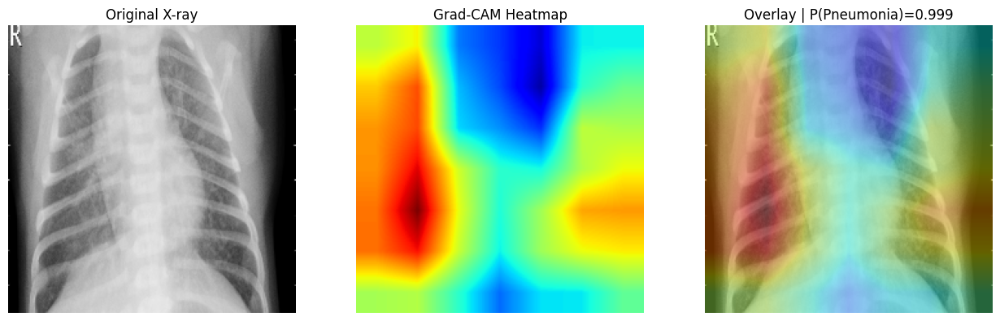


Grad-CAM pilot completed!
Results saved to: /kaggle/working/pneumonia_xai_workspace/experiments/gradcam_pilot


In [6]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# ==========================================
# CONFIGURATION
# ==========================================

MODEL_NAME = "DenseNet121"
FOLD = 1
TARGET_LAYER = "relu"

CAM_DIR = (
    Path("/kaggle/working/pneumonia_xai_workspace")
    / "experiments"
    / "gradcam_pilot"
)

CAM_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# 1. LOAD MODEL
# ==========================================

tf.keras.backend.clear_session()

model = tf.keras.models.load_model(
    CHECKPOINTS[MODEL_NAME][FOLD],
    compile=False
)

print("Model loaded:", MODEL_NAME)
print("Target layer:", TARGET_LAYER)
print("Feature shape:", model.get_layer(TARGET_LAYER).output.shape)

# ==========================================
# 2. SELECT PNEUMONIA IMAGE
# ==========================================

sample = test_df[
    test_df["label_id"] == 1
].iloc[0]

image_path = sample["actual_path"]

def load_xray(path):
    img = tf.io.read_file(str(path))
    img = tf.image.decode_image(
        img, channels=3, expand_animations=False
    )
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (224, 224))
    return tf.cast(img, tf.float32) / 255.0

img = load_xray(image_path)
input_tensor = tf.expand_dims(img, axis=0)

print("Image:", Path(image_path).name)

# ==========================================
# 3. BUILD GRAD-CAM MODEL
# ==========================================

grad_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer(TARGET_LAYER).output,
        model.output
    ]
)

# ==========================================
# 4. CALCULATE GRAD-CAM
# ==========================================

with tf.GradientTape() as tape:
    conv_output, prediction = grad_model(
        input_tensor,
        training=False
    )

    # Explain the pneumonia class (label 1)
    class_score = prediction[:, 0]

grads = tape.gradient(class_score, conv_output)

if grads is None:
    raise RuntimeError("Grad-CAM gradients are unavailable.")

# Global average pooling of gradients
weights = tf.reduce_mean(grads, axis=(1, 2))

# Weighted combination of feature maps
cam = tf.reduce_sum(
    conv_output * weights[:, None, None, :],
    axis=-1
)

cam = tf.nn.relu(cam)

# Resize to original model input resolution
cam = tf.image.resize(
    cam[..., tf.newaxis],
    (224, 224)
)[0, :, :, 0]

# Normalize heatmap
cam = cam.numpy()
cam = cam / (cam.max() + 1e-8)

pneumonia_probability = float(prediction[0, 0].numpy())

print("\nPneumonia probability:",
      round(pneumonia_probability, 4))

print("CAM min:", round(float(cam.min()), 4))
print("CAM max:", round(float(cam.max()), 4))

# ==========================================
# 5. VISUALIZATION
# ==========================================

image_np = img.numpy()

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(image_np)
axes[0].set_title("Original X-ray")

axes[1].imshow(cam, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(image_np)
axes[2].imshow(
    cam,
    cmap="jet",
    alpha=0.4,
    vmin=0,
    vmax=1
)
axes[2].set_title(
    f"Overlay | P(Pneumonia)={pneumonia_probability:.3f}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()

figure_path = CAM_DIR / "DenseNet121_fold1_gradcam.png"

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 6. SAVE EXPERIMENT OUTPUT
# ==========================================

np.save(
    CAM_DIR / "DenseNet121_fold1_gradcam.npy",
    cam
)

pd.DataFrame([{
    "model": MODEL_NAME,
    "fold": FOLD,
    "method": "Grad-CAM",
    "target_layer": TARGET_LAYER,
    "image_path": str(sample["filepath"]),
    "true_label": int(sample["label_id"]),
    "pneumonia_probability": pneumonia_probability,
    "cam_min": float(cam.min()),
    "cam_max": float(cam.max())
}]).to_csv(
    CAM_DIR / "pilot_metadata.csv",
    index=False
)

print("\nGrad-CAM pilot completed!")
print("Results saved to:", CAM_DIR)


Running: Grad-CAM
Completed in 0.79s
Running: Grad-CAM++
Completed in 2.35s
Running: Eigen-CAM
Completed in 0.49s
Running: Score-CAM (Top-32)
Completed in 17.23s


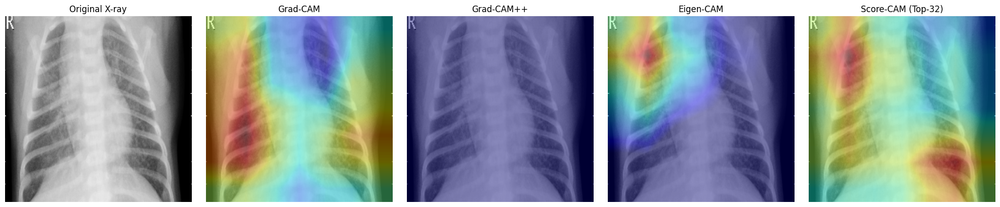


===== CAM RUNTIME RESULTS =====
      model  fold             method  runtime_seconds  heatmap_max  heatmap_std
DenseNet121     1           Grad-CAM         0.790431     0.999936     0.204675
DenseNet121     1         Grad-CAM++         2.348890     0.000000     0.000000
DenseNet121     1          Eigen-CAM         0.491739     1.000000     0.227671
DenseNet121     1 Score-CAM (Top-32)        17.234247     1.000000     0.161022

Saved to: /kaggle/working/pneumonia_xai_workspace/experiments/gradcam_pilot


In [7]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import time

# ==========================================
# 1. SETUP
# ==========================================

x = input_tensor
target_layer = "relu"
EPS = 1e-8

# Score-CAM pilot uses 32 strongest channels
# instead of all 1024, to save GPU time.
SCORECAM_CHANNELS = 32

feature_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer(target_layer).output,
        model.output
    ]
)

def normalize_cam(heatmap):
    heatmap = np.asarray(heatmap, dtype=np.float32)
    heatmap = np.maximum(heatmap, 0)
    heatmap = heatmap / (heatmap.max() + EPS)
    return heatmap

def resize_cam(heatmap):
    heatmap = tf.image.resize(
        heatmap[None, ..., None],
        (224, 224)
    )[0, :, :, 0].numpy()
    return normalize_cam(heatmap)

# ==========================================
# 2. GRAD-CAM
# ==========================================

def generate_gradcam(x):
    with tf.GradientTape() as tape:
        features, predictions = feature_model(
            x, training=False
        )
        score = predictions[:, 0]

    gradients = tape.gradient(score, features)

    weights = tf.reduce_mean(
        gradients, axis=(1, 2), keepdims=True
    )

    heatmap = tf.reduce_sum(
        features * weights, axis=-1
    )

    return resize_cam(
        tf.nn.relu(heatmap[0]).numpy()
    )

# ==========================================
# 3. GRAD-CAM++
# ==========================================

def generate_gradcam_pp(x):
    with tf.GradientTape() as tape:
        features, predictions = feature_model(
            x, training=False
        )
        score = predictions[:, 0]

    gradients = tape.gradient(score, features)

    # Common practical Grad-CAM++ approximation
    # based on powers of first-order gradients.
    g2 = gradients ** 2
    g3 = gradients ** 3

    activation_sum = tf.reduce_sum(
        features, axis=(1, 2), keepdims=True
    )

    denominator = 2 * g2 + activation_sum * g3

    alphas = tf.where(
        tf.abs(denominator) > EPS,
        g2 / (denominator + EPS),
        tf.zeros_like(denominator)
    )

    positive_gradients = tf.nn.relu(gradients)

    weights = tf.reduce_sum(
        alphas * positive_gradients,
        axis=(1, 2),
        keepdims=True
    )

    heatmap = tf.reduce_sum(
        features * weights, axis=-1
    )

    return resize_cam(
        tf.nn.relu(heatmap[0]).numpy()
    )

# ==========================================
# 4. EIGEN-CAM
# ==========================================

def generate_eigencam(x):
    features, _ = feature_model(
        x, training=False
    )

    activations = features[0].numpy()
    h, w, c = activations.shape

    matrix = activations.reshape(-1, c)
    matrix = matrix - matrix.mean(
        axis=0, keepdims=True
    )

    # First principal component
    u, s, vh = np.linalg.svd(
        matrix, full_matrices=False
    )

    heatmap = (
        matrix @ vh[0]
    ).reshape(h, w)

    # PCA direction has arbitrary sign.
    # Fix orientation deterministically.
    if heatmap.sum() < 0:
        heatmap = -heatmap

    return resize_cam(heatmap)

# ==========================================
# 5. SCORE-CAM (TOP-K PILOT)
# ==========================================

def generate_scorecam(x, top_k=32):
    features, predictions = feature_model(
        x, training=False
    )

    activations = features[0].numpy()
    h, w, c = activations.shape

    # Select active spatially varying channels
    variance = np.var(
        activations, axis=(0, 1)
    )

    channel_ids = np.argsort(
        variance
    )[-min(top_k, c):]

    image = x[0].numpy()
    masks = []

    for channel in channel_ids:
        activation = activations[:, :, channel]

        activation = tf.image.resize(
            activation[None, ..., None],
            (224, 224)
        )[0, :, :, 0].numpy()

        activation -= activation.min()
        activation /= activation.max() + EPS

        masks.append(activation)

    masks = np.stack(masks).astype(np.float32)

    masked_images = (
        masks[..., None] * image[None, ...]
    )

    # Forward inference on masked images
    scores = model.predict(
        masked_images,
        batch_size=8,
        verbose=0
    ).reshape(-1)

    # Softmax channel weights
    scores = scores - scores.max()
    weights = np.exp(scores)
    weights /= weights.sum() + EPS

    heatmap = np.zeros((h, w), dtype=np.float32)

    for weight, channel in zip(
        weights, channel_ids
    ):
        heatmap += (
            weight * activations[:, :, channel]
        )

    return resize_cam(heatmap)

# ==========================================
# 6. RUN ALL FOUR METHODS
# ==========================================

methods = {
    "Grad-CAM": generate_gradcam,
    "Grad-CAM++": generate_gradcam_pp,
    "Eigen-CAM": generate_eigencam,
    "Score-CAM (Top-32)": lambda x:
        generate_scorecam(x, SCORECAM_CHANNELS)
}

heatmaps = {}
runtime_rows = []

for method_name, method_fn in methods.items():
    print("Running:", method_name)

    start = time.perf_counter()

    heatmap = method_fn(x)

    duration = time.perf_counter() - start

    if not np.all(np.isfinite(heatmap)):
        raise RuntimeError(
            f"Invalid heatmap: {method_name}"
        )

    heatmaps[method_name] = heatmap

    runtime_rows.append({
        "model": "DenseNet121",
        "fold": 1,
        "method": method_name,
        "runtime_seconds": duration,
        "heatmap_max": float(heatmap.max()),
        "heatmap_std": float(heatmap.std())
    })

    np.save(
        CAM_DIR /
        f"{method_name.replace(' ', '_')}.npy",
        heatmap
    )

    print(f"Completed in {duration:.2f}s")

# ==========================================
# 7. VISUAL COMPARISON
# ==========================================

fig, axes = plt.subplots(
    1, 5, figsize=(20, 4)
)

axes[0].imshow(img.numpy())
axes[0].set_title("Original X-ray")

for ax, (name, heatmap) in zip(
    axes[1:], heatmaps.items()
):
    ax.imshow(img.numpy())
    ax.imshow(
        heatmap, cmap="jet",
        alpha=0.40, vmin=0, vmax=1
    )
    ax.set_title(name)

for ax in axes:
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    CAM_DIR / "four_cam_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

runtime_df = pd.DataFrame(runtime_rows)

runtime_df.to_csv(
    CAM_DIR / "cam_runtime_comparison.csv",
    index=False
)

print("\n===== CAM RUNTIME RESULTS =====")
print(runtime_df.to_string(index=False))

print("\nSaved to:", CAM_DIR)


Gradient min: -0.007455210201442242
Gradient max: 0.006288972217589617
Positive weights: 558
CAM max: 1.0
CAM std: 0.14410829544067383
Runtime: 2.24 seconds


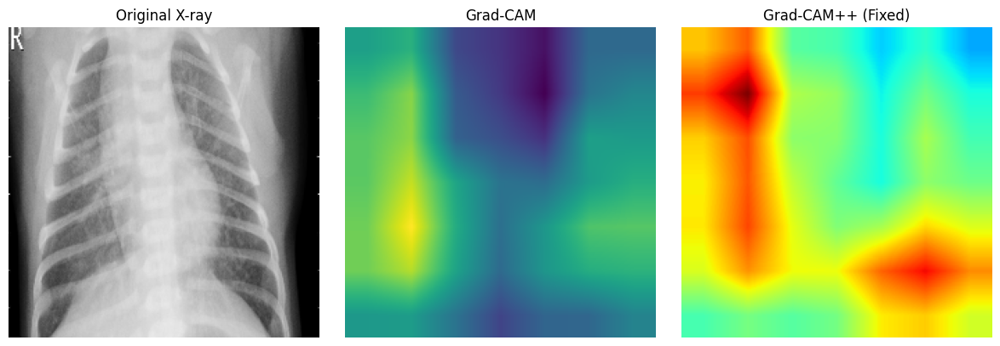

Valid nonzero heatmap saved.


In [8]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import time

EPS = 1e-8

def generate_gradcam_pp_fixed(x):
    with tf.GradientTape() as tape:
        features, predictions = feature_model(
            x, training=False
        )

        probability = predictions[:, 0]

        # Convert sigmoid probability to log-odds.
        # This requires a binary sigmoid output.
        p = tf.clip_by_value(
            probability, 1e-6, 1.0 - 1e-6
        )
        score = tf.math.log(p) - tf.math.log1p(-p)

    gradients = tape.gradient(score, features)

    if gradients is None:
        raise RuntimeError("Gradients unavailable")

    # Practical first-gradient Grad-CAM++ formulation
    g2 = tf.square(gradients)
    g3 = g2 * gradients

    activation_sum = tf.reduce_sum(
        features, axis=(1, 2), keepdims=True
    )

    denominator = 2.0 * g2 + activation_sum * g3

    alphas = tf.math.divide_no_nan(
        g2, denominator
    )

    positive_gradients = tf.nn.relu(gradients)

    weights = tf.reduce_sum(
        alphas * positive_gradients,
        axis=(1, 2),
        keepdims=True
    )

    heatmap = tf.reduce_sum(
        weights * features,
        axis=-1
    )

    heatmap = tf.nn.relu(heatmap)

    heatmap = tf.image.resize(
        heatmap[..., None],
        (224, 224)
    )[0, :, :, 0].numpy()

    maximum = float(heatmap.max())

    if maximum > 0:
        heatmap = heatmap / maximum

    print("Gradient min:", float(tf.reduce_min(gradients)))
    print("Gradient max:", float(tf.reduce_max(gradients)))
    print("Positive weights:", int(
        tf.reduce_sum(tf.cast(weights > 0, tf.int32))
    ))
    print("CAM max:", float(heatmap.max()))
    print("CAM std:", float(heatmap.std()))

    return heatmap

start = time.perf_counter()

cam_pp_fixed = generate_gradcam_pp_fixed(input_tensor)

print("Runtime:", round(time.perf_counter() - start, 2), "seconds")

# Display comparison
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(img.numpy())
axes[0].set_title("Original X-ray")

axes[1].imshow(heatmaps["Grad-CAM"])
axes[1].set_title("Grad-CAM")

axes[2].imshow(cam_pp_fixed, cmap="jet", vmin=0, vmax=1)
axes[2].set_title("Grad-CAM++ (Fixed)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Save only if valid
if cam_pp_fixed.max() > 0 and cam_pp_fixed.std() > 1e-6:
    heatmaps["Grad-CAM++"] = cam_pp_fixed
    np.save(
        CAM_DIR / "Grad-CAM++_fixed.npy",
        cam_pp_fixed
    )
    print("Valid nonzero heatmap saved.")
else:
    print("WARNING: Grad-CAM++ remains degenerate.")


===== CAM SANITY CHECKS =====
            Method      Min      Max      Std  Nonzero_Percentage  Valid
          Grad-CAM 0.034850 0.999936 0.204675          100.000000   True
        Grad-CAM++ 0.290655 1.000000 0.144108          100.000000   True
         Eigen-CAM 0.000000 1.000000 0.227671           46.414621   True
Score-CAM (Top-32) 0.199185 1.000000 0.161022          100.000000   True

All four maps passed basic numerical checks.


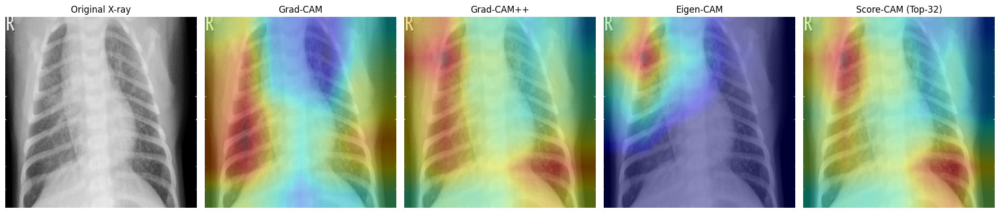


Diagnostics and comparison saved.


In [9]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Use corrected Grad-CAM++ map
heatmaps["Grad-CAM++"] = cam_pp_fixed

method_names = [
    "Grad-CAM",
    "Grad-CAM++",
    "Eigen-CAM",
    "Score-CAM (Top-32)"
]

rows = []

for method in method_names:
    h = np.asarray(heatmaps[method], dtype=np.float32)

    assert h.shape == (224, 224), f"Wrong shape: {method}"
    assert np.all(np.isfinite(h)), f"Invalid values: {method}"

    rows.append({
        "Method": method,
        "Min": float(h.min()),
        "Max": float(h.max()),
        "Std": float(h.std()),
        "Nonzero_Percentage": float(
            np.mean(h > 1e-6) * 100
        ),
        "Valid": bool(h.max() > 0 and h.std() > 1e-6)
    })

diagnostics_df = pd.DataFrame(rows)

print("===== CAM SANITY CHECKS =====")
print(diagnostics_df.to_string(index=False))

if not diagnostics_df["Valid"].all():
    print("\nWARNING: One or more heatmaps failed diagnostics.")
else:
    print("\nAll four maps passed basic numerical checks.")

# Updated comparison
fig, axes = plt.subplots(1, 5, figsize=(19, 4))

axes[0].imshow(img.numpy())
axes[0].set_title("Original X-ray")

for ax, method in zip(axes[1:], method_names):
    ax.imshow(img.numpy())
    ax.imshow(
        heatmaps[method],
        cmap="jet",
        alpha=0.4,
        vmin=0,
        vmax=1
    )
    ax.set_title(method)

for ax in axes:
    ax.axis("off")

plt.tight_layout()

CAM_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    CAM_DIR / "four_cam_corrected_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

diagnostics_df.to_csv(
    CAM_DIR / "cam_sanity_checks.csv",
    index=False
)

print("\nDiagnostics and comparison saved.")



Evaluating: Grad-CAM
Deletion AUC: 0.9979
Insertion AUC: 0.9996
Runtime: 14.30s

Evaluating: Grad-CAM++
Deletion AUC: 0.9985
Insertion AUC: 0.9994
Runtime: 0.46s

Evaluating: Eigen-CAM
Deletion AUC: 0.9985
Insertion AUC: 0.9995
Runtime: 0.46s

Evaluating: Score-CAM (Top-32)
Deletion AUC: 0.9985
Insertion AUC: 0.9990
Runtime: 0.46s


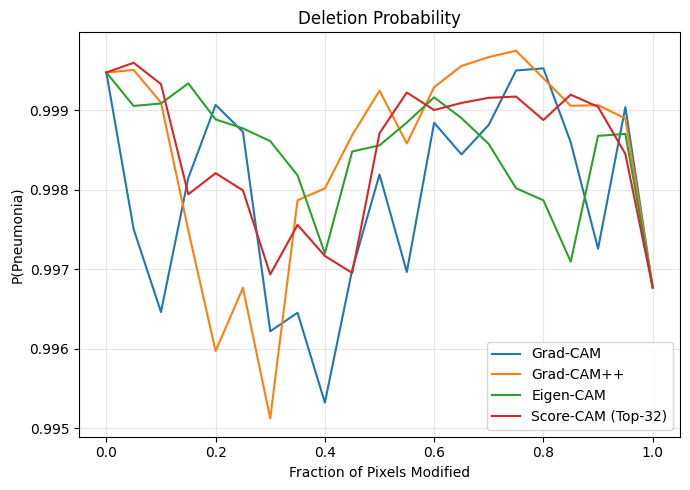

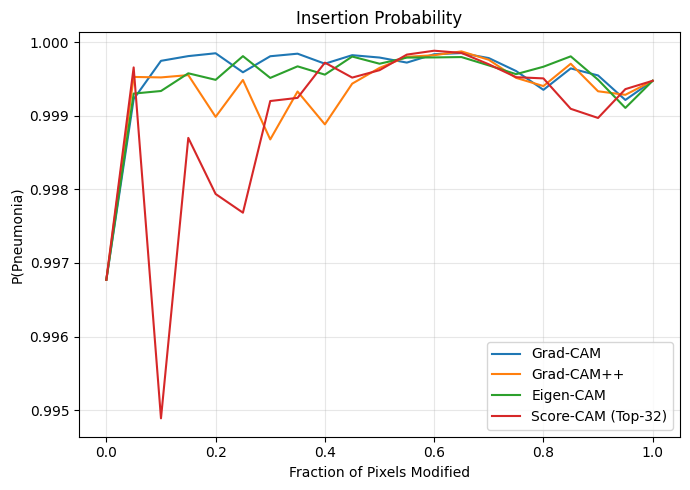


===== FAITHFULNESS RESULTS =====
      Model  Fold             Method  Deletion_AUC  Insertion_AUC  Runtime_seconds
DenseNet121     1           Grad-CAM      0.997910       0.999593        14.299677
DenseNet121     1         Grad-CAM++      0.998458       0.999383         0.463309
DenseNet121     1          Eigen-CAM      0.998506       0.999528         0.463861
DenseNet121     1 Score-CAM (Top-32)      0.998486       0.999000         0.456825

Saved to: /kaggle/working/pneumonia_xai_workspace/experiments/faithfulness_pilot


In [10]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import time

from pathlib import Path

# ==========================================
# 1. CONFIGURATION
# ==========================================

FAITH_DIR = (
    Path("/kaggle/working/pneumonia_xai_workspace")
    / "experiments"
    / "faithfulness_pilot"
)
FAITH_DIR.mkdir(parents=True, exist_ok=True)

N_STEPS = 20
BATCH_SIZE = 8
TARGET_CLASS = 1  # Pneumonia

METHODS = [
    "Grad-CAM",
    "Grad-CAM++",
    "Eigen-CAM",
    "Score-CAM (Top-32)"
]

# ==========================================
# 2. IMAGE AND BLURRED BASELINE
# ==========================================

image = img.numpy().astype(np.float32)

# Blur baseline, not a black image
baseline = tf.nn.avg_pool2d(
    image[None],
    ksize=21,
    strides=1,
    padding="SAME"
)[0].numpy()

H, W, C = image.shape

# Blur and original use identical input scaling
assert image.min() >= 0 and image.max() <= 1
assert baseline.shape == image.shape

# ==========================================
# 3. MODEL SCORING
# ==========================================

def predict_target(images):
    probabilities = model.predict(
        images,
        batch_size=BATCH_SIZE,
        verbose=0
    ).reshape(-1)

    if TARGET_CLASS == 1:
        return probabilities

    return 1.0 - probabilities

# ==========================================
# 4. INSERTION / DELETION
# ==========================================

def faithfulness_curves(heatmap):
    importance = np.asarray(
        heatmap, dtype=np.float32
    )

    # Ranking is based on CAM importance
    importance = tf.image.resize(
        importance[None, ..., None],
        (H, W)
    )[0, :, :, 0].numpy()

    flat_scores = importance.reshape(-1)

    # Descending importance
    ranking = np.argsort(
        -flat_scores, kind="stable"
    )

    total_pixels = H * W

    fractions = np.linspace(
        0, 1, N_STEPS + 1
    )

    deletion_images = []
    insertion_images = []

    for fraction in fractions:

        n = int(round(
            fraction * total_pixels
        ))

        mask = np.zeros(
            total_pixels, dtype=np.float32
        )
        mask[ranking[:n]] = 1.0

        mask = mask.reshape(H, W, 1)

        # Deletion: original -> blurred baseline
        deletion = (
            image * (1 - mask)
            + baseline * mask
        )

        # Insertion: blurred baseline -> original
        insertion = (
            baseline * (1 - mask)
            + image * mask
        )

        deletion_images.append(deletion)
        insertion_images.append(insertion)

    deletion_images = np.stack(
        deletion_images
    ).astype(np.float32)

    insertion_images = np.stack(
        insertion_images
    ).astype(np.float32)

    deletion_scores = predict_target(
        deletion_images
    )

    insertion_scores = predict_target(
        insertion_images
    )

    deletion_auc = float(
        np.trapezoid(
            deletion_scores, fractions
        )
    )

    insertion_auc = float(
        np.trapezoid(
            insertion_scores, fractions
        )
    )

    return (
        fractions,
        deletion_scores,
        insertion_scores,
        deletion_auc,
        insertion_auc
    )

# ==========================================
# 5. EVALUATE FOUR CAM METHODS
# ==========================================

results = []
all_curves = []

for method in METHODS:

    print("\nEvaluating:", method)

    start = time.perf_counter()

    (
        fractions,
        deletion_scores,
        insertion_scores,
        deletion_auc,
        insertion_auc
    ) = faithfulness_curves(
        heatmaps[method]
    )

    elapsed = time.perf_counter() - start

    results.append({
        "Model": "DenseNet121",
        "Fold": 1,
        "Method": method,
        "Deletion_AUC": deletion_auc,
        "Insertion_AUC": insertion_auc,
        "Runtime_seconds": elapsed
    })

    for fraction, d, ins in zip(
        fractions,
        deletion_scores,
        insertion_scores
    ):
        all_curves.append({
            "Method": method,
            "Fraction": fraction,
            "Deletion_Probability": d,
            "Insertion_Probability": ins
        })

    print(
        f"Deletion AUC: {deletion_auc:.4f}"
    )
    print(
        f"Insertion AUC: {insertion_auc:.4f}"
    )
    print(
        f"Runtime: {elapsed:.2f}s"
    )

# ==========================================
# 6. SAVE RESULTS
# ==========================================

results_df = pd.DataFrame(results)
curves_df = pd.DataFrame(all_curves)

results_df.to_csv(
    FAITH_DIR / "faithfulness_results.csv",
    index=False
)

curves_df.to_csv(
    FAITH_DIR / "faithfulness_curves.csv",
    index=False
)

# ==========================================
# 7. PLOT CURVES
# ==========================================

for curve_type in [
    "Deletion_Probability",
    "Insertion_Probability"
]:

    plt.figure(figsize=(7, 5))

    for method in METHODS:
        subset = curves_df[
            curves_df["Method"] == method
        ]

        plt.plot(
            subset["Fraction"],
            subset[curve_type],
            label=method
        )

    plt.xlabel("Fraction of Pixels Modified")
    plt.ylabel("P(Pneumonia)")
    plt.title(
        curve_type.replace("_", " ")
    )
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        FAITH_DIR / f"{curve_type}.png",
        dpi=180
    )

    plt.show()

print("\n===== FAITHFULNESS RESULTS =====")
print(results_df.to_string(index=False))

print("\nSaved to:", FAITH_DIR)


In [11]:

import tensorflow as tf
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter
from pathlib import Path

# Existing DenseNet121 Fold 1 model
# and test_df from previous cells

# Select 40 pneumonia + 40 normal images
sample_df = pd.concat([
    test_df[test_df["label_id"] == 1].sample(
        n=40, random_state=42
    ),
    test_df[test_df["label_id"] == 0].sample(
        n=40, random_state=42
    )
]).reset_index(drop=True)

def load_xray_for_test(path):
    raw = tf.io.read_file(str(path))
    image = tf.image.decode_image(
        raw, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, (224, 224))
    return (tf.cast(image, tf.float32) / 255.0).numpy()

images = np.stack([
    load_xray_for_test(p)
    for p in sample_df["actual_path"]
]).astype(np.float32)

# Predict all samples
probs = model.predict(
    images, batch_size=16, verbose=0
).reshape(-1)

sample_df["pneumonia_probability"] = probs
sample_df["predicted_label"] = (probs >= 0.5).astype(int)
sample_df["confidence_distance"] = np.abs(probs - 0.5)

# Show least-confident correctly classified samples
correct = sample_df[
    sample_df["predicted_label"] == sample_df["label_id"]
].copy()

selected = correct.sort_values(
    "confidence_distance"
).head(10)

print("===== LESS-SATURATED PREDICTIONS =====")
print(
    selected[
        ["filepath", "label_id", "pneumonia_probability"]
    ].to_string(index=False)
)

# Evaluate our existing highly confident pneumonia image
original = img.numpy().astype(np.float32)

blurred = gaussian_filter(
    original,
    sigma=(12, 12, 0)
).astype(np.float32)

mean_baseline = np.full_like(
    original, original.mean()
)

black_baseline = np.zeros_like(original)

probe_images = np.stack([
    original,
    blurred,
    mean_baseline,
    black_baseline
])

probe_probs = model.predict(
    probe_images, batch_size=4, verbose=0
).reshape(-1)

probe_results = pd.DataFrame({
    "Image": [
        "Original",
        "Gaussian Blur (sigma=12)",
        "Mean Intensity",
        "Black"
    ],
    "Pneumonia_Probability": probe_probs
})

print("\n===== MODEL SENSITIVITY TEST =====")
print(probe_results.to_string(index=False))

# Save results
DIAG_DIR = Path(
    "/kaggle/working/pneumonia_xai_workspace"
    "/experiments/faithfulness_diagnostics"
)
DIAG_DIR.mkdir(parents=True, exist_ok=True)

sample_df.to_csv(
    DIAG_DIR / "sample_predictions.csv", index=False
)

probe_results.to_csv(
    DIAG_DIR / "baseline_sensitivity.csv", index=False
)

print("\nDiagnostics saved to:", DIAG_DIR)


===== LESS-SATURATED PREDICTIONS =====
                                        filepath  label_id  pneumonia_probability
       /Dataset/NORMAL/NORMAL2-IM-1270-0001.jpeg         0               0.451682
               /Dataset/NORMAL/IM-0127-0001.jpeg         0               0.425733
       /Dataset/NORMAL/NORMAL2-IM-0340-0001.jpeg         0               0.422247
       /Dataset/NORMAL/NORMAL2-IM-0366-0001.jpeg         0               0.417100
    /Dataset/PNEUMONIA/person547_virus_1086.jpeg         1               0.606658
/Dataset/PNEUMONIA/person1261_bacteria_3219.jpeg         1               0.615264
       /Dataset/NORMAL/NORMAL2-IM-0303-0001.jpeg         0               0.342617
    /Dataset/PNEUMONIA/person739_virus_1361.jpeg         1               0.728332
   /Dataset/PNEUMONIA/person1337_virus_2307.jpeg         1               0.775837
       /Dataset/NORMAL/NORMAL2-IM-1135-0001.jpeg         0               0.222735

===== MODEL SENSITIVITY TEST =====
                   Imag

In [12]:

import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter
from pathlib import Path

# Reuse the previously sampled 80 images and DenseNet121 model
assert len(images) == len(sample_df) == 80

records = []

for i, row in sample_df.iterrows():

    original = images[i].astype(np.float32)

    blurred = gaussian_filter(
        original, sigma=(12, 12, 0)
    ).astype(np.float32)

    mean_image = np.full_like(
        original, original.mean()
    )

    black_image = np.zeros_like(original)

    batch = np.stack([
        original, blurred, mean_image, black_image
    ])

    probabilities = model.predict(
        batch, verbose=0
    ).reshape(-1)

    label = int(row["label_id"])

    # Evaluate confidence in the true class
    true_class_scores = (
        probabilities if label == 1
        else 1.0 - probabilities
    )

    records.append({
        "filepath": row["filepath"],
        "label": label,
        "Original": float(true_class_scores[0]),
        "Blur": float(true_class_scores[1]),
        "Mean": float(true_class_scores[2]),
        "Black": float(true_class_scores[3]),
        "Blur_drop": float(
            true_class_scores[0] - true_class_scores[1]
        ),
        "Mean_drop": float(
            true_class_scores[0] - true_class_scores[2]
        ),
        "Black_drop": float(
            true_class_scores[0] - true_class_scores[3]
        )
    })

baseline_df = pd.DataFrame(records)

print("===== BASELINE SENSITIVITY SUMMARY =====")

summary = baseline_df.groupby("label")[
    ["Original", "Blur", "Mean", "Black",
     "Blur_drop", "Mean_drop", "Black_drop"]
].agg(["mean", "std"])

print(summary.round(4).to_string())

print("\n===== BASELINE DROP SUMMARY =====")

print(
    baseline_df[
        ["Blur_drop", "Mean_drop", "Black_drop"]
    ].describe().round(4).to_string()
)

# Save results
DIAG_DIR = Path(
    "/kaggle/working/pneumonia_xai_workspace"
    "/experiments/faithfulness_diagnostics"
)

DIAG_DIR.mkdir(parents=True, exist_ok=True)

baseline_df.to_csv(
    DIAG_DIR / "multi_image_baseline_test.csv",
    index=False
)

summary.to_csv(
    DIAG_DIR / "multi_image_baseline_summary.csv"
)

print("\nSaved to:", DIAG_DIR)


===== BASELINE SENSITIVITY SUMMARY =====
      Original           Blur            Mean           Black      Blur_drop         Mean_drop         Black_drop        
          mean     std   mean     std    mean     std    mean  std      mean     std      mean     std       mean     std
label                                                                                                                    
0       0.9143  0.1558  0.010  0.0060  0.1130  0.0008  0.1157  0.0    0.9043  0.1571    0.8013  0.1558     0.7986  0.1558
1       0.9154  0.1494  0.975  0.0189  0.8871  0.0017  0.8843  0.0   -0.0597  0.1578    0.0282  0.1490     0.0311  0.1494

===== BASELINE DROP SUMMARY =====
       Blur_drop  Mean_drop  Black_drop
count    80.0000    80.0000     80.0000
mean      0.4223     0.4147      0.4148
std       0.5096     0.4174      0.4149
min      -0.5563    -0.4505     -0.4475
25%       0.0133     0.1059      0.1106
50%       0.2642     0.2248      0.2237
75%       0.9807     0.8752      0


===== PATCH FAITHFULNESS RESULTS =====
            Method  Deletion_AUC  Insertion_AUC  Deletion_vs_Random  Insertion_vs_Random
          Grad-CAM        5.9235         7.2651              0.9056               0.5143
        Grad-CAM++        6.4153         6.9282              0.4138               0.1774
         Eigen-CAM        5.6445         6.9760              1.1846               0.2252
Score-CAM (Top-32)        6.2186         6.7805              0.6106               0.0297

Random deletion AUC: 6.8291
Random insertion AUC: 6.7508


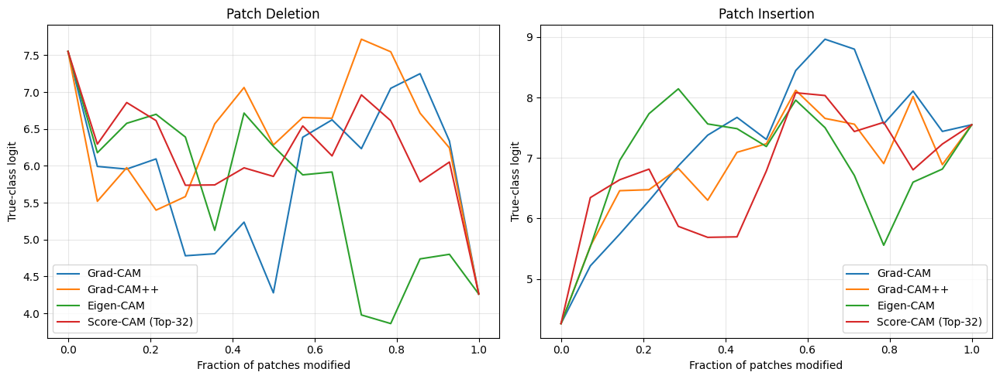


Results saved: /kaggle/working/pneumonia_xai_workspace/experiments/faithfulness_patch_pilot


In [13]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from pathlib import Path

# ==========================================
# CONFIGURATION
# ==========================================

PATCH = 16
SEED = 42
EPS = 1e-6

FAITH_DIR = Path(
    "/kaggle/working/pneumonia_xai_workspace"
    "/experiments/faithfulness_patch_pilot"
)
FAITH_DIR.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(SEED)

image = img.numpy().astype(np.float32)
baseline = gaussian_filter(
    image, sigma=(12, 12, 0)
).astype(np.float32)

H, W, C = image.shape

assert H % PATCH == 0 and W % PATCH == 0

GRID_H = H // PATCH
GRID_W = W // PATCH
N_PATCHES = GRID_H * GRID_W

# ==========================================
# PATCH RANKING
# ==========================================

def get_patch_order(heatmap):
    h = np.asarray(heatmap, dtype=np.float32)

    patch_scores = h.reshape(
        GRID_H, PATCH, GRID_W, PATCH
    ).mean(axis=(1, 3))

    return np.argsort(
        -patch_scores.reshape(-1),
        kind="stable"
    )

def build_masks(order):
    masks = []

    # 0%, 1/14, ..., 100%
    for k in range(N_PATCHES + 1):
        patch_mask = np.zeros(
            N_PATCHES, dtype=np.float32
        )
        patch_mask[order[:k]] = 1.0

        patch_mask = patch_mask.reshape(
            GRID_H, GRID_W
        )

        mask = np.repeat(
            np.repeat(
                patch_mask, PATCH, axis=0
            ),
            PATCH, axis=1
        )

        masks.append(mask[..., None])

    return masks

# ==========================================
# MODEL SCORE
# ==========================================

def predict_logits(images, true_label=1):
    predictions = model.predict(
        images, batch_size=16, verbose=0
    ).reshape(-1)

    p = np.clip(predictions, EPS, 1 - EPS)

    logits = np.log(p / (1 - p))

    return logits if true_label == 1 else -logits

# ==========================================
# INSERTION / DELETION CURVES
# ==========================================

def evaluate_order(order, true_label=1):
    # 15 measurement points: 0,14,28,...,196 patches
    steps = np.linspace(
        0, N_PATCHES, 15
    ).astype(int)

    deletion_images = []
    insertion_images = []

    for n in steps:
        patch_mask = np.zeros(
            N_PATCHES, dtype=np.float32
        )
        patch_mask[order[:n]] = 1.0

        patch_mask = patch_mask.reshape(
            GRID_H, GRID_W
        )

        mask = np.repeat(
            np.repeat(
                patch_mask, PATCH, axis=0
            ),
            PATCH, axis=1
        )[..., None]

        deletion_images.append(
            image * (1 - mask) + baseline * mask
        )

        insertion_images.append(
            baseline * (1 - mask) + image * mask
        )

    deletion_scores = predict_logits(
        np.stack(deletion_images),
        true_label
    )

    insertion_scores = predict_logits(
        np.stack(insertion_images),
        true_label
    )

    fractions = steps / N_PATCHES

    return {
        "fractions": fractions,
        "deletion": deletion_scores,
        "insertion": insertion_scores,
        "deletion_auc": float(
            np.trapezoid(deletion_scores, fractions)
        ),
        "insertion_auc": float(
            np.trapezoid(insertion_scores, fractions)
        )
    }

# ==========================================
# RUN ALL METHODS
# ==========================================

methods = [
    "Grad-CAM",
    "Grad-CAM++",
    "Eigen-CAM",
    "Score-CAM (Top-32)"
]

results = []
curves = []

random_orders = [
    rng.permutation(N_PATCHES)
    for _ in range(5)
]

random_evals = [
    evaluate_order(order)
    for order in random_orders
]

random_deletion = np.mean([
    r["deletion_auc"] for r in random_evals
])

random_insertion = np.mean([
    r["insertion_auc"] for r in random_evals
])

for method in methods:
    order = get_patch_order(heatmaps[method])
    result = evaluate_order(order)

    results.append({
        "Method": method,
        "Deletion_AUC": result["deletion_auc"],
        "Insertion_AUC": result["insertion_auc"],
        "Deletion_vs_Random": (
            random_deletion - result["deletion_auc"]
        ),
        "Insertion_vs_Random": (
            result["insertion_auc"] - random_insertion
        )
    })

    for fraction, deletion, insertion in zip(
        result["fractions"],
        result["deletion"],
        result["insertion"]
    ):
        curves.append({
            "Method": method,
            "Fraction": fraction,
            "Deletion_Logit": deletion,
            "Insertion_Logit": insertion
        })

results_df = pd.DataFrame(results)
curves_df = pd.DataFrame(curves)

results_df.to_csv(
    FAITH_DIR / "patch_faithfulness.csv",
    index=False
)

curves_df.to_csv(
    FAITH_DIR / "patch_curves.csv",
    index=False
)

print("\n===== PATCH FAITHFULNESS RESULTS =====")
print(results_df.round(4).to_string(index=False))

print("\nRandom deletion AUC:", round(random_deletion, 4))
print("Random insertion AUC:", round(random_insertion, 4))

# ==========================================
# VISUALIZE
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for method in methods:
    subset = curves_df[curves_df["Method"] == method]

    axes[0].plot(
        subset["Fraction"],
        subset["Deletion_Logit"],
        label=method
    )
    axes[1].plot(
        subset["Fraction"],
        subset["Insertion_Logit"],
        label=method
    )

axes[0].set_title("Patch Deletion")
axes[1].set_title("Patch Insertion")

for ax in axes:
    ax.set_xlabel("Fraction of patches modified")
    ax.set_ylabel("True-class logit")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig(
    FAITH_DIR / "patch_faithfulness_curves.png",
    dpi=180
)
plt.show()

print("\nResults saved:", FAITH_DIR)


In [14]:

import numpy as np
import pandas as pd
import tensorflow as tf
import time
import io
import contextlib

from pathlib import Path
from scipy.stats import spearmanr
from skimage.metrics import structural_similarity as ssim

# =====================================
# 1. CONFIGURATION
# =====================================

STABILITY_DIR = (
    Path("/kaggle/working/pneumonia_xai_workspace")
    / "experiments" / "stability_pilot"
)
STABILITY_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
NOISE_LEVELS = [0.01, 0.05]
SAMPLES_PER_CLASS = 5

methods = {
    "Grad-CAM": generate_gradcam,
    "Grad-CAM++": generate_gradcam_pp_fixed,
    "Eigen-CAM": generate_eigencam,
    "Score-CAM (Top-32)": lambda x:
        generate_scorecam(x, top_k=32)
}

# Fixed balanced sample
selected_df = pd.concat([
    test_df[test_df["label_id"] == label].sample(
        n=SAMPLES_PER_CLASS,
        random_state=SEED
    )
    for label in [0, 1]
]).reset_index(drop=True)

selected_df[
    ["filepath", "label_id"]
].to_csv(
    STABILITY_DIR / "sample_manifest.csv",
    index=False
)

def calculate_cam(method_fn, image_tensor):
    # Suppress diagnostic printing from Grad-CAM++
    with contextlib.redirect_stdout(io.StringIO()):
        cam_result = method_fn(image_tensor)

    arr = np.asarray(cam_result, dtype=np.float32)

    if arr.shape != (224, 224):
        raise ValueError(f"Unexpected CAM shape: {arr.shape}")
    if not np.isfinite(arr).all():
        raise ValueError("Non-finite heatmap")

    return arr

# =====================================
# 2. RUN EXPERIMENT
# =====================================

records = []
rng = np.random.default_rng(SEED)

start_time = time.perf_counter()

for idx, row in selected_df.iterrows():

    original = load_xray(
        row["actual_path"]
    ).numpy().astype(np.float32)

    # Use identical noise for all CAM methods
    noisy_images = {}

    for sigma in NOISE_LEVELS:
        noise = rng.normal(
            0, sigma, original.shape
        ).astype(np.float32)

        noisy_images[sigma] = np.clip(
            original + noise, 0, 1
        )

    print(
        f"\nImage {idx+1}/{len(selected_df)}:"
        f" {Path(row['filepath']).name}"
    )

    for method_name, method_fn in methods.items():

        t0 = time.perf_counter()

        original_tensor = tf.convert_to_tensor(
            original[None], dtype=tf.float32
        )

        original_cam = calculate_cam(
            method_fn, original_tensor
        )

        for sigma in NOISE_LEVELS:

            noisy_tensor = tf.convert_to_tensor(
                noisy_images[sigma][None],
                dtype=tf.float32
            )

            noisy_cam = calculate_cam(
                method_fn, noisy_tensor
            )

            # SSIM on normalized CAM values
            ssim_value = ssim(
                original_cam,
                noisy_cam,
                data_range=1.0
            )

            # Avoid undefined correlation
            if (
                original_cam.std() < 1e-8
                or noisy_cam.std() < 1e-8
            ):
                spearman_value = np.nan
            else:
                spearman_value = spearmanr(
                    original_cam.ravel(),
                    noisy_cam.ravel()
                ).statistic

            records.append({
                "model": "DenseNet121",
                "fold": 1,
                "filepath": row["filepath"],
                "label": int(row["label_id"]),
                "method": method_name,
                "noise_sigma": sigma,
                "ssim": float(ssim_value),
                "spearman": float(spearman_value),
                "runtime_seconds": (
                    time.perf_counter() - t0
                )
            })

        print(
            method_name,
            "completed",
            f"({time.perf_counter()-t0:.1f}s)"
        )

    # Save after every image
    pd.DataFrame(records).to_csv(
        STABILITY_DIR / "stability_per_image.csv",
        index=False
    )

# =====================================
# 3. SUMMARY
# =====================================

results_df = pd.DataFrame(records)

summary_df = results_df.groupby(
    ["method", "noise_sigma"]
)[["ssim", "spearman"]].agg(
    ["mean", "std", "count"]
)

summary_df.to_csv(
    STABILITY_DIR / "stability_summary.csv"
)

print("\n===== STABILITY SUMMARY =====")
print(summary_df.round(4).to_string())

print(
    "\nTotal runtime:",
    round(time.perf_counter() - start_time, 2),
    "seconds"
)

print("Saved to:", STABILITY_DIR)



Image 1/10: NORMAL2-IM-0536-0001.jpeg
Grad-CAM completed (2.4s)
Grad-CAM++ completed (2.6s)
Eigen-CAM completed (1.6s)
Score-CAM (Top-32) completed (2.6s)

Image 2/10: IM-0299-0001.jpeg
Grad-CAM completed (2.4s)
Grad-CAM++ completed (2.6s)
Eigen-CAM completed (1.5s)
Score-CAM (Top-32) completed (2.5s)

Image 3/10: IM-0620-0001-0001.jpeg
Grad-CAM completed (2.4s)
Grad-CAM++ completed (2.5s)
Eigen-CAM completed (1.5s)
Score-CAM (Top-32) completed (2.5s)

Image 4/10: IM-0127-0001.jpeg
Grad-CAM completed (2.4s)
Grad-CAM++ completed (2.5s)
Eigen-CAM completed (1.6s)
Score-CAM (Top-32) completed (2.5s)

Image 5/10: IM-0553-0001-0003.jpeg
Grad-CAM completed (2.4s)
Grad-CAM++ completed (2.6s)
Eigen-CAM completed (1.6s)
Score-CAM (Top-32) completed (2.5s)

Image 6/10: person670_virus_1256.jpeg
Grad-CAM completed (2.4s)
Grad-CAM++ completed (2.4s)
Eigen-CAM completed (1.5s)
Score-CAM (Top-32) completed (2.6s)

Image 7/10: person525_virus_1046.jpeg
Grad-CAM completed (2.5s)
Grad-CAM++ completed 

In [16]:

import tensorflow as tf

# Current model is MobileNetV2 Fold 1
TARGET_LAYER = "out_relu"

# Rebuild feature model with a single output tensor
feature_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer(TARGET_LAYER).output,
        model.outputs[0]
    ]
)

# Verify
test_input = tf.zeros((1, 224, 224, 3), dtype=tf.float32)

features, predictions = feature_model(
    test_input, training=False
)

print("Features:", features.shape)
print("Predictions:", predictions.shape)
print("Predictions type:", type(predictions))

assert len(predictions.shape) == 2
assert predictions.shape[-1] == 1

print("\nSUCCESS: Feature model fixed!")


Features: (1, 7, 7, 1280)
Predictions: (1, 1)
Predictions type: <class 'tensorflow.python.framework.ops.EagerTensor'>

SUCCESS: Feature model fixed!


In [17]:

import tensorflow as tf
import numpy as np
import pandas as pd
import time
import gc
import io
import contextlib

from pathlib import Path
from scipy.stats import spearmanr
from skimage.metrics import structural_similarity as ssim

ROOT = Path("/kaggle/working/pneumonia_xai_workspace")
STABILITY_DIR = ROOT / "experiments" / "stability_pilot"

SEED = 42
NOISE_LEVELS = [0.01, 0.05]

# Reuse exactly the same image sample
sample_df = pd.read_csv(
    STABILITY_DIR / "sample_manifest.csv"
)
sample_df["actual_path"] = sample_df[
    "filepath"
].apply(resolve_image)

# Existing CAM functions from previous cells
methods = {
    "Grad-CAM": generate_gradcam,
    "Grad-CAM++": generate_gradcam_pp_fixed,
    "Eigen-CAM": generate_eigencam,
    "Score-CAM (Top-32)": lambda x:
        generate_scorecam(x, top_k=32)
}

def run_cam(fn, tensor):
    with contextlib.redirect_stdout(io.StringIO()):
        result = fn(tensor)

    result = np.asarray(result, dtype=np.float32)

    if result.shape != (224, 224):
        raise ValueError("Invalid heatmap shape")

    if not np.isfinite(result).all():
        raise ValueError("Non-finite heatmap")

    return result

def pick_feature_layer(loaded_model):
    # Final spatial feature layer before classification
    candidates = []

    for layer in loaded_model.layers:
        shape = getattr(layer.output, "shape", None)

        if shape is not None and len(shape) == 4:
            candidates.append(layer.name)

    if not candidates:
        raise ValueError("No spatial feature layer found")

    return candidates[-1]

for model_name in ["MobileNetV2", "VGG16"]:

    print(f"\n{'='*50}")
    print("MODEL:", model_name)
    print(f"{'='*50}")

    tf.keras.backend.clear_session()

    model = tf.keras.models.load_model(
        CHECKPOINTS[model_name][1],
        compile=False
    )

    TARGET_LAYER = pick_feature_layer(model)

    feature_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(TARGET_LAYER).output,
            model.outputs[0]
        ]
    )

    print("CAM target layer:", TARGET_LAYER)
    print(
        "Feature shape:",
        model.get_layer(TARGET_LAYER).output.shape
    )

    output_file = (
        STABILITY_DIR /
        f"{model_name}_stability.csv"
    )

    if output_file.exists():
        records = pd.read_csv(output_file).to_dict("records")
    else:
        records = []

    completed = {
        (r["filepath"], r["method"], float(r["noise_sigma"]))
        for r in records
    }

    rng = np.random.default_rng(SEED)
    start = time.perf_counter()

    for idx, row in sample_df.iterrows():

        original = load_xray(
            row["actual_path"]
        ).numpy().astype(np.float32)

        noisy_images = {}

        for sigma in NOISE_LEVELS:
            noise = rng.normal(
                0, sigma, original.shape
            ).astype(np.float32)

            noisy_images[sigma] = np.clip(
                original + noise, 0, 1
            )

        x_original = tf.convert_to_tensor(
            original[None], dtype=tf.float32
        )

        for method_name, fn in methods.items():

            if all(
                (row["filepath"], method_name, float(sigma))
                in completed
                for sigma in NOISE_LEVELS
            ):
                continue

            original_cam = run_cam(fn, x_original)

            for sigma in NOISE_LEVELS:

                key = (
                    row["filepath"], method_name, float(sigma)
                )

                if key in completed:
                    continue

                x_noisy = tf.convert_to_tensor(
                    noisy_images[sigma][None],
                    dtype=tf.float32
                )

                noisy_cam = run_cam(fn, x_noisy)

                ssim_value = ssim(
                    original_cam, noisy_cam,
                    data_range=1.0
                )

                if (
                    original_cam.std() < 1e-8
                    or noisy_cam.std() < 1e-8
                ):
                    rho = np.nan
                else:
                    rho = spearmanr(
                        original_cam.ravel(),
                        noisy_cam.ravel()
                    ).statistic

                records.append({
                    "model": model_name,
                    "fold": 1,
                    "filepath": row["filepath"],
                    "label": int(row["label_id"]),
                    "method": method_name,
                    "noise_sigma": sigma,
                    "ssim": float(ssim_value),
                    "spearman": float(rho)
                })

                completed.add(key)

            # Save after every method
            pd.DataFrame(records).to_csv(
                output_file, index=False
            )

        print(f"Image {idx+1}/{len(sample_df)} completed")

    results = pd.DataFrame(records)

    summary = results.groupby(
        ["method", "noise_sigma"]
    )[["ssim", "spearman"]].agg(
        ["mean", "std", "count"]
    )

    summary.to_csv(
        STABILITY_DIR /
        f"{model_name}_stability_summary.csv"
    )

    print(f"\n{model_name} STABILITY SUMMARY")
    print(summary.round(4).to_string())

    print(
        "\nRuntime:",
        round(time.perf_counter() - start, 2),
        "seconds"
    )

    del model, feature_model
    gc.collect()

print("\nBOTH MODELS COMPLETED.")



MODEL: MobileNetV2
CAM target layer: out_relu
Feature shape: (None, 7, 7, 1280)
Image 1/10 completed
Image 2/10 completed
Image 3/10 completed
Image 4/10 completed
Image 5/10 completed
Image 6/10 completed
Image 7/10 completed
Image 8/10 completed
Image 9/10 completed
Image 10/10 completed

MobileNetV2 STABILITY SUMMARY
                                  ssim               spearman              
                                  mean     std count     mean     std count
method             noise_sigma                                             
Eigen-CAM          0.01         0.3328  0.4430    10  -0.1894  0.8724    10
                   0.05         0.4269  0.3489    10   0.1459  0.7005    10
Grad-CAM           0.01         0.9262  0.0599    10   0.9535  0.0599    10
                   0.05         0.6485  0.1441    10   0.6047  0.2880    10
Grad-CAM++         0.01         0.9870  0.0055    10   0.9866  0.0073    10
                   0.05         0.8541  0.0343    10   0.7946  0.0974

In [18]:

import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from scipy.stats import spearmanr
from skimage.metrics import structural_similarity as ssim
import gc

STABILITY_DIR = Path(
    "/kaggle/working/pneumonia_xai_workspace/"
    "experiments/stability_pilot"
)

samples = pd.read_csv(STABILITY_DIR / "sample_manifest.csv")
samples["actual_path"] = samples["filepath"].apply(resolve_image)

def eigen_cam_corrected(feature_model, x):
    features, _ = feature_model(x, training=False)
    a = features[0].numpy().astype(np.float32)

    h, w, c = a.shape
    matrix = a.reshape(-1, c)

    # Uncentered first principal direction
    u, s, vh = np.linalg.svd(
        matrix, full_matrices=False
    )

    projection = matrix @ vh[0]

    # Make the principal direction deterministic
    if projection.mean() < 0:
        projection = -projection

    heatmap = projection.reshape(h, w)
    heatmap = np.maximum(heatmap, 0)

    heatmap = tf.image.resize(
        heatmap[None, ..., None],
        (224, 224)
    )[0, :, :, 0].numpy()

    heatmap -= heatmap.min()
    maximum = heatmap.max()

    if maximum > 1e-8:
        heatmap /= maximum

    return heatmap.astype(np.float32)

all_records = []

for model_name in ["DenseNet121", "MobileNetV2", "VGG16"]:
    print("\nEvaluating corrected Eigen-CAM:", model_name)

    tf.keras.backend.clear_session()

    model = tf.keras.models.load_model(
        CHECKPOINTS[model_name][1],
        compile=False
    )

    spatial_layers = [
        layer for layer in model.layers
        if len(getattr(layer.output, "shape", ())) == 4
    ]

    target_layer = spatial_layers[-1].name

    feature_model = tf.keras.Model(
        model.inputs,
        [
            model.get_layer(target_layer).output,
            model.outputs[0]
        ]
    )

    rng = np.random.default_rng(42)

    for _, row in samples.iterrows():
        original = load_xray(
            row["actual_path"]
        ).numpy().astype(np.float32)

        original_cam = eigen_cam_corrected(
            feature_model,
            tf.convert_to_tensor(original[None])
        )

        for sigma in [0.01, 0.05]:
            noise = rng.normal(
                0, sigma, original.shape
            ).astype(np.float32)

            noisy = np.clip(original + noise, 0, 1)

            noisy_cam = eigen_cam_corrected(
                feature_model,
                tf.convert_to_tensor(noisy[None])
            )

            similarity = ssim(
                original_cam, noisy_cam, data_range=1.0
            )

            if (
                original_cam.std() < 1e-8
                or noisy_cam.std() < 1e-8
            ):
                rho = np.nan
            else:
                rho = spearmanr(
                    original_cam.ravel(),
                    noisy_cam.ravel()
                ).statistic

            all_records.append({
                "model": model_name,
                "fold": 1,
                "filepath": row["filepath"],
                "label": int(row["label_id"]),
                "method": "Eigen-CAM corrected",
                "noise_sigma": sigma,
                "ssim": float(similarity),
                "spearman": float(rho)
            })

    print(model_name, "completed")

    del model, feature_model
    gc.collect()

corrected_df = pd.DataFrame(all_records)

corrected_df.to_csv(
    STABILITY_DIR / "eigencam_corrected_stability.csv",
    index=False
)

summary = corrected_df.groupby(
    ["model", "noise_sigma"]
)[["ssim", "spearman"]].agg(
    ["mean", "std", "count"]
)

print("\n===== CORRECTED EIGEN-CAM SUMMARY =====")
print(summary.round(4).to_string())

print("\nSaved successfully.")



Evaluating corrected Eigen-CAM: DenseNet121
DenseNet121 completed

Evaluating corrected Eigen-CAM: MobileNetV2
MobileNetV2 completed

Evaluating corrected Eigen-CAM: VGG16
VGG16 completed

===== CORRECTED EIGEN-CAM SUMMARY =====
                           ssim               spearman              
                           mean     std count     mean     std count
model       noise_sigma                                             
DenseNet121 0.01         0.9846  0.0138    10   0.9815  0.0098    10
            0.05         0.8961  0.0576    10   0.7948  0.1819    10
MobileNetV2 0.01         0.9899  0.0039    10   0.9915  0.0042    10
            0.05         0.8595  0.0463    10   0.8132  0.1114    10
VGG16       0.01         0.9977  0.0020    10   0.9969  0.0025    10
            0.05         0.9142  0.0471    10   0.8525  0.0750    10

Saved successfully.


In [19]:

import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from scipy.ndimage import gaussian_filter
import time, gc

OUT = Path("/kaggle/working/pneumonia_xai_workspace/experiments/multi_image_faithfulness")
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42
PATCH = 16
N_STEPS = 10
TOP_K = 32
EPS = 1e-7

MODELS = ["DenseNet121", "MobileNetV2", "VGG16"]
METHODS = ["Grad-CAM", "Grad-CAM++", "Eigen-CAM", "Score-CAM Top-32"]

# Use the existing fixed stability sample
manifest = pd.read_csv(
    "/kaggle/working/pneumonia_xai_workspace/experiments/stability_pilot/sample_manifest.csv"
)

# 3 normal + 3 pneumonia
sample_df = pd.concat([
    manifest[manifest.label_id == c].head(3)
    for c in [0, 1]
]).reset_index(drop=True)

sample_df["actual_path"] = sample_df.filepath.apply(resolve_image)
sample_df[["filepath", "label_id"]].to_csv(
    OUT / "sample_manifest.csv", index=False
)

def load_image(path):
    raw = tf.io.read_file(str(path))
    x = tf.image.decode_image(raw, channels=3, expand_animations=False)
    x.set_shape([None, None, 3])
    x = tf.image.resize(x, (224, 224))
    return (tf.cast(x, tf.float32) / 255.).numpy()

def normalize(a):
    a = np.asarray(a, np.float32)
    a = np.maximum(a, 0)
    maximum = float(a.max())
    return a / maximum if maximum > EPS else np.zeros_like(a)

def upsample(a):
    a = tf.image.resize(
        np.asarray(a, np.float32)[None, ..., None],
        (224, 224)
    )[0, :, :, 0].numpy()
    return normalize(a)

def class_logit(p, label):
    p = np.clip(np.asarray(p), 1e-6, 1-1e-6)
    z = np.log(p) - np.log1p(-p)
    return z if label == 1 else -z

def get_maps(net, feature_net, x, label):
    xt = tf.convert_to_tensor(x[None], tf.float32)

    with tf.GradientTape() as tape:
        feats, probs = feature_net(xt, training=False)
        p = tf.clip_by_value(probs[:, 0], 1e-6, 1-1e-6)
        z = tf.math.log(p) - tf.math.log1p(-p)
        score = z if label == 1 else -z

    grads = tape.gradient(score, feats)
    if grads is None:
        raise RuntimeError("Missing gradients")

    f = feats[0]
    g = grads[0]

    # Grad-CAM
    weights = tf.reduce_mean(g, axis=(0, 1))
    grad_cam = upsample(
        tf.nn.relu(tf.reduce_sum(f * weights, axis=-1)).numpy()
    )

    # Grad-CAM++: first-gradient approximation
    g2 = tf.square(g)
    g3 = g2 * g
    sums = tf.reduce_sum(f, axis=(0, 1))
    alpha = tf.math.divide_no_nan(
        g2, 2*g2 + sums[None, None, :]*g3
    )
    weights_pp = tf.reduce_sum(
        alpha * tf.nn.relu(g), axis=(0, 1)
    )
    grad_pp = upsample(
        tf.nn.relu(tf.reduce_sum(f * weights_pp, axis=-1)).numpy()
    )

    # Corrected uncentered Eigen-CAM
    activations = f.numpy().astype(np.float32)
    h, w, channels = activations.shape
    matrix = activations.reshape(-1, channels)
    _, _, vh = np.linalg.svd(matrix, full_matrices=False)
    projection = matrix @ vh[0]
    if projection.mean() < 0:
        projection = -projection
    eigen = upsample(projection.reshape(h, w))

    # Restricted Score-CAM using highest-variance channels
    ids = np.argsort(np.var(activations, axis=(0, 1)))[-TOP_K:]
    masks = []
    valid_ids = []

    for channel in ids:
        a = tf.image.resize(
            activations[:, :, channel][None, ..., None],
            (224, 224)
        )[0, :, :, 0].numpy()

        a = a - a.min()
        maximum = float(a.max())
        if maximum <= EPS:
            continue

        masks.append(a / maximum)
        valid_ids.append(channel)

    if masks:
        masked = np.stack(masks)[..., None] * x[None]
        probabilities = net.predict(
            masked, batch_size=8, verbose=0
        ).reshape(-1)
        scores = probabilities if label == 1 else 1-probabilities

        weights_sc = np.exp(scores - scores.max())
        weights_sc /= weights_sc.sum()

        score_map = np.zeros((h, w), np.float32)
        for weight, channel in zip(weights_sc, valid_ids):
            score_map += weight * activations[:, :, channel]

        score_cam = upsample(score_map)
    else:
        score_cam = np.zeros((224, 224), np.float32)

    return {
        "Grad-CAM": grad_cam,
        "Grad-CAM++": grad_pp,
        "Eigen-CAM": eigen,
        "Score-CAM Top-32": score_cam
    }

def predict_scores(net, batch, label):
    predictions = net.predict(
        batch, batch_size=8, verbose=0
    ).reshape(-1)
    return class_logit(predictions, label)

def patch_order(cam):
    scores = cam.reshape(14, 16, 14, 16).mean(axis=(1, 3))
    return np.argsort(-scores.ravel(), kind="stable")

def evaluate_order(net, x, baseline, order, label):
    fractions = np.linspace(0, 1, N_STEPS+1)
    deletion, insertion = [], []

    for fraction in fractions:
        n = round(fraction * 196)
        mask = np.zeros(196, dtype=np.float32)
        mask[order[:n]] = 1

        mask = mask.reshape(14, 14)
        mask = np.repeat(np.repeat(mask, 16, axis=0), 16, axis=1)
        mask = mask[..., None]

        deletion.append(x*(1-mask) + baseline*mask)
        insertion.append(baseline*(1-mask) + x*mask)

    combined = np.concatenate([deletion, insertion]).astype(np.float32)
    scores = predict_scores(net, combined, label)

    d = float(np.trapezoid(scores[:N_STEPS+1], fractions))
    i = float(np.trapezoid(scores[N_STEPS+1:], fractions))
    return d, i

results_file = OUT / "multi_image_faithfulness.csv"
records = pd.read_csv(results_file).to_dict("records") if results_file.exists() else []
completed = {(r["model"], r["filepath"], r["method"]) for r in records}

for model_name in MODELS:
    print("\n" + "="*48)
    print("MODEL:", model_name)
    print("="*48)

    tf.keras.backend.clear_session()
    net = tf.keras.models.load_model(
        CHECKPOINTS[model_name][1], compile=False
    )

    spatial = [
        layer for layer in net.layers
        if len(getattr(layer.output, "shape", ())) == 4
    ]
    target = spatial[-1].name

    feature_net = tf.keras.Model(
        net.inputs,
        [net.get_layer(target).output, net.outputs[0]]
    )

    print("Target layer:", target)

    for idx, row in sample_df.iterrows():
        if all((model_name, row.filepath, m) in completed for m in METHODS):
            continue

        x = load_image(row.actual_path)
        baseline = gaussian_filter(
            x, sigma=(12, 12, 0)
        ).astype(np.float32)
        label = int(row.label_id)

        cams = get_maps(net, feature_net, x, label)

        # Same random orders for all CAM methods on this image
        rng = np.random.default_rng(SEED + idx)
        random_metrics = [
            evaluate_order(net, x, baseline, rng.permutation(196), label)
            for _ in range(2)
        ]
        random_d = np.mean([r[0] for r in random_metrics])
        random_i = np.mean([r[1] for r in random_metrics])

        for method in METHODS:
            key = (model_name, row.filepath, method)
            if key in completed:
                continue

            cam = cams[method]
            if not np.isfinite(cam).all() or cam.std() < 1e-7:
                print("WARNING: Degenerate CAM:", model_name, method)
                continue

            t0 = time.perf_counter()
            d, ins = evaluate_order(
                net, x, baseline, patch_order(cam), label
            )

            records.append({
                "model": model_name,
                "fold": 1,
                "filepath": row.filepath,
                "label": label,
                "method": method,
                "deletion_auc": d,
                "insertion_auc": ins,
                "deletion_vs_random": random_d-d,
                "insertion_vs_random": ins-random_i,
                "runtime_seconds": time.perf_counter()-t0
            })

            completed.add(key)

            # Save after every completed method
            pd.DataFrame(records).to_csv(results_file, index=False)

        print(f"Image {idx+1}/{len(sample_df)} completed")

    del net, feature_net
    gc.collect()

results = pd.DataFrame(records)

summary = results.groupby(
    ["model", "method"]
)[["deletion_vs_random", "insertion_vs_random"]].agg(
    ["mean", "std", "count"]
)

summary.to_csv(OUT / "multi_image_summary.csv")

print("\n===== MULTI-IMAGE FAITHFULNESS SUMMARY =====")
print(summary.round(4).to_string())
print("\nSaved to:", OUT)



MODEL: DenseNet121
Target layer: relu
Image 1/6 completed
Image 2/6 completed
Image 3/6 completed
Image 4/6 completed
Image 5/6 completed
Image 6/6 completed

MODEL: MobileNetV2
Target layer: out_relu
Image 1/6 completed
Image 2/6 completed
Image 3/6 completed
Image 4/6 completed
Image 5/6 completed
Image 6/6 completed

MODEL: VGG16
Target layer: block5_pool
Image 1/6 completed
Image 2/6 completed
Image 3/6 completed
Image 4/6 completed
Image 5/6 completed
Image 6/6 completed

===== MULTI-IMAGE FAITHFULNESS SUMMARY =====
                             deletion_vs_random               insertion_vs_random              
                                           mean     std count                mean     std count
model       method                                                                             
DenseNet121 Eigen-CAM                   -1.0245  1.3865     6              1.1097  2.1879     6
            Grad-CAM                     0.6377  1.0990     6              1.7847  1.524

In [20]:

import numpy as np
import pandas as pd
import tensorflow as tf
import gc
import time

from pathlib import Path
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score
)

# ==========================================
# 1. CONFIGURATION
# ==========================================

FGSM_DIR = Path(
    "/kaggle/working/pneumonia_xai_workspace/"
    "experiments/fgsm_attack"
)
FGSM_DIR.mkdir(parents=True, exist_ok=True)

MODELS = ["DenseNet121", "MobileNetV2", "VGG16"]
EPSILONS = [0.0, 0.01, 0.03, 0.05]
SEED = 42
BATCH_SIZE = 8

# Same balanced samples for every model
attack_df = pd.concat([
    test_df[test_df["label_id"] == c].sample(
        n=40, random_state=SEED
    )
    for c in [0, 1]
]).reset_index(drop=True)

attack_df["actual_path"] = attack_df[
    "filepath"
].apply(resolve_image)

attack_df[["filepath", "label_id"]].to_csv(
    FGSM_DIR / "fgsm_sample_manifest.csv",
    index=False
)

# ==========================================
# 2. IMAGE LOADER
# ==========================================

def fgsm_load_image(path):
    raw = tf.io.read_file(str(path))
    x = tf.image.decode_image(
        raw, channels=3,
        expand_animations=False
    )
    x.set_shape([None, None, 3])
    x = tf.image.resize(x, (224, 224))
    return (
        tf.cast(x, tf.float32) / 255.0
    ).numpy()

images = np.stack([
    fgsm_load_image(p)
    for p in attack_df["actual_path"]
]).astype(np.float32)

labels = attack_df[
    "label_id"
].to_numpy(dtype=np.int32)

assert images.shape == (80, 224, 224, 3)
assert images.min() >= 0 and images.max() <= 1

# ==========================================
# 3. FGSM GENERATION
# ==========================================

def model_probability(net, x):
    output = net(x, training=False)

    if isinstance(output, (tuple, list)):
        output = output[0]

    return tf.reshape(
        tf.cast(output, tf.float32), (-1, 1)
    )

def fgsm_gradient(net, x, y):

    x_tensor = tf.convert_to_tensor(
        x, dtype=tf.float32
    )
    y_tensor = tf.reshape(
        tf.convert_to_tensor(
            y, dtype=tf.float32
        ),
        (-1, 1)
    )

    with tf.GradientTape() as tape:
        tape.watch(x_tensor)

        probabilities = model_probability(
            net, x_tensor
        )

        loss = tf.reduce_mean(
            tf.keras.losses.binary_crossentropy(
                y_tensor, probabilities
            )
        )

    gradient = tape.gradient(
        loss, x_tensor
    )

    if gradient is None:
        raise RuntimeError(
            "Input gradient is None"
        )

    return gradient.numpy()

# ==========================================
# 4. RUN ATTACK ON THREE MODELS
# ==========================================

all_predictions = []
summary_rows = []

for model_name in MODELS:

    print("\n" + "=" * 50)
    print("FGSM ATTACK:", model_name)
    print("=" * 50)

    tf.keras.backend.clear_session()

    net = tf.keras.models.load_model(
        CHECKPOINTS[model_name][1],
        compile=False
    )

    start = time.perf_counter()

    # Generate signed gradients once per batch.
    # Reuse them for every epsilon.
    signed_gradients = []

    for start_idx in range(0, len(images), BATCH_SIZE):

        end_idx = start_idx + BATCH_SIZE

        grad = fgsm_gradient(
            net,
            images[start_idx:end_idx],
            labels[start_idx:end_idx]
        )

        signed_gradients.append(
            np.sign(grad).astype(np.float32)
        )

    signed_gradients = np.concatenate(
        signed_gradients, axis=0
    )

    # Evaluate original clean images
    clean_prob = net.predict(
        images, batch_size=BATCH_SIZE,
        verbose=0
    )

    if isinstance(clean_prob, (tuple, list)):
        clean_prob = clean_prob[0]

    clean_prob = np.asarray(
        clean_prob
    ).reshape(-1)

    clean_pred = (
        clean_prob >= 0.5
    ).astype(int)

    initially_correct = (
        clean_pred == labels
    )

    print(
        "Clean accuracy:",
        round(accuracy_score(labels, clean_pred), 4)
    )
    print(
        "Initially correct:",
        initially_correct.sum(),
        "/", len(labels)
    )

    for epsilon in EPSILONS:

        # White-box untargeted FGSM
        adversarial = np.clip(
            images + epsilon * signed_gradients,
            0.0, 1.0
        ).astype(np.float32)

        actual_linf = np.max(
            np.abs(adversarial - images),
            axis=(1, 2, 3)
        )

        assert np.all(
            actual_linf <= epsilon + 1e-6
        )

        probabilities = net.predict(
            adversarial,
            batch_size=BATCH_SIZE,
            verbose=0
        )

        if isinstance(probabilities, (tuple, list)):
            probabilities = probabilities[0]

        probabilities = np.asarray(
            probabilities
        ).reshape(-1)

        attacked_pred = (
            probabilities >= 0.5
        ).astype(int)

        accuracy = accuracy_score(
            labels, attacked_pred
        )

        f1 = f1_score(
            labels, attacked_pred,
            zero_division=0
        )

        auc = roc_auc_score(
            labels, probabilities
        )

        # Attack success among initially correct
        # predictions ONLY.
        successful_attacks = (
            initially_correct
            & (attacked_pred != labels)
        )

        attack_success_rate = (
            successful_attacks.sum()
            / max(initially_correct.sum(), 1)
        )

        summary_rows.append({
            "Model": model_name,
            "Epsilon": epsilon,
            "Samples": len(labels),
            "Clean_Accuracy": accuracy_score(
                labels, clean_pred
            ),
            "Adversarial_Accuracy": accuracy,
            "F1": f1,
            "ROC_AUC": auc,
            "Attack_Success_Rate": attack_success_rate,
            "Initially_Correct": int(
                initially_correct.sum()
            ),
            "Successful_Attacks": int(
                successful_attacks.sum()
            ),
            "Mean_Actual_Linf": float(
                actual_linf.mean()
            )
        })

        for i, row in attack_df.iterrows():
            all_predictions.append({
                "Model": model_name,
                "Epsilon": epsilon,
                "filepath": row["filepath"],
                "label": int(labels[i]),
                "clean_probability": float(
                    clean_prob[i]
                ),
                "adversarial_probability": float(
                    probabilities[i]
                ),
                "clean_prediction": int(
                    clean_pred[i]
                ),
                "adversarial_prediction": int(
                    attacked_pred[i]
                ),
                "initially_correct": bool(
                    initially_correct[i]
                ),
                "attack_success": bool(
                    successful_attacks[i]
                ),
                "actual_linf": float(
                    actual_linf[i]
                )
            })

        print(
            f"epsilon={epsilon:.2f} | "
            f"accuracy={accuracy:.4f} | "
            f"ASR={attack_success_rate:.4f}"
        )

    # Save after each model
    pd.DataFrame(summary_rows).to_csv(
        FGSM_DIR / "fgsm_summary.csv",
        index=False
    )

    pd.DataFrame(all_predictions).to_csv(
        FGSM_DIR / "fgsm_predictions.csv",
        index=False
    )

    print(
        "Runtime:",
        round(time.perf_counter() - start, 2),
        "seconds"
    )

    del net
    gc.collect()

# ==========================================
# 5. FINAL SUMMARY
# ==========================================

fgsm_summary = pd.DataFrame(summary_rows)

print("\n===== FGSM ATTACK RESULTS =====")
print(
    fgsm_summary[
        [
            "Model",
            "Epsilon",
            "Clean_Accuracy",
            "Adversarial_Accuracy",
            "Attack_Success_Rate",
            "F1",
            "ROC_AUC"
        ]
    ].round(4).to_string(index=False)
)

print("\nSaved to:", FGSM_DIR)



FGSM ATTACK: DenseNet121
Clean accuracy: 0.9625
Initially correct: 77 / 80
epsilon=0.00 | accuracy=0.9625 | ASR=0.0000
epsilon=0.01 | accuracy=0.0250 | ASR=0.9740
epsilon=0.03 | accuracy=0.0250 | ASR=0.9740
epsilon=0.05 | accuracy=0.0875 | ASR=0.9091
Runtime: 24.75 seconds

FGSM ATTACK: MobileNetV2
Clean accuracy: 0.925
Initially correct: 74 / 80
epsilon=0.00 | accuracy=0.9250 | ASR=0.0000
epsilon=0.01 | accuracy=0.0125 | ASR=0.9865
epsilon=0.03 | accuracy=0.0375 | ASR=0.9595
epsilon=0.05 | accuracy=0.2000 | ASR=0.7838
Runtime: 9.25 seconds

FGSM ATTACK: VGG16
Clean accuracy: 0.9125
Initially correct: 73 / 80
epsilon=0.00 | accuracy=0.9125 | ASR=0.0000
epsilon=0.01 | accuracy=0.0250 | ASR=0.9726
epsilon=0.03 | accuracy=0.0000 | ASR=1.0000
epsilon=0.05 | accuracy=0.0000 | ASR=1.0000
Runtime: 13.63 seconds

===== FGSM ATTACK RESULTS =====
      Model  Epsilon  Clean_Accuracy  Adversarial_Accuracy  Attack_Success_Rate     F1  ROC_AUC
DenseNet121     0.00          0.9625                0.

In [21]:

import numpy as np
import pandas as pd
import tensorflow as tf
import gc
import time
from pathlib import Path
from scipy.stats import spearmanr
from skimage.metrics import structural_similarity as ssim

ROOT = Path("/kaggle/working/pneumonia_xai_workspace")
OUT = ROOT / "experiments" / "fgsm_cam_stability"
OUT.mkdir(parents=True, exist_ok=True)

MODELS = ["DenseNet121", "MobileNetV2", "VGG16"]
EPSILONS = [0.01, 0.03]
METHODS = [
    "Grad-CAM",
    "Grad-CAM++",
    "Eigen-CAM",
    "Score-CAM Top-32"
]

# Check earlier code is available
assert callable(get_maps)
assert callable(fgsm_gradient)

# Reuse exact images from the FGSM attack sample
# 5 normal + 5 pneumonia, fixed selection
selected_indices = np.concatenate([
    np.flatnonzero(labels == 0)[:5],
    np.flatnonzero(labels == 1)[:5]
])

selected_df = attack_df.iloc[
    selected_indices
].copy().reset_index(drop=True)

selected_df[["filepath", "label_id"]].to_csv(
    OUT / "sample_manifest.csv",
    index=False
)

results_file = OUT / "fgsm_cam_stability.csv"

if results_file.exists():
    records = pd.read_csv(
        results_file
    ).to_dict("records")
else:
    records = []

completed = {
    (
        r["model"],
        r["filepath"],
        float(r["epsilon"]),
        r["method"]
    )
    for r in records
}

def cam_similarity(a, b):
    a = np.asarray(a, dtype=np.float32)
    b = np.asarray(b, dtype=np.float32)

    if a.shape != (224, 224) or b.shape != (224, 224):
        raise ValueError("Unexpected CAM shape")

    if not np.isfinite(a).all() or not np.isfinite(b).all():
        raise ValueError("Non-finite CAM")

    similarity = float(
        ssim(a, b, data_range=1.0)
    )

    if a.std() < 1e-8 or b.std() < 1e-8:
        correlation = np.nan
    else:
        correlation = float(
            spearmanr(a.ravel(), b.ravel()).statistic
        )

    return similarity, correlation

def get_probability(net, x):
    output = net(
        tf.convert_to_tensor(
            x[None], dtype=tf.float32
        ),
        training=False
    )

    if isinstance(output, (list, tuple)):
        output = output[0]

    return float(
        np.asarray(output).reshape(-1)[0]
    )

for model_name in MODELS:
    print("\n" + "=" * 55)
    print("FGSM CAM STABILITY:", model_name)
    print("=" * 55)

    tf.keras.backend.clear_session()

    net = tf.keras.models.load_model(
        CHECKPOINTS[model_name][1],
        compile=False
    )

    spatial_layers = [
        layer for layer in net.layers
        if len(getattr(layer.output, "shape", ())) == 4
    ]

    target_layer = spatial_layers[-1].name

    feature_net = tf.keras.Model(
        inputs=net.inputs,
        outputs=[
            net.get_layer(target_layer).output,
            net.outputs[0]
        ]
    )

    print("CAM target layer:", target_layer)

    model_start = time.perf_counter()

    for j, source_index in enumerate(selected_indices):
        row = attack_df.iloc[source_index]

        x = images[source_index].astype(np.float32)
        true_label = int(labels[source_index])

        pending = [
            (eps, method)
            for eps in EPSILONS
            for method in METHODS
            if (
                model_name,
                row["filepath"],
                float(eps),
                method
            ) not in completed
        ]

        if not pending:
            continue

        clean_p = get_probability(net, x)
        clean_prediction = int(clean_p >= 0.5)

        # Explain the same target class before/after attack
        explanation_target = clean_prediction

        clean_maps = get_maps(
            net, feature_net, x,
            explanation_target
        )

        # Same FGSM rule as Step 15:
        # maximize BCE with respect to TRUE class
        gradient = fgsm_gradient(
            net,
            x[None],
            np.array([true_label], dtype=np.int32)
        )[0]

        signed_gradient = np.sign(gradient)

        for epsilon in EPSILONS:
            if not any(
                eps == epsilon for eps, _ in pending
            ):
                continue

            adversarial = np.clip(
                x + epsilon * signed_gradient,
                0.0, 1.0
            ).astype(np.float32)

            adversarial_p = get_probability(
                net, adversarial
            )

            adversarial_prediction = int(
                adversarial_p >= 0.5
            )

            adversarial_maps = get_maps(
                net, feature_net,
                adversarial,
                explanation_target
            )

            for method in METHODS:
                key = (
                    model_name,
                    row["filepath"],
                    float(epsilon),
                    method
                )

                if key in completed:
                    continue

                original_cam = clean_maps[method]
                attacked_cam = adversarial_maps[method]

                similarity, rho = cam_similarity(
                    original_cam, attacked_cam
                )

                records.append({
                    "model": model_name,
                    "fold": 1,
                    "filepath": row["filepath"],
                    "true_label": true_label,
                    "explanation_target": explanation_target,
                    "epsilon": float(epsilon),
                    "method": method,
                    "clean_probability": clean_p,
                    "adversarial_probability": adversarial_p,
                    "clean_prediction": clean_prediction,
                    "adversarial_prediction":
                        adversarial_prediction,
                    "prediction_flipped": bool(
                        clean_prediction != adversarial_prediction
                    ),
                    "attack_success": bool(
                        clean_prediction == true_label
                        and adversarial_prediction != true_label
                    ),
                    "ssim": similarity,
                    "spearman": rho
                })

                completed.add(key)

            # Incremental save
            pd.DataFrame(records).to_csv(
                results_file, index=False
            )

        print(
            f"Image {j+1}/10 completed | "
            f"clean P={clean_p:.4f}"
        )

    print(
        "Runtime:",
        round(time.perf_counter()-model_start, 2),
        "seconds"
    )

    del net, feature_net
    gc.collect()

# ==========================================
# SUMMARY
# ==========================================

df = pd.DataFrame(records)

summary = df.groupby(
    ["model", "epsilon", "method"]
).agg(
    Mean_SSIM=("ssim", "mean"),
    Mean_Spearman=("spearman", "mean"),
    Valid_Spearman=("spearman", "count"),
    Prediction_Flip_Rate=("prediction_flipped", "mean"),
    N=("ssim", "count")
).reset_index()

summary.to_csv(
    OUT / "fgsm_cam_stability_summary.csv",
    index=False
)

print("\n===== FGSM CAM STABILITY SUMMARY =====")
print(
    summary.round(4).to_string(index=False)
)

print("\nSaved to:", OUT)



FGSM CAM STABILITY: DenseNet121
CAM target layer: relu
Image 1/10 completed | clean P=0.0252
Image 2/10 completed | clean P=0.0019
Image 3/10 completed | clean P=0.0049
Image 4/10 completed | clean P=0.4257
Image 5/10 completed | clean P=0.0100
Image 6/10 completed | clean P=0.9988
Image 7/10 completed | clean P=0.9991
Image 8/10 completed | clean P=0.9757
Image 9/10 completed | clean P=0.9854
Image 10/10 completed | clean P=0.8315
Runtime: 71.96 seconds

FGSM CAM STABILITY: MobileNetV2
CAM target layer: out_relu
Image 1/10 completed | clean P=0.1284
Image 2/10 completed | clean P=0.0743
Image 3/10 completed | clean P=0.0491
Image 4/10 completed | clean P=0.4574
Image 5/10 completed | clean P=0.1141
Image 6/10 completed | clean P=1.0000
Image 7/10 completed | clean P=0.9999
Image 8/10 completed | clean P=0.9801
Image 9/10 completed | clean P=0.9999
Image 10/10 completed | clean P=0.9788
Runtime: 30.01 seconds

FGSM CAM STABILITY: VGG16
CAM target layer: block5_pool
Image 1/10 complete


## FGSM Adversarial Robustness Experiment

### Objective
Evaluate the robustness of three pretrained CNN classifiers
and their CAM explanations under white-box FGSM attacks.

### Experimental Setup
- Models: DenseNet121, MobileNetV2, VGG16
- Checkpoints: Authors' pretrained Fold 1 checkpoints
- Classification sample: 80 X-rays (40 Normal, 40 Pneumonia)
- CAM sample: 10 X-rays (5 per class)
- Attack: Untargeted FGSM using binary cross-entropy
- Attack strengths: ε = 0.01, 0.03, 0.05
- Explanation comparison: ε = 0.01 and 0.03
- Evaluation: Accuracy, attack success rate, SSIM, Spearman

### Classification Findings
At ε = 0.01, adversarial accuracy decreased:
- DenseNet121: 96.25% to 2.50%
- MobileNetV2: 92.50% to 1.25%
- VGG16: 91.25% to 2.50%

These results indicate substantial vulnerability under the
tested white-box FGSM protocol.

### Explanation Stability Findings
At ε = 0.01, standard Grad-CAM showed low mean SSIM
(0.106–0.193), while Grad-CAM++, corrected Eigen-CAM,
and restricted Score-CAM generally retained higher similarity.

The clean predicted class was held fixed as the explanation
target, even when adversarial perturbations flipped predictions.

### Limitations
- Only Fold 1 checkpoints were evaluated.
- CAM stability used 10 images per model.
- Grad-CAM generated some degenerate attribution maps.
- Grad-CAM++ remains an approximation requiring validation.
- Score-CAM used a restricted Top-32 feature selection.
- High SSIM does not establish explanation faithfulness.
- Results cannot establish robustness to other attack types.


In [22]:

import tensorflow as tf
import numpy as np
import pandas as pd
import gc
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    matthews_corrcoef, confusion_matrix
)

# ==========================================
# 1. CONFIGURATION
# ==========================================

BASE = Path("/kaggle/working/pneumonia_xai_workspace")
OUT = BASE / "experiments" / "external_validation"
OUT.mkdir(parents=True, exist_ok=True)

EXTERNAL_DIR = DATA_DIR / "ExternalDataset"

SEED = 42
SAMPLES_PER_CLASS = 250
BATCH_SIZE = 32
MODELS = ["DenseNet121", "MobileNetV2", "VGG16"]

assert EXTERNAL_DIR.is_dir(), (
    f"External dataset missing: {EXTERNAL_DIR}"
)

# ==========================================
# 2. INSPECT AND SELECT IMAGES
# ==========================================

print("External dataset folders:")
for p in sorted(EXTERNAL_DIR.iterdir()):
    if p.is_dir():
        print(" ", p.name)

records = []

for label_name, label_id in [
    ("NORMAL", 0),
    ("PNEUMONIA", 1)
]:
    folder = EXTERNAL_DIR / label_name

    assert folder.is_dir(), f"Missing: {folder}"

    image_paths = sorted([
        p for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in (".png", ".jpg", ".jpeg")
        and "__MACOSX" not in p.parts
    ])

    print(label_name, "available:", len(image_paths))

    assert len(image_paths) >= SAMPLES_PER_CLASS, (
        f"Insufficient images in {label_name}"
    )

    rng = np.random.default_rng(SEED + label_id)

    selected_indices = rng.choice(
        len(image_paths),
        size=SAMPLES_PER_CLASS,
        replace=False
    )

    for i in sorted(selected_indices):
        records.append({
            "filepath": str(image_paths[i]),
            "label_id": label_id,
            "class_name": label_name
        })

external_df = pd.DataFrame(records)

# Shuffle once with fixed seed
external_df = external_df.sample(
    frac=1, random_state=SEED
).reset_index(drop=True)

external_df.to_csv(
    OUT / "external_sample_manifest.csv",
    index=False
)

print("\nTotal selected:", len(external_df))
print(external_df["class_name"].value_counts())

# ==========================================
# 3. PREPROCESSING
# ==========================================

def preprocess_external(path):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image, channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(image, (224, 224))
    image = tf.cast(image, tf.float32) / 255.0

    return image

ds = tf.data.Dataset.from_tensor_slices(
    external_df["filepath"].tolist()
).map(
    preprocess_external,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# ==========================================
# 4. EVALUATE THREE MODELS
# ==========================================

y_true = external_df["label_id"].to_numpy().astype(int)
summary_rows = []

for name in MODELS:

    print("\n" + "="*50)
    print("External validation:", name)
    print("="*50)

    prediction_file = OUT / f"{name}_fold1_predictions.csv"

    if prediction_file.exists():
        saved = pd.read_csv(prediction_file)

        assert saved["filepath"].tolist() == (
            external_df["filepath"].tolist()
        ), "Saved predictions do not match sample manifest"

        y_prob = saved["pneumonia_probability"].to_numpy()

        print("Loaded previously saved predictions.")

    else:
        tf.keras.backend.clear_session()

        net = tf.keras.models.load_model(
            CHECKPOINTS[name][1],
            compile=False
        )

        y_prob = net.predict(
            ds, verbose=1
        ).reshape(-1)

        assert len(y_prob) == len(y_true)
        assert np.all(np.isfinite(y_prob))

        pred_df = external_df.copy()
        pred_df["pneumonia_probability"] = y_prob
        pred_df["predicted_label"] = (
            y_prob >= 0.5
        ).astype(int)

        pred_df.to_csv(prediction_file, index=False)

        del net
        gc.collect()

    y_pred = (y_prob >= 0.5).astype(int)

    metrics = {
        "Model": name,
        "Fold": 1,
        "Samples": len(y_true),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "Average_Precision": average_precision_score(
            y_true, y_prob
        ),
        "MCC": matthews_corrcoef(y_true, y_pred)
    }

    summary_rows.append(metrics)

    print(pd.DataFrame([metrics]).round(4).to_string(index=False))

    cm = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    )
    print("Confusion matrix:")
    print(cm)

    pd.DataFrame(
        cm,
        index=["Actual_Normal", "Actual_Pneumonia"],
        columns=["Pred_Normal", "Pred_Pneumonia"]
    ).to_csv(OUT / f"{name}_fold1_confusion.csv")

# ==========================================
# 5. SAVE SUMMARY
# ==========================================

summary_df = pd.DataFrame(summary_rows)

summary_df.to_csv(
    OUT / "external_classification_summary.csv",
    index=False
)

print("\n===== EXTERNAL VALIDATION RESULTS =====")
print(summary_df.round(4).to_string(index=False))

print("\nResults saved to:", OUT)


External dataset folders:
  NORMAL
  PNEUMONIA
NORMAL available: 10192
PNEUMONIA available: 1345

Total selected: 500
class_name
PNEUMONIA    250
NORMAL       250
Name: count, dtype: int64

External validation: DenseNet121
16/16 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step 
      Model  Fold  Samples  Accuracy  Precision  Recall     F1  ROC_AUC  Average_Precision    MCC
DenseNet121     1      500     0.772     0.7036    0.94 0.8048   0.9134              0.923 0.5776
Confusion matrix:
[[151  99]
 [ 15 235]]

External validation: MobileNetV2
16/16 ━━━━━━━━━━━━━━━━━━━━ 11s 367ms/step
      Model  Fold  Samples  Accuracy  Precision  Recall     F1  ROC_AUC  Average_Precision    MCC
MobileNetV2     1      500     0.638     0.5827   0.972 0.7286   0.7597             0.7058 0.3709
Confusion matrix:
[[ 76 174]
 [  7 243]]

External validation: VGG16
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 349ms/step
Model  Fold  Samples  Accuracy  Precision  Recall     F1  ROC_AUC  Average_Precision    MCC
VGG16     1      500     0

In [23]:

import numpy as np
import pandas as pd
import tensorflow as tf
import gc
import time
from pathlib import Path
from scipy.stats import spearmanr
from skimage.metrics import structural_similarity as ssim

# ======================================
# 1. CONFIGURATION
# ======================================

ROOT = Path("/kaggle/working/pneumonia_xai_workspace")
OUT = ROOT / "experiments" / "external_cam_stability"
OUT.mkdir(parents=True, exist_ok=True)

MODELS = ["DenseNet121", "MobileNetV2", "VGG16"]
METHODS = [
    "Grad-CAM",
    "Grad-CAM++",
    "Eigen-CAM",
    "Score-CAM Top-32"
]

EPSILONS = [0.01, 0.05]
SEED = 42

assert callable(get_maps), "Run Step 13 first"

# Reuse the external-validation manifest
external_manifest = pd.read_csv(
    ROOT / "experiments" / "external_validation"
    / "external_sample_manifest.csv"
)

# Fixed, balanced sample
sample_df = pd.concat([
    external_manifest[
        external_manifest["label_id"] == c
    ].sample(n=10, random_state=SEED)
    for c in [0, 1]
]).reset_index(drop=True)

sample_df.to_csv(
    OUT / "external_cam_sample_manifest.csv",
    index=False
)

def load_external_xray(path):
    raw = tf.io.read_file(str(path))
    im = tf.image.decode_image(
        raw, channels=3,
        expand_animations=False
    )
    im.set_shape([None, None, 3])
    im = tf.image.resize(im, (224, 224))
    return (
        tf.cast(im, tf.float32) / 255.0
    ).numpy()

def predict_external(net, x):
    p = net(
        tf.convert_to_tensor(x[None], tf.float32),
        training=False
    )
    if isinstance(p, (tuple, list)):
        p = p[0]
    return float(np.asarray(p).reshape(-1)[0])

def compare_external_maps(a, b):
    a = np.asarray(a, dtype=np.float32)
    b = np.asarray(b, dtype=np.float32)

    if (a.shape != (224, 224)
        or b.shape != (224, 224)):
        raise ValueError("Invalid CAM dimensions")

    if not (np.isfinite(a).all()
            and np.isfinite(b).all()):
        raise ValueError("Non-finite CAM")

    similarity = float(ssim(a, b, data_range=1.0))

    if a.std() < 1e-8 or b.std() < 1e-8:
        rho = np.nan
    else:
        rho = float(
            spearmanr(a.ravel(), b.ravel()).statistic
        )

    return similarity, rho

results_file = OUT / "external_cam_stability.csv"

if results_file.exists():
    records = pd.read_csv(results_file).to_dict("records")
else:
    records = []

completed = {
    (r["model"], r["filepath"],
     float(r["noise_sigma"]), r["method"])
    for r in records
}

# ======================================
# 2. EVALUATE THREE MODELS
# ======================================

for model_name in MODELS:

    print("\n" + "=" * 50)
    print("EXTERNAL CAM:", model_name)
    print("=" * 50)

    tf.keras.backend.clear_session()

    net = tf.keras.models.load_model(
        CHECKPOINTS[model_name][1],
        compile=False
    )

    spatial = [
        layer for layer in net.layers
        if len(getattr(layer.output, "shape", ())) == 4
    ]

    target_layer = spatial[-1].name

    feature_net = tf.keras.Model(
        net.inputs,
        [
            net.get_layer(target_layer).output,
            net.outputs[0]
        ]
    )

    print("Target layer:", target_layer)
    started = time.perf_counter()

    for idx, row in sample_df.iterrows():

        filepath = row["filepath"]
        label = int(row["label_id"])

        if all(
            (model_name, filepath, float(sigma), method)
            in completed
            for sigma in EPSILONS
            for method in METHODS
        ):
            continue

        x = load_external_xray(filepath)
        clean_p = predict_external(net, x)
        clean_pred = int(clean_p >= 0.5)

        # Explain the same predicted class
        # before and after noise
        clean_maps = get_maps(
            net, feature_net, x, clean_pred
        )

        for sigma in EPSILONS:

            # Deterministic noise, independent of model
            rng = np.random.default_rng(
                SEED + idx * 1000 + int(sigma * 10000)
            )
            noise = rng.normal(
                0, sigma, x.shape
            ).astype(np.float32)

            noisy = np.clip(
                x + noise, 0, 1
            ).astype(np.float32)

            noisy_p = predict_external(net, noisy)
            noisy_pred = int(noisy_p >= 0.5)

            noisy_maps = get_maps(
                net, feature_net, noisy, clean_pred
            )

            for method in METHODS:

                key = (
                    model_name,
                    filepath,
                    float(sigma),
                    method
                )

                if key in completed:
                    continue

                similarity, rho = compare_external_maps(
                    clean_maps[method],
                    noisy_maps[method]
                )

                records.append({
                    "model": model_name,
                    "fold": 1,
                    "filepath": filepath,
                    "label": label,
                    "method": method,
                    "noise_sigma": float(sigma),
                    "clean_pred": clean_pred,
                    "noisy_pred": noisy_pred,
                    "prediction_flipped": (
                        clean_pred != noisy_pred
                    ),
                    "clean_correct": (
                        clean_pred == label
                    ),
                    "ssim": similarity,
                    "spearman": rho
                })

                completed.add(key)

            # Save after every perturbation
            pd.DataFrame(records).to_csv(
                results_file, index=False
            )

        print(f"Image {idx+1}/20 completed")

    print(
        "Runtime:",
        round(time.perf_counter()-started, 2),
        "seconds"
    )

    del net, feature_net
    gc.collect()

# ======================================
# 3. SUMMARY
# ======================================

df = pd.DataFrame(records)

summary = df.groupby(
    ["model", "noise_sigma", "method"]
).agg(
    Mean_SSIM=("ssim", "mean"),
    Mean_Spearman=("spearman", "mean"),
    Valid_Spearman=("spearman", "count"),
    Prediction_Flip_Rate=("prediction_flipped", "mean"),
    N=("ssim", "count")
).reset_index()

summary.to_csv(
    OUT / "external_cam_stability_summary.csv",
    index=False
)

print("\n===== EXTERNAL CAM STABILITY SUMMARY =====")
print(
    summary.round(4).to_string(index=False)
)

print("\nSaved to:", OUT)



EXTERNAL CAM: DenseNet121
Target layer: relu
Image 1/20 completed
Image 2/20 completed
Image 3/20 completed
Image 4/20 completed
Image 5/20 completed
Image 6/20 completed
Image 7/20 completed
Image 8/20 completed
Image 9/20 completed
Image 10/20 completed
Image 11/20 completed
Image 12/20 completed
Image 13/20 completed
Image 14/20 completed
Image 15/20 completed
Image 16/20 completed
Image 17/20 completed
Image 18/20 completed
Image 19/20 completed
Image 20/20 completed
Runtime: 115.91 seconds

EXTERNAL CAM: MobileNetV2
Target layer: out_relu
Image 1/20 completed
Image 2/20 completed
Image 3/20 completed
Image 4/20 completed
Image 5/20 completed
Image 6/20 completed
Image 7/20 completed
Image 8/20 completed
Image 9/20 completed
Image 10/20 completed
Image 11/20 completed
Image 12/20 completed
Image 13/20 completed
Image 14/20 completed
Image 15/20 completed
Image 16/20 completed
Image 17/20 completed
Image 18/20 completed
Image 19/20 completed
Image 20/20 completed
Runtime: 51.74 sec

In [24]:

import numpy as np
import pandas as pd
import tensorflow as tf
import time
import gc
from pathlib import Path
from scipy.ndimage import gaussian_filter

ROOT = Path("/kaggle/working/pneumonia_xai_workspace")
OUT = ROOT / "experiments" / "external_faithfulness"
OUT.mkdir(parents=True, exist_ok=True)

MODELS = ["DenseNet121", "MobileNetV2", "VGG16"]
METHODS = [
    "Grad-CAM",
    "Grad-CAM++",
    "Eigen-CAM",
    "Score-CAM Top-32"
]

SEED = 42
RANDOM_REPEATS = 3

# Reuse the exact 20 images from external CAM stability
samples = pd.read_csv(
    ROOT / "experiments" / "external_cam_stability"
    / "external_cam_sample_manifest.csv"
)

# Reuse existing functions from Step 13
assert callable(get_maps)
assert callable(evaluate_order)
assert callable(patch_order)
assert callable(load_image)

results_file = OUT / "external_faithfulness.csv"

if results_file.exists():
    records = pd.read_csv(results_file).to_dict("records")
else:
    records = []

completed = {
    (r["model"], r["filepath"], r["method"])
    for r in records
}

for model_name in MODELS:

    print("\n" + "=" * 50)
    print("EXTERNAL FAITHFULNESS:", model_name)
    print("=" * 50)

    tf.keras.backend.clear_session()

    net = tf.keras.models.load_model(
        CHECKPOINTS[model_name][1],
        compile=False
    )

    spatial = [
        layer for layer in net.layers
        if len(getattr(layer.output, "shape", ())) == 4
    ]

    target = spatial[-1].name

    feature_net = tf.keras.Model(
        net.inputs,
        [
            net.get_layer(target).output,
            net.outputs[0]
        ]
    )

    print("Target layer:", target)
    start = time.perf_counter()

    for idx, row in samples.iterrows():

        filepath = row["filepath"]
        label = int(row["label_id"])

        if all(
            (model_name, filepath, method) in completed
            for method in METHODS
        ):
            continue

        x = load_image(filepath)

        baseline = gaussian_filter(
            x, sigma=(12, 12, 0)
        ).astype(np.float32)

        clean_probability = float(
            net.predict(
                x[None], verbose=0
            ).reshape(-1)[0]
        )

        clean_pred = int(
            clean_probability >= 0.5
        )

        is_correct = (
            clean_pred == label
        )

        # Explain TRUE class for faithfulness.
        # This matches the earlier internal experiment.
        cams = get_maps(
            net, feature_net, x, label
        )

        # Shared random controls on this image
        rng = np.random.default_rng(
            SEED + idx
        )

        random_results = [
            evaluate_order(
                net,
                x,
                baseline,
                rng.permutation(196),
                label
            )
            for _ in range(RANDOM_REPEATS)
        ]

        random_d = float(
            np.mean([r[0] for r in random_results])
        )

        random_i = float(
            np.mean([r[1] for r in random_results])
        )

        for method in METHODS:

            key = (
                model_name,
                filepath,
                method
            )

            if key in completed:
                continue

            cam = np.asarray(
                cams[method], dtype=np.float32
            )

            if not np.isfinite(cam).all():
                print(
                    "Skipping invalid CAM:",
                    model_name, idx, method
                )
                continue

            if cam.std() < 1e-7:
                print(
                    "Skipping degenerate CAM:",
                    model_name, idx, method
                )
                continue

            deletion_auc, insertion_auc = evaluate_order(
                net,
                x,
                baseline,
                patch_order(cam),
                label
            )

            records.append({
                "model": model_name,
                "fold": 1,
                "filepath": filepath,
                "label": label,
                "clean_probability": clean_probability,
                "clean_prediction": clean_pred,
                "correct_prediction": bool(is_correct),
                "method": method,
                "deletion_auc": deletion_auc,
                "insertion_auc": insertion_auc,
                "random_deletion_auc": random_d,
                "random_insertion_auc": random_i,
                "deletion_vs_random": (
                    random_d - deletion_auc
                ),
                "insertion_vs_random": (
                    insertion_auc - random_i
                )
            })

            completed.add(key)

            # Incremental save
            pd.DataFrame(records).to_csv(
                results_file,
                index=False
            )

        print(
            f"Image {idx+1}/{len(samples)} completed | "
            f"Correct={is_correct}"
        )

    print(
        "Runtime:",
        round(time.perf_counter() - start, 2),
        "seconds"
    )

    del net, feature_net
    gc.collect()

# ==========================================
# SUMMARY
# ==========================================

df = pd.DataFrame(records)

summary = df.groupby(
    ["model", "method"]
).agg(
    Mean_Deletion_vs_Random=(
        "deletion_vs_random", "mean"
    ),
    Mean_Insertion_vs_Random=(
        "insertion_vs_random", "mean"
    ),
    Std_Deletion=(
        "deletion_vs_random", "std"
    ),
    Std_Insertion=(
        "insertion_vs_random", "std"
    ),
    N=("filepath", "count")
).reset_index()

summary.to_csv(
    OUT / "external_faithfulness_summary.csv",
    index=False
)

print("\n===== EXTERNAL FAITHFULNESS SUMMARY =====")
print(summary.round(4).to_string(index=False))

# Separate correctness analysis
correctness = df.groupby(
    ["model", "method", "correct_prediction"]
).agg(
    Mean_Deletion=("deletion_vs_random", "mean"),
    Mean_Insertion=("insertion_vs_random", "mean"),
    N=("filepath", "count")
).reset_index()

correctness.to_csv(
    OUT / "faithfulness_by_correctness.csv",
    index=False
)

print("\n===== FAITHFULNESS BY CORRECTNESS =====")
print(correctness.round(4).to_string(index=False))

print("\nSaved to:", OUT)



EXTERNAL FAITHFULNESS: DenseNet121
Target layer: relu
Image 1/20 completed | Correct=False
Image 2/20 completed | Correct=False
Image 3/20 completed | Correct=False
Image 4/20 completed | Correct=True
Image 5/20 completed | Correct=True
Image 6/20 completed | Correct=True
Image 7/20 completed | Correct=True
Image 8/20 completed | Correct=False
Image 9/20 completed | Correct=True
Image 10/20 completed | Correct=True
Image 11/20 completed | Correct=True
Image 12/20 completed | Correct=True
Image 13/20 completed | Correct=True
Image 14/20 completed | Correct=True
Image 15/20 completed | Correct=True
Image 16/20 completed | Correct=False
Image 17/20 completed | Correct=True
Image 18/20 completed | Correct=True
Image 19/20 completed | Correct=True
Image 20/20 completed | Correct=True
Runtime: 94.3 seconds

EXTERNAL FAITHFULNESS: MobileNetV2
Target layer: out_relu
Image 1/20 completed | Correct=False
Image 2/20 completed | Correct=False
Image 3/20 completed | Correct=False
Image 4/20 comple

In [25]:

import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import wilcoxon

ROOT = Path("/kaggle/working/pneumonia_xai_workspace")
OUT = ROOT / "experiments" / "statistical_analysis"
OUT.mkdir(parents=True, exist_ok=True)

SOURCE = (
    ROOT / "experiments" / "external_faithfulness"
    / "external_faithfulness.csv"
)

df = pd.read_csv(SOURCE)

MODELS = ["DenseNet121", "MobileNetV2", "VGG16"]
REFERENCE = "Grad-CAM"

ALTERNATIVES = [
    "Grad-CAM++",
    "Eigen-CAM",
    "Score-CAM Top-32"
]

METRICS = [
    "deletion_vs_random",
    "insertion_vs_random"
]

# 18 planned comparisons in one family:
# 3 models x 3 alternatives x 2 metrics
N_BOOTSTRAPS = 5000
SEED = 42

# Verify each image/method has one observation
assert not df.duplicated(
    ["model", "filepath", "method"]
).any(), "Duplicate image-method records!"

def paired_bootstrap_ci(differences, seed):
    rng = np.random.default_rng(seed)

    differences = np.asarray(
        differences, dtype=np.float64
    )

    n = len(differences)

    indices = rng.integers(
        0, n,
        size=(N_BOOTSTRAPS, n)
    )

    boot_means = differences[indices].mean(axis=1)

    return np.percentile(
        boot_means, [2.5, 97.5]
    )

records = []

for model_idx, model_name in enumerate(MODELS):

    model_df = df[df["model"] == model_name]

    for metric_idx, metric in enumerate(METRICS):

        paired = model_df.pivot(
            index="filepath",
            columns="method",
            values=metric
        )

        for alt_idx, alternative in enumerate(ALTERNATIVES):

            matched = paired[
                [REFERENCE, alternative]
            ].dropna()

            # Positive means Grad-CAM is better
            differences = (
                matched[REFERENCE]
                - matched[alternative]
            ).to_numpy(dtype=np.float64)

            n = len(differences)

            assert n > 0, "No matched observations"

            # Test whether paired differences
            # are centered around zero
            if np.allclose(differences, 0, atol=1e-12):
                p_value = 1.0
                statistic = 0.0
            else:
                result = wilcoxon(
                    differences,
                    alternative="two-sided",
                    zero_method="wilcox",
                    method="auto"
                )
                p_value = float(result.pvalue)
                statistic = float(result.statistic)

            ci_low, ci_high = paired_bootstrap_ci(
                differences,
                seed=SEED + model_idx*100
                     + metric_idx*10 + alt_idx
            )

            records.append({
                "Model": model_name,
                "Metric": metric,
                "Reference": REFERENCE,
                "Alternative": alternative,
                "N": n,
                "Mean_Difference": float(
                    differences.mean()
                ),
                "Median_Difference": float(
                    np.median(differences)
                ),
                "Bootstrap_CI_Low": float(ci_low),
                "Bootstrap_CI_High": float(ci_high),
                "Wilcoxon_Statistic": statistic,
                "Raw_P": p_value
            })

results = pd.DataFrame(records)

# ==========================================
# HOLM CORRECTION ACROSS ALL 18 TESTS
# ==========================================

pvalues = results["Raw_P"].to_numpy()
m = len(pvalues)

order = np.argsort(pvalues)
sorted_p = pvalues[order]

adjusted_sorted = np.maximum.accumulate(
    sorted_p * np.arange(m, 0, -1)
)
adjusted_sorted = np.clip(adjusted_sorted, 0, 1)

adjusted = np.empty(m, dtype=np.float64)
adjusted[order] = adjusted_sorted

results["Holm_Adjusted_P"] = adjusted
results["Significant_0_05"] = adjusted < 0.05

results["Direction"] = np.where(
    results["Mean_Difference"] > 0,
    "Grad-CAM higher",
    np.where(
        results["Mean_Difference"] < 0,
        "Alternative higher",
        "Equal means"
    )
)

results.to_csv(
    OUT / "external_paired_statistical_tests.csv",
    index=False
)

print("\n===== STATISTICAL TEST RESULTS =====")
print(
    results[
        [
            "Model",
            "Metric",
            "Alternative",
            "N",
            "Mean_Difference",
            "Bootstrap_CI_Low",
            "Bootstrap_CI_High",
            "Raw_P",
            "Holm_Adjusted_P",
            "Significant_0_05"
        ]
    ].round(4).to_string(index=False)
)

print("\nNumber of comparisons:", len(results))
print(
    "Significant after Holm correction:",
    int(results["Significant_0_05"].sum())
)
print("\nSaved to:", OUT)



===== STATISTICAL TEST RESULTS =====
      Model              Metric      Alternative  N  Mean_Difference  Bootstrap_CI_Low  Bootstrap_CI_High  Raw_P  Holm_Adjusted_P  Significant_0_05
DenseNet121  deletion_vs_random       Grad-CAM++ 20           0.6293            0.3894             0.8957 0.0000           0.0006              True
DenseNet121  deletion_vs_random        Eigen-CAM 20           1.1563            0.7799             1.5384 0.0000           0.0002              True
DenseNet121  deletion_vs_random Score-CAM Top-32 20           1.1017            0.7555             1.4488 0.0000           0.0002              True
DenseNet121 insertion_vs_random       Grad-CAM++ 20           0.5817            0.2790             0.8975 0.0037           0.0329              True
DenseNet121 insertion_vs_random        Eigen-CAM 20           0.9582            0.4999             1.4562 0.0005           0.0048              True
DenseNet121 insertion_vs_random Score-CAM Top-32 20           1.0052      

In [26]:

import numpy as np
import pandas as pd
import tensorflow as tf
import gc
from pathlib import Path
from scipy.stats import spearmanr
from skimage.metrics import structural_similarity as ssim

ROOT = Path("/kaggle/working/pneumonia_xai_workspace")
OUT = ROOT / "experiments" / "crop_stability"
OUT.mkdir(parents=True, exist_ok=True)

MODELS = ["DenseNet121", "MobileNetV2", "VGG16"]
METHODS = [
    "Grad-CAM", "Grad-CAM++",
    "Eigen-CAM", "Score-CAM Top-32"
]
CROP_RATIOS = [0.8, 0.9]  # Side-length retained
SEED = 42

samples = pd.read_csv(
    ROOT / "experiments" / "external_cam_stability"
    / "external_cam_sample_manifest.csv"
)

assert callable(get_maps)
assert callable(load_image)

def crop_and_resize(arr, top, left, size):
    crop = np.asarray(arr)[
        top:top+size, left:left+size
    ]

    if crop.ndim == 2:
        crop = crop[..., None]
        result = tf.image.resize(
            crop, (224, 224)
        ).numpy()[..., 0]
    else:
        result = tf.image.resize(
            crop, (224, 224)
        ).numpy()

    return np.asarray(result, dtype=np.float32)

# Save deterministic crop coordinates
crop_specs = {}

for idx, row in samples.iterrows():
    for ratio in CROP_RATIOS:
        size = int(round(224 * ratio))
        rng = np.random.default_rng(
            SEED + idx * 100 + int(ratio * 100)
        )
        top = int(rng.integers(0, 225-size))
        left = int(rng.integers(0, 225-size))

        crop_specs[(idx, ratio)] = (top, left, size)

crop_manifest = [
    {
        "filepath": row["filepath"],
        "crop_ratio": ratio,
        "top": crop_specs[(idx, ratio)][0],
        "left": crop_specs[(idx, ratio)][1],
        "size": crop_specs[(idx, ratio)][2]
    }
    for idx, row in samples.iterrows()
    for ratio in CROP_RATIOS
]

pd.DataFrame(crop_manifest).to_csv(
    OUT / "crop_manifest.csv", index=False
)

results_file = OUT / "crop_stability.csv"
records = (
    pd.read_csv(results_file).to_dict("records")
    if results_file.exists() else []
)

completed = {
    (r["model"], r["filepath"],
     float(r["crop_ratio"]), r["method"])
    for r in records
}

for model_name in MODELS:
    print("\nMODEL:", model_name)

    tf.keras.backend.clear_session()

    net = tf.keras.models.load_model(
        CHECKPOINTS[model_name][1],
        compile=False
    )

    spatial = [
        layer for layer in net.layers
        if len(getattr(layer.output, "shape", ())) == 4
    ]
    target = spatial[-1].name

    feature_net = tf.keras.Model(
        net.inputs,
        [net.get_layer(target).output, net.outputs[0]]
    )

    for idx, row in samples.iterrows():

        filepath = row["filepath"]

        if all(
            (model_name, filepath, ratio, method)
            in completed
            for ratio in CROP_RATIOS
            for method in METHODS
        ):
            continue

        x = load_image(filepath)
        clean_p = float(
            np.asarray(net(x[None], training=False)
            ).reshape(-1)[0]
        )
        target_class = int(clean_p >= 0.5)

        original_maps = get_maps(
            net, feature_net, x, target_class
        )

        for ratio in CROP_RATIOS:
            top, left, size = crop_specs[(idx, ratio)]

            cropped_x = crop_and_resize(
                x, top, left, size
            )
            cropped_x = np.clip(cropped_x, 0, 1)

            cropped_maps = get_maps(
                net, feature_net,
                cropped_x, target_class
            )

            crop_p = float(
                np.asarray(
                    net(cropped_x[None], training=False)
                ).reshape(-1)[0]
            )

            for method in METHODS:
                key = (
                    model_name, filepath, ratio, method
                )
                if key in completed:
                    continue

                # Align original CAM to cropped field of view
                aligned_original = crop_and_resize(
                    original_maps[method],
                    top, left, size
                )

                a = np.asarray(
                    aligned_original, np.float32
                )
                b = np.asarray(
                    cropped_maps[method], np.float32
                )

                if not (
                    np.isfinite(a).all()
                    and np.isfinite(b).all()
                ):
                    raise ValueError("Invalid CAM values")

                similarity = float(
                    ssim(a, b, data_range=1.0)
                )

                rho = (
                    float(spearmanr(
                        a.ravel(), b.ravel()
                    ).statistic)
                    if a.std() > 1e-8
                    and b.std() > 1e-8
                    else np.nan
                )

                records.append({
                    "model": model_name,
                    "filepath": filepath,
                    "method": method,
                    "crop_ratio": ratio,
                    "ssim": similarity,
                    "spearman": rho,
                    "prediction_flipped": (
                        int(crop_p >= 0.5) != target_class
                    )
                })
                completed.add(key)

            pd.DataFrame(records).to_csv(
                results_file, index=False
            )

        print(f"Image {idx+1}/20 completed")

    del net, feature_net
    gc.collect()

df_crop = pd.DataFrame(records)

summary = df_crop.groupby(
    ["model", "crop_ratio", "method"]
).agg(
    Mean_SSIM=("ssim", "mean"),
    Mean_Spearman=("spearman", "mean"),
    Valid_Spearman=("spearman", "count"),
    Flip_Rate=("prediction_flipped", "mean"),
    N=("ssim", "count")
).reset_index()

summary.to_csv(
    OUT / "crop_stability_summary.csv",
    index=False
)

print("\n===== CROP STABILITY SUMMARY =====")
print(summary.round(4).to_string(index=False))
print("\nSaved to:", OUT)



MODEL: DenseNet121
Image 1/20 completed
Image 2/20 completed
Image 3/20 completed
Image 4/20 completed
Image 5/20 completed
Image 6/20 completed
Image 7/20 completed
Image 8/20 completed
Image 9/20 completed
Image 10/20 completed
Image 11/20 completed
Image 12/20 completed
Image 13/20 completed
Image 14/20 completed
Image 15/20 completed
Image 16/20 completed
Image 17/20 completed
Image 18/20 completed
Image 19/20 completed
Image 20/20 completed

MODEL: MobileNetV2


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer_28']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


Image 1/20 completed
Image 2/20 completed
Image 3/20 completed
Image 4/20 completed
Image 5/20 completed
Image 6/20 completed
Image 7/20 completed
Image 8/20 completed
Image 9/20 completed
Image 10/20 completed
Image 11/20 completed
Image 12/20 completed
Image 13/20 completed
Image 14/20 completed
Image 15/20 completed
Image 16/20 completed
Image 17/20 completed
Image 18/20 completed
Image 19/20 completed
Image 20/20 completed

MODEL: VGG16
Image 1/20 completed
Image 2/20 completed
Image 3/20 completed
Image 4/20 completed
Image 5/20 completed
Image 6/20 completed
Image 7/20 completed
Image 8/20 completed
Image 9/20 completed
Image 10/20 completed
Image 11/20 completed
Image 12/20 completed
Image 13/20 completed
Image 14/20 completed
Image 15/20 completed
Image 16/20 completed
Image 17/20 completed
Image 18/20 completed
Image 19/20 completed
Image 20/20 completed

===== CROP STABILITY SUMMARY =====
      model  crop_ratio           method  Mean_SSIM  Mean_Spearman  Valid_Spearman  Flip

In [27]:

import numpy as np
import pandas as pd
import tensorflow as tf
import gc
from pathlib import Path

ROOT = Path("/kaggle/working/pneumonia_xai_workspace")
OUT = ROOT / "experiments" / "cam_validity_audit"
OUT.mkdir(parents=True, exist_ok=True)

MODELS = ["DenseNet121", "MobileNetV2", "VGG16"]
METHODS = [
    "Grad-CAM", "Grad-CAM++",
    "Eigen-CAM", "Score-CAM Top-32"
]

samples = pd.read_csv(
    ROOT / "experiments" / "external_cam_stability"
    / "external_cam_sample_manifest.csv"
)

assert callable(get_maps)
assert callable(load_image)

results_file = OUT / "cam_validity_per_image.csv"

if results_file.exists():
    records = pd.read_csv(results_file).to_dict("records")
else:
    records = []

completed = {
    (r["model"], r["filepath"], r["method"])
    for r in records
}

def audit_heatmap(cam):
    h = np.asarray(cam, dtype=np.float64)

    if h.shape != (224, 224):
        raise ValueError(f"Unexpected shape: {h.shape}")

    if not np.isfinite(h).all():
        return {
            "finite": False,
            "degenerate": True,
            "std": np.nan,
            "active_fraction": np.nan,
            "top_10pct_mass": np.nan,
            "entropy_normalized": np.nan
        }

    std = float(h.std())
    maximum = float(h.max())
    minimum = float(h.min())

    degenerate = (
        std < 1e-7 or maximum-minimum < 1e-7
    )

    h_nonnegative = np.maximum(h, 0)
    total = h_nonnegative.sum()

    if total <= 1e-10:
        top_mass = np.nan
        entropy = np.nan
        active_fraction = 0.0
    else:
        flat = h_nonnegative.ravel()
        k = max(1, int(np.ceil(flat.size * 0.10)))

        top_mass = float(
            np.partition(flat, -k)[-k:].sum() / total
        )

        probabilities = flat / total
        positive = probabilities[probabilities > 0]

        entropy = float(
            -(positive * np.log(positive)).sum()
            / np.log(flat.size)
        )

        active_fraction = float(
            np.mean(h_nonnegative > 0.1 * maximum)
        )

    return {
        "finite": True,
        "degenerate": bool(degenerate),
        "std": std,
        "active_fraction": active_fraction,
        "top_10pct_mass": top_mass,
        "entropy_normalized": entropy
    }

for model_name in MODELS:
    print("\nAUDITING:", model_name)

    tf.keras.backend.clear_session()

    net = tf.keras.models.load_model(
        CHECKPOINTS[model_name][1],
        compile=False
    )

    spatial_layers = [
        layer for layer in net.layers
        if len(getattr(layer.output, "shape", ())) == 4
    ]

    target_layer = spatial_layers[-1].name

    feature_net = tf.keras.Model(
        inputs=net.inputs,
        outputs=[
            net.get_layer(target_layer).output,
            net.outputs[0]
        ]
    )

    for idx, row in samples.iterrows():

        if all(
            (model_name, row["filepath"], method) in completed
            for method in METHODS
        ):
            continue

        x = load_image(row["filepath"])

        prediction = net(
            tf.convert_to_tensor(x[None], tf.float32),
            training=False
        )

        if isinstance(prediction, (tuple, list)):
            prediction = prediction[0]

        p = float(np.asarray(prediction).reshape(-1)[0])
        predicted_class = int(p >= 0.5)

        maps = get_maps(
            net, feature_net, x, predicted_class
        )

        for method in METHODS:
            key = (model_name, row["filepath"], method)

            if key in completed:
                continue

            metrics = audit_heatmap(maps[method])

            records.append({
                "model": model_name,
                "filepath": row["filepath"],
                "label": int(row["label_id"]),
                "predicted_class": predicted_class,
                "correct": predicted_class == int(row["label_id"]),
                "method": method,
                **metrics
            })

            completed.add(key)

        pd.DataFrame(records).to_csv(
            results_file, index=False
        )

    print(model_name, "audit completed")

    del net, feature_net
    gc.collect()

audit_df = pd.DataFrame(records)

summary = audit_df.groupby(
    ["model", "method"]
).agg(
    N=("filepath", "count"),
    Degenerate_Count=("degenerate", "sum"),
    Mean_Active_Fraction=("active_fraction", "mean"),
    Mean_Top10_Mass=("top_10pct_mass", "mean"),
    Mean_Entropy=("entropy_normalized", "mean")
).reset_index()

summary.to_csv(
    OUT / "cam_validity_summary.csv",
    index=False
)

print("\n===== CAM VALIDITY AUDIT =====")
print(summary.round(4).to_string(index=False))
print("\nSaved to:", OUT)



AUDITING: DenseNet121
DenseNet121 audit completed

AUDITING: MobileNetV2
MobileNetV2 audit completed

AUDITING: VGG16
VGG16 audit completed

===== CAM VALIDITY AUDIT =====
      model           method  N  Degenerate_Count  Mean_Active_Fraction  Mean_Top10_Mass  Mean_Entropy
DenseNet121        Eigen-CAM 20                 0                0.9997           0.1575        0.9950
DenseNet121         Grad-CAM 20                 0                0.6984           0.2922        0.9585
DenseNet121       Grad-CAM++ 20                 0                1.0000           0.1525        0.9963
DenseNet121 Score-CAM Top-32 20                 0                0.9755           0.1776        0.9911
MobileNetV2        Eigen-CAM 20                 0                0.9258           0.1865        0.9861
MobileNetV2         Grad-CAM 20                 0                0.7493           0.2683        0.9682
MobileNetV2       Grad-CAM++ 20                 0                0.9239           0.1991        0.9868
Mob

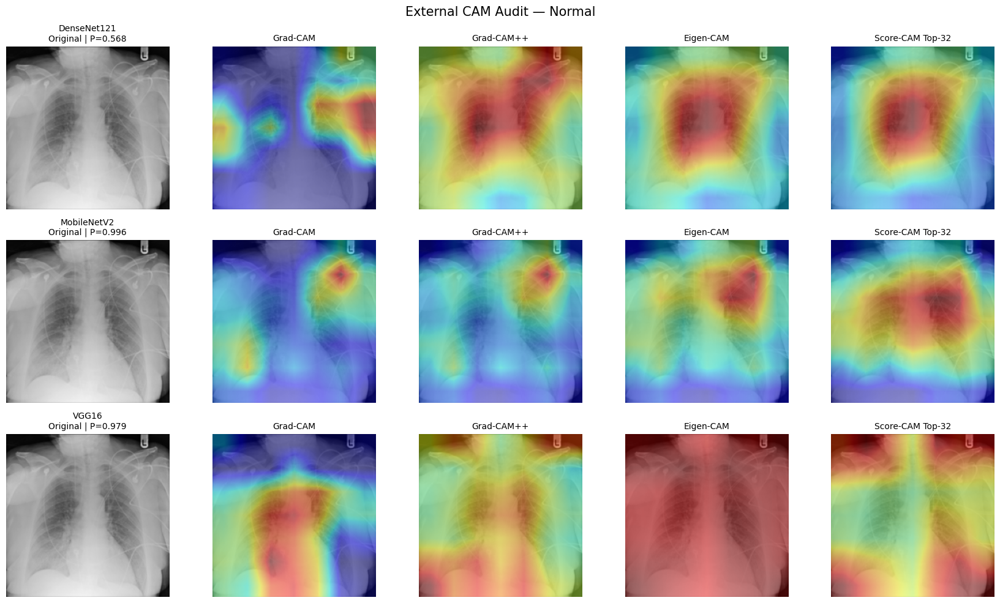

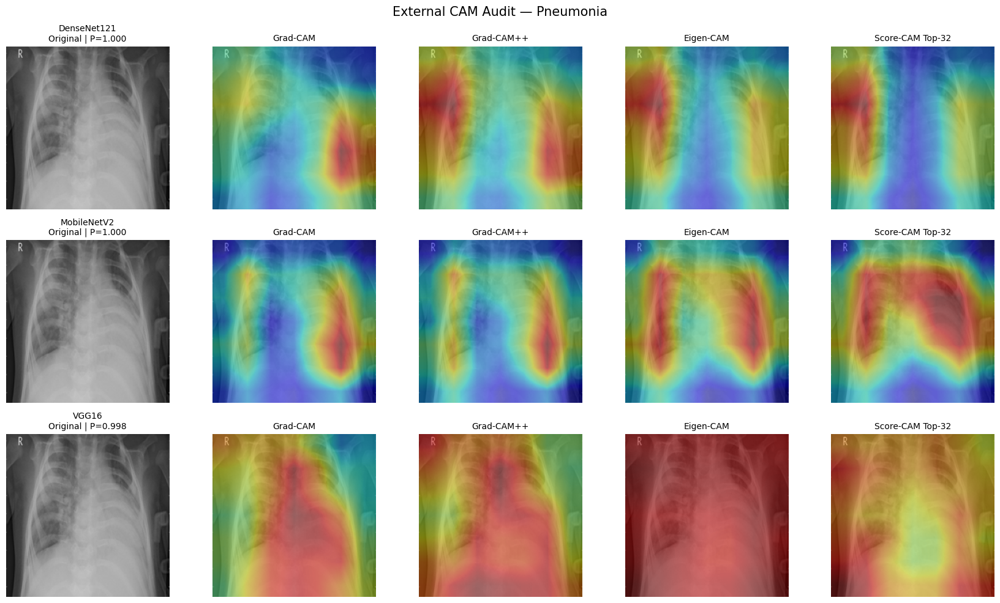

VISUAL AUDIT COMPLETE
Saved to: /kaggle/working/pneumonia_xai_workspace/experiments/cam_visual_audit


In [28]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import gc
from pathlib import Path

ROOT = Path("/kaggle/working/pneumonia_xai_workspace")
OUT = ROOT / "experiments" / "cam_visual_audit"
OUT.mkdir(parents=True, exist_ok=True)

MODELS = ["DenseNet121", "MobileNetV2", "VGG16"]
METHODS = [
    "Grad-CAM", "Grad-CAM++",
    "Eigen-CAM", "Score-CAM Top-32"
]

samples = pd.read_csv(
    ROOT / "experiments" / "external_cam_stability"
    / "external_cam_sample_manifest.csv"
)

# Reproducible first normal and pneumonia images
selected = pd.concat([
    samples[samples.label_id == 0].head(1),
    samples[samples.label_id == 1].head(1)
]).reset_index(drop=True)

audit_records = []

for image_idx, row in selected.iterrows():

    x = load_image(row["filepath"])
    true_label = int(row["label_id"])

    fig, axes = plt.subplots(
        len(MODELS), 5,
        figsize=(17, 10)
    )

    for model_idx, model_name in enumerate(MODELS):

        tf.keras.backend.clear_session()

        net = tf.keras.models.load_model(
            CHECKPOINTS[model_name][1],
            compile=False
        )

        spatial = [
            layer for layer in net.layers
            if len(getattr(layer.output, "shape", ())) == 4
        ]

        target_layer = spatial[-1].name

        feature_net = tf.keras.Model(
            net.inputs,
            [
                net.get_layer(target_layer).output,
                net.outputs[0]
            ]
        )

        prediction = net(
            tf.convert_to_tensor(
                x[None], tf.float32
            ),
            training=False
        )

        if isinstance(prediction, (list, tuple)):
            prediction = prediction[0]

        probability = float(
            np.asarray(prediction).reshape(-1)[0]
        )
        predicted_class = int(probability >= 0.5)

        maps = get_maps(
            net, feature_net, x, predicted_class
        )

        ax = axes[model_idx, 0]
        ax.imshow(x, cmap="gray")
        ax.set_title(
            f"{model_name}\nOriginal | P={probability:.3f}",
            fontsize=10
        )
        ax.axis("off")

        for j, method in enumerate(METHODS, start=1):

            cam = np.asarray(
                maps[method], np.float32
            )

            ax = axes[model_idx, j]
            ax.imshow(x, cmap="gray")
            ax.imshow(
                cam,
                cmap="jet",
                alpha=0.45,
                vmin=0,
                vmax=1
            )
            ax.set_title(method, fontsize=10)
            ax.axis("off")

            audit_records.append({
                "model": model_name,
                "filepath": row["filepath"],
                "true_label": true_label,
                "predicted_label": predicted_class,
                "method": method,
                "cam_min": float(cam.min()),
                "cam_max": float(cam.max()),
                "cam_std": float(cam.std())
            })

        del net, feature_net
        gc.collect()

    class_name = (
        "Normal" if true_label == 0
        else "Pneumonia"
    )

    fig.suptitle(
        f"External CAM Audit — {class_name}",
        fontsize=15
    )

    plt.tight_layout()
    plt.savefig(
        OUT / f"external_cam_{class_name.lower()}.png",
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

pd.DataFrame(audit_records).to_csv(
    OUT / "visual_audit_metadata.csv",
    index=False
)

print("VISUAL AUDIT COMPLETE")
print("Saved to:", OUT)


In [29]:

from pathlib import Path

SEARCH_ROOTS = [
    DATA_DIR,
    BACKUP
]

DIR_KEYWORDS = [
    "mask", "segment", "annotation",
    "lung", "roi", "contour"
]

print("===== LUNG MASK AVAILABILITY CHECK =====")

candidate_dirs = set()
candidate_files = []

for root in SEARCH_ROOTS:
    root = Path(root)

    if not root.exists():
        continue

    for p in root.rglob("*"):
        if p.is_dir():
            if any(k in p.name.lower() for k in DIR_KEYWORDS):
                candidate_dirs.add(str(p))

        elif p.is_file():
            name = p.stem.lower()

            if any(
                k in name for k in
                ["_mask", "lungmask", "lung_mask",
                 "_segmentation", "_seg"]
            ):
                candidate_files.append(str(p))

print("\nCandidate directories:")
for p in sorted(candidate_dirs)[:30]:
    print(p)

print("\nCandidate mask files:")
for p in candidate_files[:20]:
    print(p)

print("\nTotal candidate directories:", len(candidate_dirs))
print("Total candidate files:", len(candidate_files))

if not candidate_dirs and not candidate_files:
    print(
        "\nNo obvious lung masks found. "
        "Segmentation masks may need to be generated "
        "with a separate lung segmentation model."
    )

print("\nCHECK COMPLETE")


===== LUNG MASK AVAILABILITY CHECK =====

Candidate directories:

Candidate mask files:

Total candidate directories: 0
Total candidate files: 0

No obvious lung masks found. Segmentation masks may need to be generated with a separate lung segmentation model.

CHECK COMPLETE


In [31]:

from pathlib import Path
import subprocess

ROOT = Path("/kaggle/working/pneumonia_xai_workspace")
SEG_DIR = ROOT / "lung_segmentation"
REPO_DIR = SEG_DIR / "lung_cxr_segmentation"

SEG_DIR.mkdir(parents=True, exist_ok=True)

def run_cmd(command, timeout=300, cwd=None):
    print("\n$", " ".join(command), flush=True)
    result = subprocess.run(
        command,
        cwd=cwd,
        capture_output=True,
        text=True,
        timeout=timeout
    )
    print((result.stdout + result.stderr)[-1500:])
    if result.returncode != 0:
        raise RuntimeError(
            f"Command failed: {' '.join(command)}"
        )

try:
    # Install Git LFS in Kaggle
    run_cmd(["apt-get", "update", "-qq"], timeout=180)
    run_cmd(
        ["apt-get", "install", "-y", "git-lfs"],
        timeout=180
    )

    run_cmd(["git", "lfs", "version"])
    run_cmd(["git", "lfs", "install"])

    # Clone repository without downloading LFS objects yet
    if not (REPO_DIR / ".git").exists():
        run_cmd([
            "git", "clone",
            "--depth", "1",
            "https://github.com/niaid/lung_cxr_segmentation.git",
            str(REPO_DIR)
        ], timeout=240)

    # Download recommended 512px checkpoint
    weight_relative = (
        "segment_lung_cxr/data/weights/"
        "cxr_lung_segment_including_heart_512.pt"
    )

    run_cmd([
        "git", "lfs", "pull",
        "--include", weight_relative,
        "--exclude", ""
    ], cwd=REPO_DIR, timeout=300)

    weight_path = REPO_DIR / weight_relative

    if not weight_path.exists():
        raise FileNotFoundError(weight_path)

    size_mb = weight_path.stat().st_size / (1024**2)

    print("\n===== CHECKPOINT VERIFICATION =====")
    print("Path:", weight_path)
    print("Size:", round(size_mb, 2), "MB")

    with open(weight_path, "rb") as f:
        header = f.read(100)

    if header.startswith(b"version https://git-lfs"):
        raise RuntimeError(
            "Git LFS pointer downloaded instead of actual weights."
        )

    if size_mb < 1:
        raise RuntimeError(
            "Checkpoint unexpectedly small; verify download."
        )

    print("\nSUCCESS: Actual checkpoint file downloaded!")

except Exception as error:
    print("\nSETUP ERROR:", error)
    print(
        "If apt-get or git clone fails, "
        "check Kaggle Internet settings."
    )



$ apt-get update -qq
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


$ apt-get install -y git-lfs
Reading package lists...
Building dependency tree...
Reading state information...
The following NEW packages will be installed:
  git-lfs
0 upgraded, 1 newly installed, 0 to remove and 100 not upgraded.
Need to get 3,908 kB of archives.
After this operation, 11.7 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 git-lfs amd64 3.4.1-1ubuntu0.4 [3,908 kB]
Fetched 3,908 kB in 1s (3,100 kB/s)
Selecting previously unselected package git-lfs.
(Reading database ... 
(Reading database ... 5%
(Reading database ... 10%
(Reading database ... 15%
(Reading database ... 20%
(Reading database ... 25%
(Reading database ... 30%
(Reading database ... 35%
(Reading database ... 40%
(Reading database ... 45%
(

Installing: ['monai==1.5.1']
===== SELECTED IMAGES =====
                                                                                                                                 filepath  label_id
           /kaggle/input/datasets/haiderrasoolqadri/pneumonia-reproduction-backup/Original Dataset/ExternalDataset/NORMAL/Normal-7978.png         0
           /kaggle/input/datasets/haiderrasoolqadri/pneumonia-reproduction-backup/Original Dataset/ExternalDataset/NORMAL/Normal-7822.png         0
/kaggle/input/datasets/haiderrasoolqadri/pneumonia-reproduction-backup/Original Dataset/ExternalDataset/PNEUMONIA/Viral Pneumonia-352.png         1
/kaggle/input/datasets/haiderrasoolqadri/pneumonia-reproduction-backup/Original Dataset/ExternalDataset/PNEUMONIA/Viral Pneumonia-414.png         1

Running official segmentation inference...
I0000 00:00:1794980885.045521   19693 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/usr/local/lib/python3.13/dist-pack

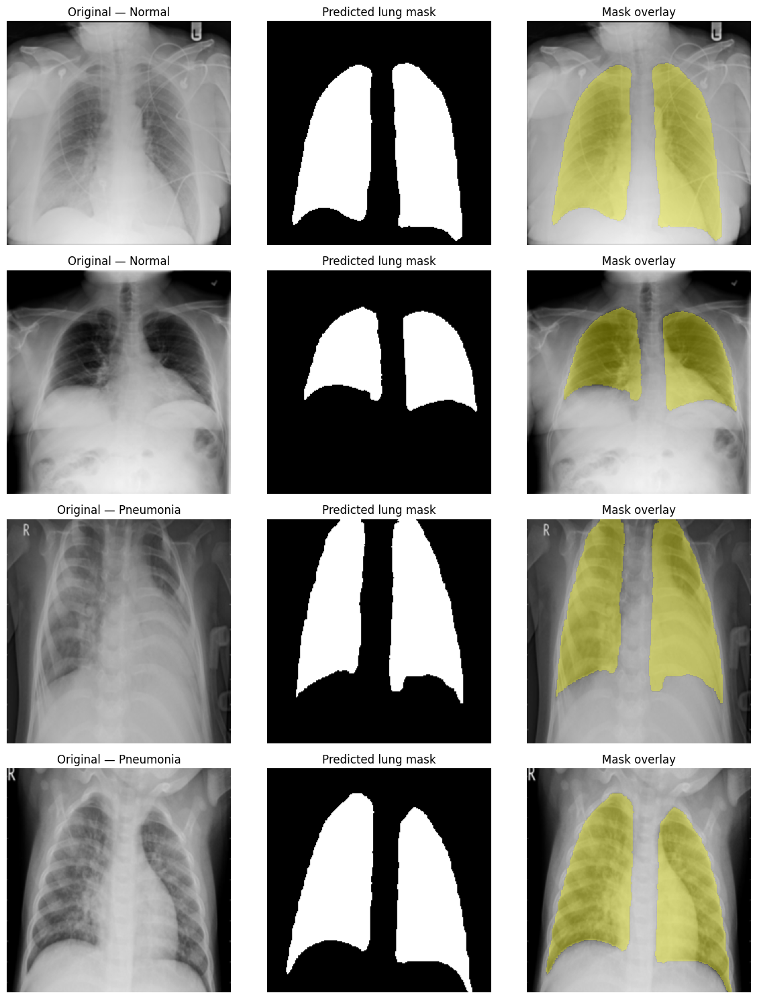


===== MASK QUALITY SUMMARY =====
 label  mask_area_fraction
     0              0.3585
     0              0.2058
     1              0.3346
     1              0.3598

Saved: /kaggle/working/pneumonia_xai_workspace/experiments/lung_mask_pilot/lung_segmentation_pilot.png


In [32]:

from pathlib import Path
import subprocess
import sys
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

ROOT = Path("/kaggle/working/pneumonia_xai_workspace")
REPO = ROOT / "lung_segmentation" / "lung_cxr_segmentation"
WEIGHT = (
    REPO / "segment_lung_cxr/data/weights/"
    "cxr_lung_segment_including_heart_512.pt"
)

OUT = ROOT / "experiments" / "lung_mask_pilot"
MASK_DIR = OUT / "masks"
OUT.mkdir(parents=True, exist_ok=True)
MASK_DIR.mkdir(parents=True, exist_ok=True)

assert WEIGHT.exists(), "Segmentation checkpoint missing."

# Install only missing dependencies
dependencies = {
    "SimpleITK": "SimpleITK==2.5.2",
    "monai": "monai==1.5.1",
    "pydicom": "pydicom==3.0.1"
}

missing = [
    package
    for module, package in dependencies.items()
    if importlib.util.find_spec(module) is None
]

if missing:
    print("Installing:", missing)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", *missing],
        check=True
    )

import SimpleITK as sitk

# Reuse external images already selected earlier
source = pd.read_csv(
    ROOT / "experiments" / "external_cam_stability"
    / "external_cam_sample_manifest.csv"
)

pilot = pd.concat([
    source[source["label_id"] == 0].head(2),
    source[source["label_id"] == 1].head(2)
]).reset_index(drop=True)

# Repository expects a CSV column named cxr_file
input_csv = OUT / "pilot_inputs.csv"

pd.DataFrame({
    "cxr_file": pilot["filepath"].tolist()
}).to_csv(input_csv, index=False)

print("===== SELECTED IMAGES =====")
print(
    pilot[["filepath", "label_id"]]
    .to_string(index=False)
)

# Use the authors' official inference implementation
command = [
    sys.executable,
    "-m",
    "segment_lung_cxr.inference.inference_lung_segment",
    str(input_csv),
    str(WEIGHT),
    "--output_pred_dir",
    str(MASK_DIR),
    "--img_size", "512", "512",
    "--patch_size", "512", "512",
    "--post_process", "True"
]

print("\nRunning official segmentation inference...")

result = subprocess.run(
    command,
    cwd=str(REPO),
    capture_output=True,
    text=True
)

print((result.stdout + result.stderr)[-3500:])

if result.returncode != 0:
    raise RuntimeError(
        "Segmentation inference failed. "
        "Share the traceback above."
    )

# Visual inspection of produced masks
fig, axes = plt.subplots(4, 3, figsize=(12, 15))
quality_records = []

for i, row in pilot.iterrows():
    path = Path(row["filepath"])
    mask_path = MASK_DIR / (path.stem + ".nrrd")

    if not mask_path.exists():
        raise FileNotFoundError(mask_path)

    x = load_image(str(path))
    mask_image = sitk.ReadImage(str(mask_path))
    mask = sitk.GetArrayFromImage(mask_image)

    # Match the classification input size
    mask_224 = tf.image.resize(
        mask.astype(np.float32)[None, ..., None],
        (224, 224),
        method="nearest"
    )[0, :, :, 0].numpy() > 0.5

    axes[i, 0].imshow(x)
    axes[i, 0].set_title(
        "Original — " +
        ("Normal" if row["label_id"] == 0 else "Pneumonia")
    )

    axes[i, 1].imshow(mask_224, cmap="gray")
    axes[i, 1].set_title("Predicted lung mask")

    axes[i, 2].imshow(x)
    axes[i, 2].imshow(
        np.ma.masked_where(~mask_224, mask_224),
        cmap="spring",
        alpha=0.35,
        vmin=0,
        vmax=1
    )
    axes[i, 2].set_title("Mask overlay")

    for ax in axes[i]:
        ax.axis("off")

    quality_records.append({
        "filepath": str(path),
        "label": int(row["label_id"]),
        "mask_area_fraction": float(mask_224.mean()),
        "mask_file": str(mask_path)
    })

plt.tight_layout()

figure_path = OUT / "lung_segmentation_pilot.png"
plt.savefig(figure_path, dpi=160)
plt.show()

quality_df = pd.DataFrame(quality_records)
quality_df.to_csv(
    OUT / "lung_mask_pilot_quality.csv",
    index=False
)

print("\n===== MASK QUALITY SUMMARY =====")
print(
    quality_df[
        ["label", "mask_area_fraction"]
    ].round(4).to_string(index=False)
)
print("\nSaved:", figure_path)


In [33]:

import numpy as np
import pandas as pd
import tensorflow as tf
import SimpleITK as sitk
import subprocess
import sys
import gc
import matplotlib.pyplot as plt

from pathlib import Path

# ==========================================
# 1. CONFIGURATION
# ==========================================

ROOT = Path("/kaggle/working/pneumonia_xai_workspace")
REPO = ROOT / "lung_segmentation" / "lung_cxr_segmentation"

WEIGHT = (
    REPO / "segment_lung_cxr/data/weights/"
    "cxr_lung_segment_including_heart_512.pt"
)

OUT = ROOT / "experiments" / "lung_attention_ratio"
MASK_DIR = OUT / "masks"
OUT.mkdir(parents=True, exist_ok=True)
MASK_DIR.mkdir(parents=True, exist_ok=True)

MODELS = ["DenseNet121", "MobileNetV2", "VGG16"]
METHODS = [
    "Grad-CAM", "Grad-CAM++",
    "Eigen-CAM", "Score-CAM Top-32"
]

samples = pd.read_csv(
    ROOT / "experiments" / "external_cam_stability"
    / "external_cam_sample_manifest.csv"
)

assert len(samples) == 20
assert WEIGHT.exists()
assert callable(get_maps)
assert callable(load_image)

# ==========================================
# 2. GENERATE LUNG MASKS
# ==========================================

input_csv = OUT / "segmentation_inputs.csv"

pd.DataFrame({
    "cxr_file": samples["filepath"].tolist()
}).to_csv(input_csv, index=False)

def get_mask_path(filepath):
    return MASK_DIR / (Path(filepath).stem + ".nrrd")

# Check for output filename collisions
stems = samples["filepath"].apply(
    lambda p: Path(p).stem
)
assert stems.is_unique, (
    "Duplicate image stems: masks could overwrite each other"
)

missing_masks = [
    p for p in samples["filepath"]
    if not get_mask_path(p).exists()
]

if missing_masks:
    print("Generating masks for 20 external images...")

    cmd = [
        sys.executable,
        "-m",
        "segment_lung_cxr.inference.inference_lung_segment",
        str(input_csv),
        str(WEIGHT),
        "--output_pred_dir",
        str(MASK_DIR),
        "--img_size", "512", "512",
        "--patch_size", "512", "512",
        "--post_process", "True"
    ]

    result = subprocess.run(
        cmd,
        cwd=str(REPO),
        capture_output=True,
        text=True
    )

    print((result.stdout + result.stderr)[-3000:])

    if result.returncode != 0:
        raise RuntimeError(
            "Segmentation failed. Check output above."
        )

assert all(
    get_mask_path(p).exists()
    for p in samples["filepath"]
), "Some lung masks are missing"

print("All 20 lung masks available.")

# ==========================================
# 3. LOAD AND ALIGN MASKS
# ==========================================

def load_lung_mask(filepath):
    path = get_mask_path(filepath)

    mask = sitk.GetArrayFromImage(
        sitk.ReadImage(str(path))
    )

    mask = np.squeeze(mask).astype(np.float32)

    if mask.ndim != 2:
        raise ValueError(
            f"Unexpected mask shape: {mask.shape}"
        )

    mask = tf.image.resize(
        mask[None, ..., None],
        (224, 224),
        method="nearest"
    )[0, :, :, 0].numpy()

    return mask > 0.5

mask_lookup = {}
quality_records = []

for _, row in samples.iterrows():
    filepath = row["filepath"]
    mask = load_lung_mask(filepath)

    area = float(mask.mean())

    # Screening heuristic, not validated segmentation QC
    quality_flag = (
        "REVIEW" if area < 0.12 or area > 0.65
        else "PASS_PRELIMINARY"
    )

    mask_lookup[filepath] = mask

    quality_records.append({
        "filepath": filepath,
        "label": int(row["label_id"]),
        "mask_area_fraction": area,
        "quality_flag": quality_flag
    })

quality_df = pd.DataFrame(quality_records)
quality_df.to_csv(
    OUT / "mask_quality.csv",
    index=False
)

print("\n===== MASK AREA SUMMARY =====")
print(
    quality_df.groupby("label")[
        "mask_area_fraction"
    ].agg(["mean", "std", "min", "max"])
    .round(4).to_string()
)

print("\nMasks flagged for review:",
      (quality_df["quality_flag"] == "REVIEW").sum())

# ==========================================
# 4. LAR AND ENRICHMENT
# ==========================================

def calculate_lar(cam, lung_mask):
    h = np.asarray(cam, dtype=np.float64)
    mask = np.asarray(lung_mask, dtype=bool)

    if h.shape != mask.shape:
        raise ValueError("CAM/mask shape mismatch")

    if not np.isfinite(h).all():
        return np.nan, np.nan, True

    # CAMs are expected to be nonnegative
    h = np.maximum(h, 0.0)

    total_mass = float(h.sum())
    mask_area = float(mask.mean())

    if total_mass <= 1e-10 or mask_area <= 0:
        return np.nan, np.nan, True

    lung_mass = float(h[mask].sum())
    lar = lung_mass / total_mass
    enrichment = lar / mask_area

    return lar, enrichment, False

# ==========================================
# 5. COMPUTE LAR FOR THREE CNN MODELS
# ==========================================

results_file = OUT / "lar_per_image.csv"

records = (
    pd.read_csv(results_file).to_dict("records")
    if results_file.exists()
    else []
)

completed = {
    (r["model"], r["filepath"], r["method"])
    for r in records
}

for model_name in MODELS:
    print("\n" + "="*45)
    print("LAR MODEL:", model_name)
    print("="*45)

    tf.keras.backend.clear_session()

    net = tf.keras.models.load_model(
        CHECKPOINTS[model_name][1],
        compile=False
    )

    spatial = [
        layer for layer in net.layers
        if len(getattr(layer.output, "shape", ())) == 4
    ]

    target = spatial[-1].name

    feature_net = tf.keras.Model(
        net.inputs,
        [
            net.get_layer(target).output,
            net.outputs[0]
        ]
    )

    for idx, row in samples.iterrows():
        filepath = row["filepath"]

        if all(
            (model_name, filepath, m) in completed
            for m in METHODS
        ):
            continue

        x = load_image(filepath)
        mask = mask_lookup[filepath]
        label = int(row["label_id"])

        output = net(
            tf.convert_to_tensor(
                x[None], tf.float32
            ),
            training=False
        )

        if isinstance(output, (list, tuple)):
            output = output[0]

        probability = float(
            np.asarray(output).reshape(-1)[0]
        )

        predicted_class = int(probability >= 0.5)

        # Explain predicted class, including errors
        cams = get_maps(
            net, feature_net,
            x, predicted_class
        )

        for method in METHODS:
            key = (model_name, filepath, method)

            if key in completed:
                continue

            lar, enrichment, degenerate = calculate_lar(
                cams[method], mask
            )

            records.append({
                "model": model_name,
                "fold": 1,
                "filepath": filepath,
                "label": label,
                "predicted_class": predicted_class,
                "correct_prediction": (
                    predicted_class == label
                ),
                "method": method,
                "lar": lar,
                "enrichment": enrichment,
                "mask_area_fraction": float(mask.mean()),
                "degenerate": degenerate
            })

            completed.add(key)

        # Save after every image
        pd.DataFrame(records).to_csv(
            results_file, index=False
        )

        print(f"Image {idx+1}/20 completed")

    del net, feature_net
    gc.collect()

# ==========================================
# 6. FINAL SUMMARY
# ==========================================

lar_df = pd.DataFrame(records)

summary = lar_df.groupby(
    ["model", "method"]
).agg(
    Mean_LAR=("lar", "mean"),
    Std_LAR=("lar", "std"),
    Mean_Enrichment=("enrichment", "mean"),
    Std_Enrichment=("enrichment", "std"),
    Degenerate_Count=("degenerate", "sum"),
    N=("lar", "count")
).reset_index()

summary.to_csv(
    OUT / "lar_summary.csv",
    index=False
)

print("\n===== LUNG ATTENTION RATIO SUMMARY =====")
print(summary.round(4).to_string(index=False))

print("\n===== LAR BY CORRECTNESS =====")
by_correctness = lar_df.groupby(
    ["model", "method", "correct_prediction"]
).agg(
    Mean_LAR=("lar", "mean"),
    Mean_Enrichment=("enrichment", "mean"),
    N=("lar", "count")
).reset_index()

by_correctness.to_csv(
    OUT / "lar_by_correctness.csv",
    index=False
)

print(by_correctness.round(4).to_string(index=False))
print("\nSaved to:", OUT)


Generating masks for 20 external images...
I0000 00:00:1794981087.550815   19931 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/usr/local/lib/python3.13/dist-packages/monai/inferers/utils.py:226: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  win_data = torch.cat([inputs[win_slice] for win_slice in unravel_slice]).to(sw_device)
/usr/local/lib/python3.13/dist-packages/monai/inferers/utils.py:370: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.

In [34]:

from pathlib import Path
import pandas as pd
import numpy as np
import zipfile
import json
from datetime import datetime, timezone

ROOT = Path("/kaggle/working/pneumonia_xai_workspace")
EXP = ROOT / "experiments"
LAR_DIR = EXP / "lung_attention_ratio"

lar = pd.read_csv(LAR_DIR / "lar_per_image.csv")
quality = pd.read_csv(LAR_DIR / "mask_quality.csv")

# =========================================
# 1. IDENTIFY FLAGGED MASKS
# =========================================

flagged = quality[
    quality["quality_flag"] == "REVIEW"
]

print("===== FLAGGED LUNG MASKS =====")
print(
    flagged[
        ["filepath", "label", "mask_area_fraction"]
    ].to_string(index=False)
)

# =========================================
# 2. SENSITIVITY ANALYSIS
# =========================================

valid_paths = set(
    quality.loc[
        quality["quality_flag"] != "REVIEW",
        "filepath"
    ]
)

def summarize(data, suffix):
    return data.groupby(
        ["model", "method"]
    ).agg(
        **{
            f"LAR_{suffix}": ("lar", "mean"),
            f"Enrichment_{suffix}": ("enrichment", "mean"),
            f"N_{suffix}": ("filepath", "count")
        }
    ).reset_index()

all_summary = summarize(lar, "all")

filtered_summary = summarize(
    lar[lar["filepath"].isin(valid_paths)],
    "filtered"
)

comparison = all_summary.merge(
    filtered_summary,
    on=["model", "method"],
    how="outer"
)

comparison["LAR_change"] = (
    comparison["LAR_filtered"]
    - comparison["LAR_all"]
)

comparison["Enrichment_change"] = (
    comparison["Enrichment_filtered"]
    - comparison["Enrichment_all"]
)

comparison.to_csv(
    LAR_DIR / "lar_mask_sensitivity.csv",
    index=False
)

print("\n===== LAR SENSITIVITY ANALYSIS =====")
print(comparison.round(4).to_string(index=False))

# =========================================
# 3. BACKUP EXPERIMENT OUTPUTS
# =========================================

BACKUP_ZIP = Path(
    "/kaggle/working/pneumonia_xai_experiment_backup.zip"
)

# Include experiments and useful implementation files
include_dirs = [
    EXP,
    ROOT / "repository_code"
]

# Exclude large pretrained weights, Git objects
# and duplicate raw datasets
excluded_parts = {
    ".git", "__pycache__", ".ipynb_checkpoints"
}

added = 0

with zipfile.ZipFile(
    BACKUP_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=4
) as archive:

    for directory in include_dirs:
        if not directory.exists():
            continue

        for file in directory.rglob("*"):
            if not file.is_file():
                continue

            relative = file.relative_to(ROOT)

            if any(
                part in excluded_parts
                for part in relative.parts
            ):
                continue

            archive.write(
                file,
                arcname=str(relative)
            )
            added += 1

    metadata = {
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "models": [
            "DenseNet121", "MobileNetV2", "VGG16"
        ],
        "checkpoint_fold": 1,
        "external_sample_size": 500,
        "external_cam_sample_size": 20,
        "lar_methods": [
            "Grad-CAM",
            "Grad-CAM++ (approximate)",
            "Eigen-CAM (uncentered)",
            "Score-CAM Top-32"
        ],
        "note": (
            "Exploratory experiment backup. "
            "CAM implementation validation remains pending."
        )
    }

    archive.writestr(
        "backup_metadata.json",
        json.dumps(metadata, indent=2)
    )

print("\n===== BACKUP CREATED =====")
print("File:", BACKUP_ZIP)
print("Archived files:", added)
print(
    "Size:",
    round(BACKUP_ZIP.stat().st_size / (1024**2), 2),
    "MB"
)

with zipfile.ZipFile(BACKUP_ZIP) as archive:
    bad_file = archive.testzip()

assert bad_file is None, (
    f"Corrupted ZIP entry: {bad_file}"
)

print("ZIP integrity: PASSED")
print(
    "\nIMPORTANT: Save this ZIP outside the current "
    "Kaggle session or publish it as a private Kaggle dataset."
)


===== FLAGGED LUNG MASKS =====
                                                                                                                      filepath  label  mask_area_fraction
/kaggle/input/datasets/haiderrasoolqadri/pneumonia-reproduction-backup/Original Dataset/ExternalDataset/NORMAL/Normal-4803.png      0            0.106904

===== LAR SENSITIVITY ANALYSIS =====
      model           method  LAR_all  Enrichment_all  N_all  LAR_filtered  Enrichment_filtered  N_filtered  LAR_change  Enrichment_change
DenseNet121        Eigen-CAM   0.3498          1.1546     20        0.3578               1.1179          19      0.0080            -0.0367
DenseNet121         Grad-CAM   0.2940          0.9585     20        0.3010               0.9302          19      0.0070            -0.0284
DenseNet121       Grad-CAM++   0.3260          1.0682     20        0.3345               1.0429          19      0.0084            -0.0253
DenseNet121 Score-CAM Top-32   0.3493          1.1622     20       


## Lung Attention Ratio (LAR): Sensitivity Analysis

### Objective
Evaluate whether CAM explanations concentrate attention inside
automatically estimated lung regions and assess sensitivity to
potential segmentation-mask errors.

### Experimental Setup
- Models: DenseNet121, MobileNetV2, VGG16
- Checkpoints: Authors' pretrained Fold 1 checkpoints
- Dataset: 20 external chest X-rays (10 Normal, 10 Pneumonia)
- CAM methods: Grad-CAM, approximate Grad-CAM++,
  uncentered Eigen-CAM, and Score-CAM Top-32
- Lung masks: Pretrained NIAID segmentation model
- Metrics: Lung Attention Ratio (LAR) and area-normalized enrichment

### Key Findings
1. MobileNetV2 with Score-CAM Top-32 achieved the highest mean
   lung-attention enrichment (1.5092).
2. VGG16 with Eigen-CAM exhibited nearly uniform spatial attribution,
   with mean enrichment of 1.0044.
3. One external Normal image had an unusually small predicted
   lung-mask area (10.69%) and was flagged for review.

### Sensitivity Analysis
After excluding the flagged image:
- MobileNetV2 Score-CAM Top-32 enrichment: 1.5092 -> 1.4853
- VGG16 Eigen-CAM enrichment: 1.0044 -> 1.0033
- The main descriptive trends remained similar.

### Limitations
- Lung masks were automatically generated, not manually annotated.
- The segmentation checkpoint requires anatomical-scope verification.
- LAR measures attention within estimated lung regions, not lesions.
- CAM implementations require final reference validation.
- Results are exploratory and based on 20 external images.


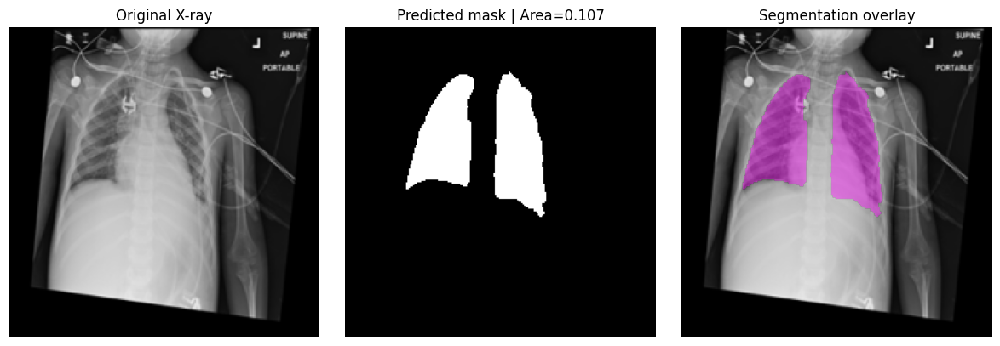

Saved: /kaggle/working/pneumonia_xai_workspace/experiments/lung_attention_ratio/flagged_mask_review.png


In [35]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import SimpleITK as sitk
import tensorflow as tf
from pathlib import Path

ROOT = Path("/kaggle/working/pneumonia_xai_workspace")
LAR_DIR = ROOT / "experiments" / "lung_attention_ratio"

quality = pd.read_csv(LAR_DIR / "mask_quality.csv")
flagged = quality[quality["quality_flag"] == "REVIEW"]

assert len(flagged) > 0, "No flagged masks found."

fig, axes = plt.subplots(
    len(flagged), 3,
    figsize=(12, 4 * len(flagged)),
    squeeze=False
)

for i, row in enumerate(flagged.itertuples()):
    filepath = Path(row.filepath)
    mask_path = LAR_DIR / "masks" / (filepath.stem + ".nrrd")

    assert mask_path.exists(), mask_path

    original = load_image(str(filepath))

    mask = np.squeeze(
        sitk.GetArrayFromImage(
            sitk.ReadImage(str(mask_path))
        )
    ).astype(np.float32)

    mask = tf.image.resize(
        mask[None, ..., None],
        (224, 224),
        method="nearest"
    )[0, :, :, 0].numpy() > 0.5

    axes[i, 0].imshow(original)
    axes[i, 0].set_title("Original X-ray")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title(
        f"Predicted mask | Area={mask.mean():.3f}"
    )

    axes[i, 2].imshow(original)
    axes[i, 2].imshow(
        np.ma.masked_where(~mask, mask),
        cmap="spring",
        alpha=0.4
    )
    axes[i, 2].set_title("Segmentation overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()

output = LAR_DIR / "flagged_mask_review.png"
plt.savefig(output, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", output)


In [37]:

import sys
import subprocess
import importlib
import tensorflow as tf

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)

# Install actual published version.
# --no-deps avoids changing the working TensorFlow environment.
result = subprocess.run(
    [
        sys.executable,
        "-m", "pip", "install",
        "--no-deps",
        "tf-keras-vis==0.8.7"
    ],
    capture_output=True,
    text=True
)

print("\n===== INSTALLATION =====")
print((result.stdout + result.stderr)[-2000:])

if result.returncode != 0:
    raise RuntimeError("Installation failed")

print("\n===== IMPORT CHECK =====")

try:
    tf_keras_vis = importlib.import_module("tf_keras_vis")

    from tf_keras_vis.gradcam_plus_plus import GradcamPlusPlus
    from tf_keras_vis.utils.model_modifiers import ReplaceToLinear

    print("tf-keras-vis version: 0.8.7")
    print("GradcamPlusPlus imported:", GradcamPlusPlus)
    print("ReplaceToLinear imported:", ReplaceToLinear)
    print("\nSUCCESS: Reference library import works")

except Exception as e:
    print("IMPORT FAILED:", repr(e))
    print(
        "We will use an independently implemented "
        "reference formulation instead."
    )


Python: 3.13.16
TensorFlow: 2.21.0

===== INSTALLATION =====


===== IMPORT CHECK =====
tf-keras-vis version: 0.8.7
GradcamPlusPlus imported: <class 'tf_keras_vis.gradcam_plus_plus.GradcamPlusPlus'>
ReplaceToLinear imported: <class 'tf_keras_vis.utils.model_modifiers.ReplaceToLinear'>

SUCCESS: Reference library import works


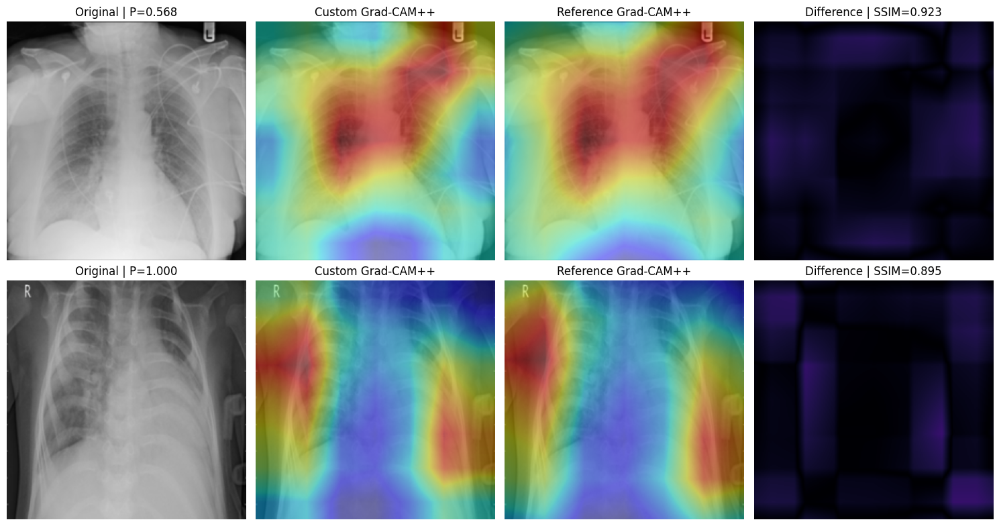


===== GRADCAM++ REFERENCE VALIDATION =====
                                                                                                                                 filepath  true_label  target_class  prediction   SSIM  Spearman    MAE  Custom_Std  Reference_Std
           /kaggle/input/datasets/haiderrasoolqadri/pneumonia-reproduction-backup/Original Dataset/ExternalDataset/NORMAL/Normal-7978.png           0             1      0.5676 0.9226    0.9772 0.0617      0.2165         0.2045
/kaggle/input/datasets/haiderrasoolqadri/pneumonia-reproduction-backup/Original Dataset/ExternalDataset/PNEUMONIA/Viral Pneumonia-352.png           1             1      0.9996 0.8947    0.9624 0.0550      0.2395         0.2365

Saved to: /kaggle/working/pneumonia_xai_workspace/experiments/gradcampp_reference_validation


121855

In [38]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import gc

from pathlib import Path
from scipy.stats import spearmanr
from skimage.metrics import structural_similarity as ssim
from tf_keras_vis.gradcam_plus_plus import GradcamPlusPlus

ROOT = Path("/kaggle/working/pneumonia_xai_workspace")
OUT = ROOT / "experiments" / "gradcampp_reference_validation"
OUT.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "DenseNet121"
TARGET_LAYER = "relu"

# Use exactly one normal and one pneumonia image
samples = pd.read_csv(
    ROOT / "experiments" / "external_cam_stability"
    / "external_cam_sample_manifest.csv"
)

selected = pd.concat([
    samples[samples.label_id == 0].head(1),
    samples[samples.label_id == 1].head(1)
]).reset_index(drop=True)

tf.keras.backend.clear_session()

net = tf.keras.models.load_model(
    CHECKPOINTS[MODEL_NAME][1],
    compile=False
)

feature_net = tf.keras.Model(
    inputs=net.inputs,
    outputs=[
        net.get_layer(TARGET_LAYER).output,
        net.outputs[0]
    ]
)

# Do not replace sigmoid with linear:
# we want to compare against our original
# signed-logit scoring protocol.
reference = GradcamPlusPlus(
    net,
    model_modifier=None,
    clone=False
)

def make_target_score(target_class):
    def score(outputs):
        p = tf.reshape(
            tf.cast(outputs, tf.float32), [-1]
        )
        p = tf.clip_by_value(
            p, 1e-6, 1.0 - 1e-6
        )
        logit = tf.math.log(p) - tf.math.log1p(-p)

        return logit if target_class == 1 else -logit

    return score

def normalize_map(arr):
    a = np.asarray(arr, dtype=np.float32)
    a = np.squeeze(a)

    if a.shape != (224, 224):
        a = tf.image.resize(
            a[None, ..., None],
            (224, 224)
        )[0, :, :, 0].numpy()

    a = np.maximum(a, 0)
    a -= a.min()

    if a.max() > 1e-8:
        a /= a.max()

    return a

records = []
fig, axes = plt.subplots(2, 4, figsize=(15, 8))

for idx, row in selected.iterrows():

    x = load_image(row["filepath"])

    p = net.predict(
        x[None], verbose=0
    ).reshape(-1)[0]

    # Fixed clean predicted class
    target_class = int(p >= 0.5)

    # Existing custom approximation
    custom_maps = get_maps(
        net, feature_net, x, target_class
    )
    custom = normalize_map(
        custom_maps["Grad-CAM++"]
    )

    # Library reference on same target layer
    try:
        ref_result = reference(
            make_target_score(target_class),
            x[None],
            penultimate_layer=TARGET_LAYER,
            seek_penultimate_conv_layer=False,
            normalize_cam=True,
            expand_cam=True
        )

        reference_map = normalize_map(
            ref_result[0]
        )

    except Exception as exc:
        print(
            "Reference execution failed:",
            type(exc).__name__,
            str(exc)
        )
        raise

    similarity = float(
        ssim(custom, reference_map, data_range=1.0)
    )

    if custom.std() > 1e-8 and reference_map.std() > 1e-8:
        rho = float(
            spearmanr(
                custom.ravel(),
                reference_map.ravel()
            ).statistic
        )
    else:
        rho = np.nan

    mae = float(
        np.mean(np.abs(custom-reference_map))
    )

    records.append({
        "filepath": row["filepath"],
        "true_label": int(row["label_id"]),
        "target_class": target_class,
        "prediction": float(p),
        "SSIM": similarity,
        "Spearman": rho,
        "MAE": mae,
        "Custom_Std": float(custom.std()),
        "Reference_Std": float(reference_map.std())
    })

    axes[idx, 0].imshow(x)
    axes[idx, 0].set_title(
        f"Original | P={p:.3f}"
    )

    axes[idx, 1].imshow(x)
    axes[idx, 1].imshow(
        custom, cmap="jet",
        alpha=0.45, vmin=0, vmax=1
    )
    axes[idx, 1].set_title("Custom Grad-CAM++")

    axes[idx, 2].imshow(x)
    axes[idx, 2].imshow(
        reference_map, cmap="jet",
        alpha=0.45, vmin=0, vmax=1
    )
    axes[idx, 2].set_title("Reference Grad-CAM++")

    axes[idx, 3].imshow(
        np.abs(custom-reference_map),
        cmap="magma",
        vmin=0, vmax=1
    )
    axes[idx, 3].set_title(
        f"Difference | SSIM={similarity:.3f}"
    )

    for ax in axes[idx]:
        ax.axis("off")

    np.save(
        OUT / f"custom_{idx}.npy",
        custom
    )
    np.save(
        OUT / f"reference_{idx}.npy",
        reference_map
    )

plt.tight_layout()
plt.savefig(
    OUT / "gradcampp_reference_comparison.png",
    dpi=180
)
plt.show()

results = pd.DataFrame(records)
results.to_csv(
    OUT / "gradcampp_reference_metrics.csv",
    index=False
)

print("\n===== GRADCAM++ REFERENCE VALIDATION =====")
print(results.round(4).to_string(index=False))

print("\nSaved to:", OUT)

del net, feature_net, reference
gc.collect()


In [39]:

import numpy as np
import pandas as pd
import tensorflow as tf
import gc

from pathlib import Path
from scipy.stats import spearmanr
from skimage.metrics import structural_similarity as ssim
from tf_keras_vis.gradcam_plus_plus import GradcamPlusPlus

ROOT = Path("/kaggle/working/pneumonia_xai_workspace")
OUT = ROOT / "experiments" / "gradcampp_reference_validation"
OUT.mkdir(parents=True, exist_ok=True)

MODELS = ["DenseNet121", "MobileNetV2", "VGG16"]

TARGET_LAYERS = {
    "DenseNet121": "relu",
    "MobileNetV2": "out_relu",
    "VGG16": "block5_pool"
}

manifest = pd.read_csv(
    ROOT / "experiments" / "external_cam_stability"
    / "external_cam_sample_manifest.csv"
)

selected = pd.concat([
    manifest[manifest.label_id == 0].head(1),
    manifest[manifest.label_id == 1].head(1)
]).reset_index(drop=True)

def reference_score(target):
    def score(outputs):
        if isinstance(outputs, (list, tuple)):
            outputs = outputs[0]

        p = tf.reshape(
            tf.cast(outputs, tf.float32), [-1]
        )
        p = tf.clip_by_value(p, 1e-6, 1 - 1e-6)
        z = tf.math.log(p) - tf.math.log1p(-p)
        return z if target == 1 else -z
    return score

def normalize_validation_cam(a):
    a = np.squeeze(np.asarray(a, np.float32))

    if a.shape != (224, 224):
        a = tf.image.resize(
            a[None, ..., None], (224, 224)
        )[0, :, :, 0].numpy()

    a = np.maximum(a, 0)
    a -= a.min()

    if a.max() > 1e-8:
        a /= a.max()

    return a

results = []

for model_name in MODELS:

    print("\nVALIDATING:", model_name)
    tf.keras.backend.clear_session()

    net = tf.keras.models.load_model(
        CHECKPOINTS[model_name][1],
        compile=False
    )

    layer_name = TARGET_LAYERS[model_name]

    feature_net = tf.keras.Model(
        net.inputs,
        [
            net.get_layer(layer_name).output,
            net.outputs[0]
        ]
    )

    reference = GradcamPlusPlus(
        net,
        model_modifier=None,
        clone=False
    )

    for idx, row in selected.iterrows():
        x = load_image(row["filepath"])

        prediction = np.asarray(
            net(x[None], training=False)
        ).reshape(-1)[0]

        target = int(prediction >= 0.5)

        custom = normalize_validation_cam(
            get_maps(
                net, feature_net, x, target
            )["Grad-CAM++"]
        )

        ref_cam = reference(
            reference_score(target),
            x[None],
            penultimate_layer=layer_name,
            seek_penultimate_conv_layer=False,
            normalize_cam=True,
            expand_cam=True
        )

        ref_cam = normalize_validation_cam(ref_cam[0])

        if custom.std() > 1e-8 and ref_cam.std() > 1e-8:
            rho = float(
                spearmanr(
                    custom.ravel(),
                    ref_cam.ravel()
                ).statistic
            )
        else:
            rho = np.nan

        results.append({
            "Model": model_name,
            "Image_Class": (
                "Normal" if row["label_id"] == 0
                else "Pneumonia"
            ),
            "Target_Class": target,
            "SSIM": float(
                ssim(custom, ref_cam, data_range=1.0)
            ),
            "Spearman": rho,
            "MAE": float(
                np.mean(np.abs(custom - ref_cam))
            ),
            "Custom_Std": float(custom.std()),
            "Reference_Std": float(ref_cam.std())
        })

        print(
            f"  {results[-1]['Image_Class']}: "
            f"SSIM={results[-1]['SSIM']:.4f}, "
            f"Spearman={rho:.4f}"
        )

    del net, feature_net, reference
    gc.collect()

results_df = pd.DataFrame(results)

results_df.to_csv(
    OUT / "gradcampp_three_model_validation.csv",
    index=False
)

print("\n===== THREE-MODEL GRADCAM++ VALIDATION =====")
print(results_df.round(4).to_string(index=False))

print("\n===== MODEL-LEVEL SUMMARY =====")
print(
    results_df.groupby("Model")[
        ["SSIM", "Spearman", "MAE"]
    ].mean().round(4).to_string()
)

print("\nSaved to:", OUT)



VALIDATING: DenseNet121
  Normal: SSIM=0.9226, Spearman=0.9772
  Pneumonia: SSIM=0.8947, Spearman=0.9624

VALIDATING: MobileNetV2


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer_28']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


  Normal: SSIM=0.8761, Spearman=0.9016
  Pneumonia: SSIM=0.8087, Spearman=0.8638

VALIDATING: VGG16
  Normal: SSIM=0.9006, Spearman=0.9325
  Pneumonia: SSIM=0.8955, Spearman=0.9467

===== THREE-MODEL GRADCAM++ VALIDATION =====
      Model Image_Class  Target_Class   SSIM  Spearman    MAE  Custom_Std  Reference_Std
DenseNet121      Normal             1 0.9226    0.9772 0.0617      0.2165         0.2045
DenseNet121   Pneumonia             1 0.8947    0.9624 0.0550      0.2395         0.2365
MobileNetV2      Normal             1 0.8761    0.9016 0.0523      0.1573         0.1542
MobileNetV2   Pneumonia             1 0.8087    0.8638 0.0853      0.1972         0.1890
      VGG16      Normal             1 0.9006    0.9325 0.0607      0.2006         0.1794
      VGG16   Pneumonia             1 0.8955    0.9467 0.0617      0.2522         0.2319

===== MODEL-LEVEL SUMMARY =====
               SSIM  Spearman     MAE
Model                                
DenseNet121  0.9087    0.9698  0.0584
Mob

In [40]:

import numpy as np
import pandas as pd
import tensorflow as tf
import gc
from pathlib import Path
from scipy.stats import spearmanr
from skimage.metrics import structural_similarity as ssim
from tf_keras_vis.gradcam_plus_plus import GradcamPlusPlus

ROOT = Path("/kaggle/working/pneumonia_xai_workspace")
OUT = ROOT / "experiments" / "gradcampp_reference_validation"
OUT.mkdir(parents=True, exist_ok=True)

MODELS = ["DenseNet121", "MobileNetV2", "VGG16"]

TARGET_LAYERS = {
    "DenseNet121": "relu",
    "MobileNetV2": "out_relu",
    "VGG16": "block5_pool"
}

def binary_target_score(target_class):
    def score(outputs):
        if isinstance(outputs, (list, tuple)):
            outputs = outputs[0]

        p = tf.reshape(tf.cast(outputs, tf.float32), [-1])
        p = tf.clip_by_value(p, 1e-6, 1 - 1e-6)
        logit = tf.math.log(p) - tf.math.log1p(-p)

        return logit if target_class == 1 else -logit
    return score

def normalize_cam_for_audit(cam):
    cam = np.squeeze(np.asarray(cam, np.float32))

    if cam.shape != (224, 224):
        cam = tf.image.resize(
            cam[None, ..., None], (224, 224)
        )[0, :, :, 0].numpy()

    cam = np.maximum(cam, 0)
    cam -= cam.min()

    if cam.max() > 1e-8:
        cam /= cam.max()

    return cam

records = []

for model_name in MODELS:

    print("\nVALIDATING:", model_name)

    predictions_path = (
        ROOT / "experiments" / "external_validation"
        / f"{model_name}_fold1_predictions.csv"
    )

    predictions = pd.read_csv(predictions_path)

    # Choose correctly classified examples
    chosen = []

    for label in [0, 1]:
        candidates = predictions[
            (predictions["label_id"] == label)
            & (predictions["predicted_label"] == label)
        ].copy()

        assert len(candidates) > 0, (
            f"No correctly classified class {label} images "
            f"for {model_name}"
        )

        # Choose confident examples without extreme saturation
        candidates["distance_from_target"] = np.abs(
            candidates["pneumonia_probability"]
            - (0.1 if label == 0 else 0.9)
        )

        chosen.append(
            candidates.sort_values(
                ["distance_from_target", "filepath"]
            ).iloc[0]
        )

    tf.keras.backend.clear_session()

    net = tf.keras.models.load_model(
        CHECKPOINTS[model_name][1], compile=False
    )

    layer_name = TARGET_LAYERS[model_name]

    feature_net = tf.keras.Model(
        net.inputs,
        [
            net.get_layer(layer_name).output,
            net.outputs[0]
        ]
    )

    reference = GradcamPlusPlus(
        net, model_modifier=None, clone=False
    )

    for selected in chosen:

        target_class = int(selected["label_id"])
        x = load_image(selected["filepath"])

        custom_cam = get_maps(
            net, feature_net, x, target_class
        )["Grad-CAM++"]

        custom_cam = normalize_cam_for_audit(custom_cam)

        reference_cam = reference(
            binary_target_score(target_class),
            x[None],
            penultimate_layer=layer_name,
            seek_penultimate_conv_layer=False,
            normalize_cam=True,
            expand_cam=True
        )

        reference_cam = normalize_cam_for_audit(
            reference_cam[0]
        )

        if (
            custom_cam.std() > 1e-8
            and reference_cam.std() > 1e-8
        ):
            rho = float(
                spearmanr(
                    custom_cam.ravel(),
                    reference_cam.ravel()
                ).statistic
            )
        else:
            rho = np.nan

        row = {
            "Model": model_name,
            "Target_Class": target_class,
            "Class_Name": (
                "Normal" if target_class == 0
                else "Pneumonia"
            ),
            "filepath": selected["filepath"],
            "SSIM": float(
                ssim(
                    custom_cam,
                    reference_cam,
                    data_range=1.0
                )
            ),
            "Spearman": rho,
            "MAE": float(
                np.mean(
                    np.abs(custom_cam-reference_cam)
                )
            ),
            "Custom_Std": float(custom_cam.std()),
            "Reference_Std": float(reference_cam.std())
        }

        records.append(row)

        print(
            f"  {row['Class_Name']}: "
            f"SSIM={row['SSIM']:.4f}, "
            f"Spearman={rho:.4f}"
        )

    del net, feature_net, reference
    gc.collect()

results = pd.DataFrame(records)

results.to_csv(
    OUT / "gradcampp_both_classes_validation.csv",
    index=False
)

print("\n===== BOTH-CLASS GRADCAM++ VALIDATION =====")
print(
    results[
        [
            "Model", "Class_Name",
            "SSIM", "Spearman", "MAE",
            "Custom_Std", "Reference_Std"
        ]
    ].round(4).to_string(index=False)
)

print("\nSaved to:", OUT)



VALIDATING: DenseNet121
  Normal: SSIM=0.8836, Spearman=0.9647
  Pneumonia: SSIM=0.9242, Spearman=0.9756

VALIDATING: MobileNetV2
  Normal: SSIM=0.8188, Spearman=0.9264
  Pneumonia: SSIM=0.8242, Spearman=0.8747

VALIDATING: VGG16
  Normal: SSIM=0.8874, Spearman=0.9604
  Pneumonia: SSIM=0.8997, Spearman=0.9594

===== BOTH-CLASS GRADCAM++ VALIDATION =====
      Model Class_Name   SSIM  Spearman    MAE  Custom_Std  Reference_Std
DenseNet121     Normal 0.8836    0.9647 0.0656      0.2221         0.2085
DenseNet121  Pneumonia 0.9242    0.9756 0.0392      0.2115         0.1994
MobileNetV2     Normal 0.8188    0.9264 0.0768      0.2211         0.2056
MobileNetV2  Pneumonia 0.8242    0.8747 0.0724      0.2042         0.1978
      VGG16     Normal 0.8874    0.9604 0.0581      0.2325         0.2121
      VGG16  Pneumonia 0.8997    0.9594 0.0510      0.2227         0.2238

Saved to: /kaggle/working/pneumonia_xai_workspace/experiments/gradcampp_reference_validation



SCORE-CAM VALIDATION: DenseNet121
Class: 0 | Runtime: 12.74 s
Class: 1 | Runtime: 1.45 s


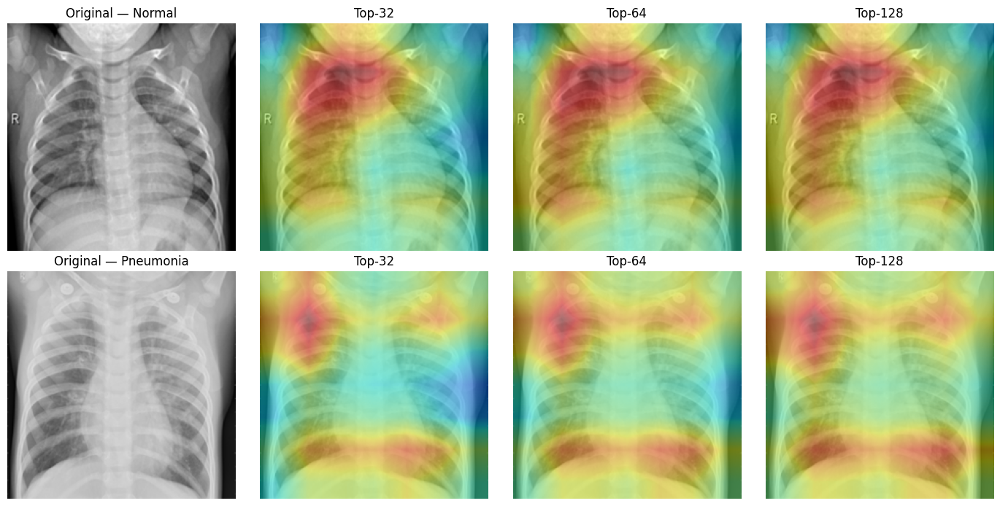


SCORE-CAM VALIDATION: MobileNetV2
Class: 0 | Runtime: 5.76 s
Class: 1 | Runtime: 0.87 s


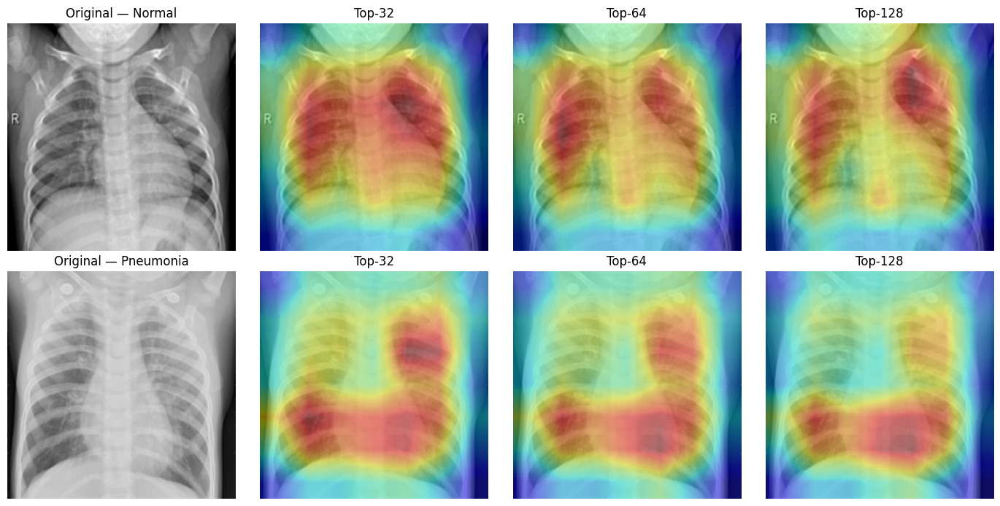


SCORE-CAM VALIDATION: VGG16
Class: 0 | Runtime: 3.64 s
Class: 1 | Runtime: 1.28 s


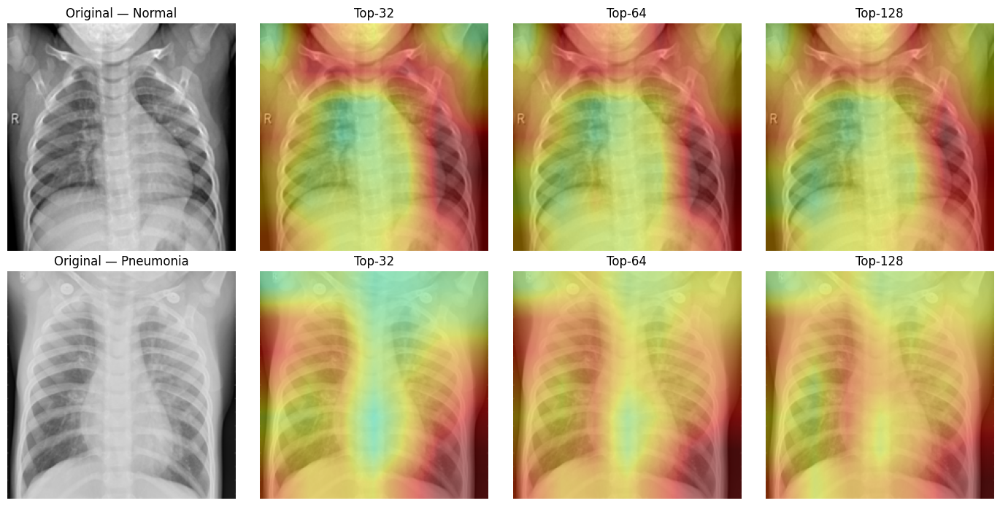


===== SCORE-CAM CHANNEL SENSITIVITY =====
      Model     Class  Channels   SSIM  Spearman    MAE
DenseNet121    Normal        32 0.9913    0.9853 0.0404
DenseNet121    Normal        64 0.9981    0.9945 0.0134
DenseNet121    Normal       128 1.0000    1.0000 0.0000
DenseNet121 Pneumonia        32 0.9727    0.9635 0.0827
DenseNet121 Pneumonia        64 0.9920    0.9733 0.0403
DenseNet121 Pneumonia       128 1.0000    1.0000 0.0000
MobileNetV2    Normal        32 0.9557    0.9395 0.0655
MobileNetV2    Normal        64 0.9857    0.9690 0.0370
MobileNetV2    Normal       128 1.0000    1.0000 0.0000
MobileNetV2 Pneumonia        32 0.9663    0.9636 0.0708
MobileNetV2 Pneumonia        64 0.9873    0.9846 0.0457
MobileNetV2 Pneumonia       128 1.0000    1.0000 0.0000
      VGG16    Normal        32 0.9776    0.9384 0.0432
      VGG16    Normal        64 0.9914    0.9695 0.0295
      VGG16    Normal       128 1.0000    1.0000 0.0000
      VGG16 Pneumonia        32 0.9632    0.8458 0.0674
     

In [41]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import gc
import time

from pathlib import Path
from scipy.stats import spearmanr
from skimage.metrics import structural_similarity as ssim

ROOT = Path("/kaggle/working/pneumonia_xai_workspace")
OUT = ROOT / "experiments" / "scorecam_validation"
OUT.mkdir(parents=True, exist_ok=True)

MODELS = ["DenseNet121", "MobileNetV2", "VGG16"]
TARGETS = {
    "DenseNet121": "relu",
    "MobileNetV2": "out_relu",
    "VGG16": "block5_pool"
}

TOP_K_VALUES = [32, 64, 128]
BATCH_SIZE = 16
EPS = 1e-8

def scorecam_variants(net, feature_net, image, target_class):
    x = np.asarray(image, dtype=np.float32)

    features, _ = feature_net(
        tf.convert_to_tensor(x[None]),
        training=False
    )

    acts = features[0].numpy().astype(np.float32)
    h, w, channels = acts.shape

    # Same variance-based selection as earlier experiments
    importance = acts.var(axis=(0, 1))
    k_max = min(max(TOP_K_VALUES), channels)

    selected = np.argsort(importance)[-k_max:]

    valid_channels = []
    masks = []

    for channel in selected:
        activation = tf.image.resize(
            acts[:, :, channel][None, ..., None],
            (224, 224)
        )[0, :, :, 0].numpy()

        activation -= activation.min()
        maximum = float(activation.max())

        if maximum <= EPS:
            continue

        masks.append(activation / maximum)
        valid_channels.append(int(channel))

    if not masks:
        raise RuntimeError("No valid Score-CAM masks")

    masked_images = (
        np.stack(masks, axis=0)[..., None]
        * x[None]
    ).astype(np.float32)

    probs = net.predict(
        masked_images,
        batch_size=BATCH_SIZE,
        verbose=0
    ).reshape(-1)

    scores = probs if target_class == 1 else 1.0 - probs

    maps = {}

    for k in TOP_K_VALUES:
        # Last k variance-ranked channels, matching
        # the earlier [-top_k:] selection
        n = min(k, len(valid_channels))
        indices = np.arange(len(valid_channels) - n,
                            len(valid_channels))

        selected_scores = scores[indices]
        weights = np.exp(
            selected_scores - selected_scores.max()
        )
        weights /= weights.sum()

        weighted_map = np.zeros(
            (h, w), dtype=np.float32
        )

        for weight, index in zip(weights, indices):
            channel = valid_channels[index]
            weighted_map += weight * acts[:, :, channel]

        weighted_map = tf.image.resize(
            weighted_map[None, ..., None],
            (224, 224)
        )[0, :, :, 0].numpy()

        weighted_map = np.maximum(weighted_map, 0)
        maximum = float(weighted_map.max())

        if maximum > EPS:
            weighted_map /= maximum

        maps[k] = weighted_map.astype(np.float32)

    return maps

def comparison_metrics(a, b):
    similarity = float(ssim(a, b, data_range=1.0))

    rho = (
        float(spearmanr(a.ravel(), b.ravel()).statistic)
        if a.std() > 1e-8 and b.std() > 1e-8
        else np.nan
    )

    return similarity, rho, float(np.mean(np.abs(a-b)))

records = []

for model_name in MODELS:
    print("\n" + "="*50)
    print("SCORE-CAM VALIDATION:", model_name)
    print("="*50)

    predictions = pd.read_csv(
        ROOT / "experiments" / "external_validation"
        / f"{model_name}_fold1_predictions.csv"
    )

    selected_rows = []

    for target_class in [0, 1]:
        candidates = predictions[
            (predictions["label_id"] == target_class)
            & (predictions["predicted_label"] == target_class)
        ]

        assert len(candidates) > 0

        selected_rows.append(
            candidates.sort_values("filepath").iloc[0]
        )

    tf.keras.backend.clear_session()

    net = tf.keras.models.load_model(
        CHECKPOINTS[model_name][1],
        compile=False
    )

    target_layer = TARGETS[model_name]

    feature_net = tf.keras.Model(
        inputs=net.inputs,
        outputs=[
            net.get_layer(target_layer).output,
            net.outputs[0]
        ]
    )

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))

    for row_idx, selected in enumerate(selected_rows):
        target_class = int(selected["label_id"])
        x = load_image(selected["filepath"])

        started = time.perf_counter()

        maps = scorecam_variants(
            net, feature_net, x, target_class
        )

        runtime = time.perf_counter() - started

        # Compare each variant against Top-128
        for k in TOP_K_VALUES:
            similarity, rho, mae = comparison_metrics(
                maps[k], maps[128]
            )

            records.append({
                "Model": model_name,
                "Class": (
                    "Normal" if target_class == 0
                    else "Pneumonia"
                ),
                "Channels": k,
                "Reference_Channels": 128,
                "SSIM": similarity,
                "Spearman": rho,
                "MAE": mae,
                "Runtime_For_All_Variants": runtime
            })

        axes[row_idx, 0].imshow(x)
        axes[row_idx, 0].set_title(
            "Original — " +
            ("Normal" if target_class == 0
             else "Pneumonia")
        )
        axes[row_idx, 0].axis("off")

        for j, k in enumerate(TOP_K_VALUES, 1):
            axes[row_idx, j].imshow(x)
            axes[row_idx, j].imshow(
                maps[k], cmap="jet",
                alpha=0.45, vmin=0, vmax=1
            )
            axes[row_idx, j].set_title(f"Top-{k}")
            axes[row_idx, j].axis("off")

        print(
            "Class:", target_class,
            "| Runtime:", round(runtime, 2), "s"
        )

    plt.tight_layout()
    plt.savefig(
        OUT / f"{model_name}_scorecam_channels.png",
        dpi=160
    )
    plt.show()
    plt.close(fig)

    del net, feature_net
    gc.collect()

results = pd.DataFrame(records)

results.to_csv(
    OUT / "scorecam_channel_sensitivity.csv",
    index=False
)

print("\n===== SCORE-CAM CHANNEL SENSITIVITY =====")
print(
    results[
        ["Model", "Class", "Channels",
         "SSIM", "Spearman", "MAE"]
    ].round(4).to_string(index=False)
)

print("\nSaved to:", OUT)


In [48]:

from pathlib import Path
import shutil
import subprocess
import json

ROOT = Path("/kaggle/working/pneumonia_xai_workspace")
SOURCE = ROOT / "experiments"

STAGING = Path("/kaggle/working/pneumonia_xai_dataset")
DATASET_ID = "haiderrasoolqadri/pneumonia-xai-experiments"

assert SOURCE.is_dir(), "Experiments folder not found"

# Remove the old symlink only, not its target
target = STAGING / "experiments"

if target.is_symlink():
    target.unlink()
elif target.exists():
    shutil.rmtree(target)

# Copy ONLY experiment outputs
shutil.copytree(SOURCE, target)

print("===== LOCAL VERIFICATION =====")

csv_files = list(target.rglob("*.csv"))
png_files = list(target.rglob("*.png"))
nrrd_files = list(target.rglob("*.nrrd"))

print("CSV files:", len(csv_files))
print("PNG figures:", len(png_files))
print("Lung masks:", len(nrrd_files))

assert csv_files, "No experiment CSV files copied"

# Existing segmentation weight symlink may also be
# ignored in an upload. Replace it with a real file.
weight_file = STAGING / "cxr_lung_segment_including_heart_512.pt"

if weight_file.is_symlink():
    original_weight = weight_file.resolve()
    weight_file.unlink()
    shutil.copy2(original_weight, weight_file)

# Ensure existing metadata points to same dataset
metadata = {
    "title": "Pneumonia XAI Experiments",
    "id": DATASET_ID,
    "licenses": [{"name": "other"}],
    "description": (
        "Private pneumonia XAI research experiment outputs, "
        "including FGSM, external validation, CAM faithfulness, "
        "stability, LAR, statistics, and validation figures."
    )
}

with open(STAGING / "dataset-metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("\nUploading NEW VERSION of existing dataset...")

result = subprocess.run(
    [
        "kaggle", "datasets", "version",
        "-p", str(STAGING),
        "-m", "Added all XAI experiment results and figures",
        "--dir-mode", "zip"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

if result.returncode != 0:
    raise RuntimeError("Dataset update failed")

print("\nSUCCESS: Dataset version update submitted!")
print("https://www.kaggle.com/datasets/" + DATASET_ID)


===== LOCAL VERIFICATION =====
CSV files: 61
PNG figures: 14
Lung masks: 24

Uploading NEW VERSION of existing dataset...
Starting upload for file experiments.zip
Upload successful: experiments.zip (15MB)
Starting upload for file cxr_lung_segment_including_heart_512.pt
Upload successful: cxr_lung_segment_including_heart_512.pt (70MB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/haiderrasoolqadri/pneumonia-xai-experiments


  0%|          | 0.00/15.2M [00:00<?, ?B/s]
 27%|██▋       | 4.17M/15.2M [00:00<00:00, 43.4MB/s]
100%|██████████| 15.2M/15.2M [00:00<00:00, 28.1MB/s]

  0%|          | 0.00/70.0M [00:00<?, ?B/s]
  5%|▍         | 3.34M/70.0M [00:00<00:01, 35.1MB/s]
 20%|█▉        | 13.9M/70.0M [00:00<00:00, 79.0MB/s]
 38%|███▊      | 26.6M/70.0M [00:00<00:00, 100MB/s] 
 52%|█████▏    | 36.1M/70.0M [00:00<00:00, 97.4MB/s]
 67%|██████▋   | 46.6M/70.0M [00:00<00:00, 102MB/s] 
 80%|████████  | 56.3M/70.0M [00:00<00:00, 93.7MB/s]
 93%|█████████